# 🎯 VCT Oddsmaker — Modelos de regresión y clasificación multiclase

**Predicción del margen de rondas y del tipo de victoria por mapa en el Valorant Champions Tour (2024–2026)**

*Aprendizaje de Máquina · Grupo C1 · Periodo 2026-2 · Entrega final (regresión + multiclase)*

Repositorio del proyecto: https://github.com/ANDRIX089/VCT_Oddsmaker

---

## ¿Qué hace este Colab?

En la entrega anterior predijimos **quién gana** cada mapa (clasificación binaria, `team_a_wins`) con GNB, Árbol, Random Forest y SVM, usando **solo información pre-match**. Los cuatro modelos quedaron alrededor del 57–59 % de accuracy en 2026, al nivel de la regla "gana el de mayor Elo". En esta entrega cerramos el proyecto con dos preguntas nuevas:

1. **Regresión:** nuestra variable objetivo es discreta (0/1), pero la regresión necesita un objetivo **continuo**. ¿Qué podemos predecir como número, y qué tan bien lo hacen los modelos de regresión vistos en clase (**Árbol de decisión regresor, Random Forest regresor y SVR**)?
2. **Clasificación multiclase:** ¿podemos pasar de "¿quién gana?" a "**¿quién gana y por cuánto?**", partiendo el resultado en varias clases, con los mismos cuatro clasificadores (GNB, Árbol, RF, SVM)?

Para cada parte **movemos hiperparámetros, registramos cada prueba** (qué se movió, por qué y qué pasó), comparamos los modelos y **escogemos los dos mejores**.

> **Regla que no cambia:** solo usamos variables **pre-match** (lo que se sabía antes de empezar el mapa). Con estadísticas del propio mapa los modelos acertarían más de 95 %, pero eso es *data leakage*: un casino no tiene esos datos cuando fija la cuota.

## Índice
1. Configuración y carga de datos
2. Variables pre-match (las mismas del notebook de clasificación)
3. ¿Cómo hacer regresión si la variable objetivo es discreta? → `round_diff`
4. Protocolo de evaluación, métricas de regresión y líneas base
5. Infraestructura de experimentos (el "cuaderno de laboratorio")
6. Modelo 1 — Árbol de decisión regresor
7. Modelo 2 — Random Forest regresor
8. Modelo 3 — SVR
9. Registro completo de pruebas de regresión
10. Curvas de aprendizaje
11. Comparación final y elección de los dos mejores modelos de regresión
12. Del margen predicho a la probabilidad y a la cuota
13. Clasificación multiclase: ¿quién gana y por cuánto?
14. Conclusiones

## 1. Configuración y carga de datos

La celda funciona **en Colab y en local**: busca primero el CSV local y, si no existe, lo descarga del repositorio (≈1.6 MB).

In [ ]:
#@title **Librerías y configuración global 📚**
import os, sys, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats

from sklearn.base import BaseEstimator, RegressorMixin, ClassifierMixin, clone
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVR, SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, KFold, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, make_scorer,
                             accuracy_score, f1_score, log_loss, roc_auc_score, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

SEED = 21                      # semilla fija: resultados reproducibles (la misma del notebook de clasificación)
np.random.seed(SEED)
NOMBRES = {"DT": "Árbol de decisión", "RF": "Random Forest", "SVR": "SVR"}            # regresión
COLORES = {"DT": "#edae49", "RF": "#d1495b", "SVR": "#66a182"}
NOMBRES_MC = {"GNB": "Gaussian NB", "DT": "Árbol de decisión", "RF": "Random Forest", "SVM": "SVM"}   # multiclase
COLORES_MC = {"GNB": "#00798c", "DT": "#edae49", "RF": "#d1495b", "SVM": "#66a182"}
print("Listo. Semilla:", SEED)

Listo. Semilla: 21


In [ ]:
#@title **CODE:** carga del dataset consolidado (un mapa por fila)
DATA_URL = "https://raw.githubusercontent.com/ANDRIX089/VCT_Oddsmaker/main/data/processed/maps_dataset.csv"
rutas_locales = ["maps_dataset.csv", os.path.join("..", "data", "processed", "maps_dataset.csv")]

ruta = next((r for r in rutas_locales if os.path.exists(r)), None)
if ruta:
    df = pd.read_csv(ruta);   print("Datos cargados desde local:", ruta)
else:
    df = pd.read_csv(DATA_URL); print("Datos cargados desde GitHub:", DATA_URL)

# Orden cronológico: no hay columna de fecha, pero match_id / game_id de vlr.gg crecen con el tiempo
df = df.sort_values(["match_id", "game_id"]).reset_index(drop=True)
print(f"\n{df.shape[0]:,} mapas x {df.shape[1]} columnas")
print("Mapas por temporada:", df["year"].value_counts().sort_index().to_dict())
df[["year", "region", "tournament", "map", "team_a", "team_b", "score_a", "score_b", "round_diff", "team_a_wins"]].head(3)

Datos cargados desde local: ../data/processed/maps_dataset.csv

3,267 mapas x 80 columnas
Mapas por temporada: {2024: 1104, 2025: 1277, 2026: 886}


,year,region,tournament,map,team_a,team_b,score_a,score_b,round_diff,team_a_wins
0,2024,Americas,Champions Tour 2024: Americas Kickoff,Breeze,NRG Esports,FURIA,13,10,3,1
1,2024,Americas,Champions Tour 2024: Americas Kickoff,Ascent,NRG Esports,FURIA,13,8,5,1
2,2024,Americas,Champions Tour 2024: Americas Kickoff,Bind,Cloud9,MIBR,13,11,2,1


## 2. Variables pre-match (las mismas del notebook de clasificación)

Para que los resultados de regresión, multiclase y clasificación binaria sean **comparables**, usamos **exactamente el mismo código** del notebook de clasificación: mismas variables, mismo Elo (K elegido con 2024–2025) y la misma regla de oro: *para predecir el mapa i solo se usa lo que se sabía antes de que empezara* (`shift(1)` en todos los historiales; el Elo se lee **antes** de actualizarse).

| Variable | Qué mide | Cómo se calcula sin fuga |
|---|---|---|
| `elo_diff` | Fuerza relativa de los equipos | Rating Elo secuencial: se lee **antes** de procesar el resultado del mapa y recién después se actualiza |
| `wr_all_diff` | Tasa de victoria histórica | Victorias previas / mapas previos, **suavizada** hacia 0.5 |
| `wr_10_diff` | Forma reciente | Igual, pero solo los últimos 10 mapas del equipo |
| `rd_10_diff` | Dominio reciente | Diferencia de rondas promedio en los últimos 10 mapas |
| `acs_10_diff`, `rating_10_diff` | Rendimiento individual reciente | Promedio móvil de los últimos 10 mapas |
| `pistol_10_diff`, `fk_10_diff` | Rondas pistola y *first kills* recientes | Promedio móvil de los últimos 10 mapas |
| `map_wr_diff` | Especialidad en **ese** mapa | Victorias previas del equipo en ese mapa, suavizadas hacia su tasa general |
| `hist_min` | Qué tan confiable es el historial | Mínimo de mapas previos entre los dos equipos |
| `picker` | Quién eligió el mapa | +1 si lo eligió A, −1 si lo eligió B, 0 si es *decider* |
| `playoffs`, `internacional`, `reg_*`, `map_*` | Contexto | Indicadores 0/1 |

Todas las variables relativas son **diferencias Team A − Team B**; los faltantes se rellenan con 0 ("sin información a favor de ninguno").

In [ ]:
#@title **CODE:** rating Elo secuencial (idéntico al notebook de clasificación)
def elo_secuencial(d, K=24, mov=True, base=1500.0):
    """Devuelve el Elo de A y de B ANTES de cada mapa. Recorre los mapas en orden cronológico."""
    elo = {}
    n = len(d); ea = np.empty(n); eb = np.empty(n)
    for i, (ta, tb, w, rd) in enumerate(zip(d.team_a_id.values, d.team_b_id.values,
                                            d.team_a_wins.values, d.round_diff.values)):
        ra, rb = elo.get(ta, base), elo.get(tb, base)
        ea[i], eb[i] = ra, rb                                  # <- se guarda ANTES de usar el resultado
        pa = 1 / (1 + 10 ** ((rb - ra) / 400))                  # prob. esperada de que gane A
        mult = (1 + abs(rd) / 13) if mov else 1.0              # una paliza mueve más el rating
        elo[ta] = ra + K * mult * (w - pa)
        elo[tb] = rb - K * mult * (w - pa)
    return ea, eb

# Igual que antes: K y el uso del margen se eligen SOLO con 2024-2025 (criterio: log-loss del propio Elo)
dev_mask = (df.year <= 2025).values
filas = []
for K in [12, 16, 24, 32]:
    for mov in [False, True]:
        ea, eb = elo_secuencial(df, K=K, mov=mov)
        p = 1 / (1 + 10 ** ((eb - ea) / 400))
        filas.append({"K": K, "margen": mov,
                      "log-loss (dev)": log_loss(df.team_a_wins[dev_mask], np.clip(p[dev_mask], 1e-3, 1-1e-3)),
                      "accuracy (dev)": accuracy_score(df.team_a_wins[dev_mask], p[dev_mask] > 0.5)})
elo_grid = pd.DataFrame(filas).sort_values("log-loss (dev)").reset_index(drop=True)
K_ELO, MOV_ELO = int(elo_grid.loc[0, "K"]), bool(elo_grid.loc[0, "margen"])
print(f"-> Elo elegido: K = {K_ELO}, con margen de victoria = {MOV_ELO}  (el mismo del notebook de clasificación)")

-> Elo elegido: K = 12, con margen de victoria = True  (el mismo del notebook de clasificación)


In [ ]:
#@title **CODE:** construcción de las variables pre-match (idéntico al notebook de clasificación)
SH, VENT = 5, 10        # suavizado (pseudo-mapas) y ventana de forma reciente

def construir_features(d, K_ELO=24, MOV=True, SH=5, VENT=10):
    d = d.copy(); d["idx"] = np.arange(len(d))
    # 1) formato largo: una fila por (mapa, equipo), desde la perspectiva de ese equipo
    partes = []
    for lado in ["a", "b"]:
        s = 1 if lado == "a" else -1
        partes.append(pd.DataFrame({
            "idx": d.idx, "lado": lado, "team": d[f"team_{lado}_id"], "map": d["map"],
            "win": d.team_a_wins if lado == "a" else 1 - d.team_a_wins,
            "rd": s * d.round_diff, "acs": d[f"acs_{lado}"], "rating": d[f"rating_{lado}"],
            "pistol": d[f"pistol_won_{lado}"] / 2,
            "fk": d[f"first_kills_{lado}"] - d[f"first_deaths_{lado}"]}))
    L = pd.concat(partes).sort_values(["idx", "lado"]).reset_index(drop=True)

    # 2) historial acumulado por equipo (shift => solo mapas ANTERIORES)
    g = L.groupby("team", sort=False)
    L["n_prev"] = g.cumcount()
    L["wins_prev"] = g["win"].cumsum() - L["win"]
    L["wr_all"] = (L["wins_prev"] + SH * 0.5) / (L["n_prev"] + SH)
    for c in ["win", "rd", "acs", "rating", "pistol", "fk"]:
        L["prev_" + c] = g[c].shift(1)
    g = L.groupby("team", sort=False)
    suma_w = g["prev_win"].transform(lambda s: s.rolling(VENT, min_periods=1).sum()).fillna(0)
    cuenta = g["prev_win"].transform(lambda s: s.rolling(VENT, min_periods=1).count()).fillna(0)
    suma_r = g["prev_rd"].transform(lambda s: s.rolling(VENT, min_periods=1).sum()).fillna(0)
    L["wr_10"] = (suma_w + SH * 0.5) / (cuenta + SH)
    L["rd_10"] = suma_r / (cuenta + SH)
    for c in ["acs", "rating", "pistol", "fk"]:
        L[c + "_10"] = g["prev_" + c].transform(lambda s: s.rolling(VENT, min_periods=3).mean())
    gm = L.groupby(["team", "map"], sort=False)
    L["n_prev_map"] = gm.cumcount()
    L["wins_prev_map"] = gm["win"].cumsum() - L["win"]
    L["map_wr"] = (L["wins_prev_map"] + 3 * L["wr_all"]) / (L["n_prev_map"] + 3)

    # 3) volver a formato ancho: una fila por mapa, diferencias A - B
    A = L[L.lado == "a"].set_index("idx"); B = L[L.lado == "b"].set_index("idx")
    X = pd.DataFrame(index=d.index)
    ea, eb = elo_secuencial(d, K=K_ELO, mov=MOV)
    X["elo_diff"] = ea - eb
    for c in ["wr_all", "wr_10", "rd_10", "acs_10", "rating_10", "pistol_10", "fk_10", "map_wr"]:
        X[c + "_diff"] = (A[c] - B[c]).reindex(X.index)
    X["hist_min"] = np.minimum(A["n_prev"], B["n_prev"]).reindex(X.index)
    X["picker"] = d.map_picked_by.map({"A": 1, "B": -1, "decider": 0}).values
    X["playoffs"] = (d.stage_group == "Playoffs/Bracket").astype(int).values
    X["internacional"] = (d.region == "International").astype(int).values
    for r in ["Americas", "EMEA", "Pacific", "China"]:
        X["reg_" + r] = (d.region == r).astype(int).values
    for m in sorted(d["map"].unique()):
        X["map_" + m] = (d["map"] == m).astype(int).values
    dif_cols = [c for c in X.columns if c.endswith("_diff")]
    X[dif_cols] = X[dif_cols].fillna(0.0)          # 0 = sin información a favor de nadie
    return X, d["team_a_wins"].astype(int)

X, y = construir_features(df, K_ELO=K_ELO, MOV=MOV_ELO, SH=SH, VENT=VENT)
print("Matriz de variables:", X.shape)

# Prueba anti-fuga (la misma del notebook anterior): recalcular a mano wr_all_diff usando SOLO mapas anteriores
def wr_manual(i, equipo):
    previos = df.iloc[:i]
    ja, jb = previos[previos.team_a_id == equipo], previos[previos.team_b_id == equipo]
    return (ja.team_a_wins.sum() + (1 - jb.team_a_wins).sum() + SH * 0.5) / (len(ja) + len(jb) + SH)
rng = np.random.default_rng(SEED)
ok = [np.isclose(wr_manual(i, df.team_a_id[i]) - wr_manual(i, df.team_b_id[i]), X.wr_all_diff[i])
      for i in rng.choice(np.arange(200, len(df)), size=8, replace=False)]
assert all(ok), "¡Hay una diferencia: revisar posible fuga!"
print("✔ Prueba anti-fuga superada: las variables de historial solo miran el pasado.")

Matriz de variables: (3267, 29)
✔ Prueba anti-fuga superada: las variables de historial solo miran el pasado.


## 3. ¿Cómo hacer regresión si la variable objetivo es discreta?

En clase vimos que **la regresión predice una cantidad continua**: se estima directamente $\hat{y}$ y no $P(y\mid x)$. Nuestra variable objetivo `team_a_wins` solo vale 0 o 1, así que para hacer regresión **no cambiamos las variables de entrada** (siguen siendo las mismas variables pre-match), sino la **variable objetivo**: necesitamos un resultado real del mapa que sea numérico y que siga diciendo quién ganó.

| Opción para la variable objetivo | ¿La usamos? | Por qué |
|---|---|---|
| `team_a_wins` (0/1) con un regresor | No | Es la misma clasificación "disfrazada": el regresor solo aprendería un número entre 0 y 1 (una probabilidad). No aporta nada nuevo. |
| La probabilidad o la cuota que dio el clasificador | **No** | No es un dato **observado** del partido: sería enseñarle a un modelo a imitar a otro modelo. No habría una "verdad" contra la cual medir el error. |
| **`round_diff` = rondas de A − rondas de B** | **Sí (elegida)** | Es un resultado **real** y numérico. Su **signo** dice quién ganó (`round_diff > 0` ⇔ gana A) y su **tamaño** dice por cuánto. Es justo lo que usan los casinos en el mercado de **hándicap de rondas** (p. ej. "A −4.5": A debe ganar por 5 o más). |
| Proporción de rondas de A (`score_a / total_rounds`) | Alternativa | Es casi la misma información que `round_diff` (otra escala); no la repetimos. |
| `total_rounds` o duración del mapa | No | No dice quién gana; sería otro problema distinto. |

**Ojo con la fuga:** `round_diff` es un dato *post-match*, por eso **solo** aparece como variable objetivo (*y*). Las variables de entrada (*X*) usan el margen de rondas **de mapas anteriores** (`rd_10_diff`), nunca el del mapa que se predice.

Además, del margen predicho se puede **volver** a la probabilidad de victoria y a la cuota (sección 12), así que la regresión no se desconecta del objetivo del proyecto: la amplía.

¿El signo de round_diff coincide SIEMPRE con team_a_wins? True
Mapas con |round_diff| < 2: 0  -> en VALORANT siempre se gana por 2 o más (13-11, o 2 de ventaja en overtime)
Media 0.19 | desviación estándar 5.93 | mediana de |round_diff| 5 | mapas con overtime 10.5 %


,mapas,media,desv_std,media_abs
year,,,,
2024,1104,0.43,5.83,5.20
2025,1277,0.30,5.99,5.29
2026,886,-0.27,5.95,5.27


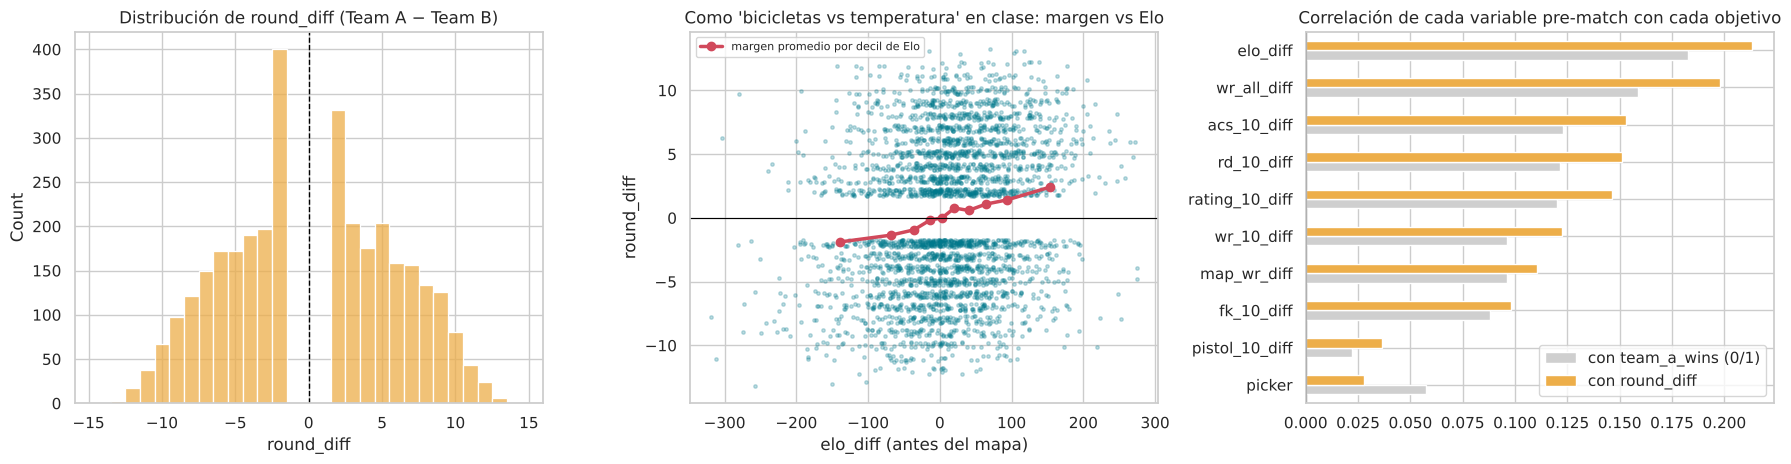

                con team_a_wins (0/1)  con round_diff
elo_diff                        0.183           0.213
wr_all_diff                     0.159           0.198
acs_10_diff                     0.123           0.153
rd_10_diff                      0.121           0.151
rating_10_diff                  0.120           0.146
wr_10_diff                      0.096           0.122
map_wr_diff                     0.096           0.110
fk_10_diff                      0.088           0.098
pistol_10_diff                  0.022           0.036
picker                          0.058           0.028


In [ ]:
#@title **CODE:** la nueva variable objetivo `round_diff` y su relación con las variables pre-match
y_reg = df["round_diff"].astype(float)
print("¿El signo de round_diff coincide SIEMPRE con team_a_wins?", bool(((y_reg > 0).astype(int) == y).all()))
print("Mapas con |round_diff| < 2:", int((y_reg.abs() < 2).sum()), " -> en VALORANT siempre se gana por 2 o más (13-11, o 2 de ventaja en overtime)")
print(f"Media {y_reg.mean():.2f} | desviación estándar {y_reg.std():.2f} | mediana de |round_diff| {y_reg.abs().median():.0f} | "
      f"mapas con overtime {df.overtime.mean()*100:.1f} %")
display(df.assign(abs_rd=y_reg.abs()).groupby("year").agg(mapas=("round_diff", "size"), media=("round_diff", "mean"),
        desv_std=("round_diff", "std"), media_abs=("abs_rd", "mean")).round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sns.histplot(y_reg, bins=np.arange(-14.5, 15.5, 1), color="#edae49", ax=axes[0])
axes[0].axvline(0, color="black", ls="--", lw=1); axes[0].set_title("Distribución de round_diff (Team A − Team B)"); axes[0].set_xlabel("round_diff")

axes[1].scatter(X["elo_diff"], y_reg + np.random.default_rng(SEED).uniform(-.3, .3, len(y_reg)), s=6, alpha=.25, color="#00798c")
dec = pd.qcut(X["elo_diff"], 10)
medias = pd.DataFrame({"elo": X["elo_diff"], "rd": y_reg}).groupby(dec, observed=True).mean()
axes[1].plot(medias.elo, medias.rd, "o-", color="#d1495b", lw=2.5, label="margen promedio por decil de Elo")
axes[1].axhline(0, color="black", lw=.8); axes[1].set_xlabel("elo_diff (antes del mapa)"); axes[1].set_ylabel("round_diff")
axes[1].set_title("Como 'bicicletas vs temperatura' en clase: margen vs Elo"); axes[1].legend(loc="upper left", fontsize=8)

principales = ["elo_diff", "wr_all_diff", "wr_10_diff", "rd_10_diff", "acs_10_diff", "rating_10_diff", "map_wr_diff", "fk_10_diff", "pistol_10_diff", "picker"]
corr = pd.DataFrame({"con team_a_wins (0/1)": X[principales].corrwith(y), "con round_diff": X[principales].corrwith(y_reg)}).sort_values("con round_diff")
corr.plot.barh(ax=axes[2], color=["#cfcfcf", "#edae49"]); axes[2].axvline(0, color="black", lw=.8)
axes[2].set_title("Correlación de cada variable pre-match con cada objetivo")
plt.tight_layout(); plt.show()
print(corr.sort_values("con round_diff", ascending=False).round(3).to_string())

### 📖 Lectura: ¿qué tan predecible es el margen?
- **`round_diff` contiene exactamente la misma información de "quién gana"** que `team_a_wins` (el signo coincide en los 3,267 mapas) **más** la del "por cuánto". Por eso es una buena variable objetivo para regresión.
- **La distribución es bimodal y tiene un hueco en el centro:** no existen márgenes de −1, 0 ni +1, y los valores más frecuentes son ±2 (13-11 y los overtime). La desviación estándar es de **≈ 6 rondas**.
- **Todas las variables pre-match se correlacionan un poco más con el margen que con el ganador** (por ejemplo `elo_diff`: 0.21 contra 0.18; `wr_all_diff`: 0.20 contra 0.16). El margen conserva más información por mapa que el 0/1. La excepción es `picker`: elegir el mapa ayuda a ganarlo, pero no a ganarlo por más rondas.
- **Aun así, la señal es pequeña.** En la nube de puntos, el margen promedio pasa de ≈ −2 rondas (los mapas con más desventaja de Elo) a ≈ +2.5 rondas (los de más ventaja), mientras que cada mapa individual se aleja de ese promedio unas ±6 rondas. **Esperamos un R² bajo (del orden de 0.03–0.05)**: igual que en clasificación, la mayor parte del resultado se decide dentro del mapa y no se puede saber antes.

## 4. Protocolo de evaluación, métricas de regresión y líneas base

**La partición es la misma del notebook de clasificación** (los mapas tienen orden temporal y no se puede entrenar con el futuro):

| Conjunto | Contenido | Para qué |
|---|---|---|
| **Train** | primer 75 % cronológico de 2024–2025 | ajustar el modelo |
| **Validación** | último 25 % de 2024–2025 | comparar configuraciones (aquí se mueven los hiperparámetros) |
| **Test** | **toda la temporada 2026** | se toca **una sola vez**, al final |

Dentro de *train* también hacemos **validación cruzada temporal** (`TimeSeriesSplit`, 5 pliegues de ventana creciente).

### Métricas de regresión (las de clase)

- **MSE** (error cuadrático medio): $MSE = \frac{1}{N}\sum_{i=1}^{N}(y_i-\hat{y}_i)^2$. Castiga mucho los errores grandes (por el cuadrado).
- **RMSE** $=\sqrt{MSE}$: misma tendencia que el MSE pero **en las unidades del problema** (rondas). Es nuestra métrica principal.
- **MAE** (error absoluto medio): $MAE=\frac{1}{N}\sum_{i=1}^{N}|y_i-\hat{y}_i|$. Todos los errores pesan igual; no es sensible a valores atípicos.
- **R²** $= 1-\frac{\sum (y_i-\hat{y}_i)^2}{\sum (y_i-\bar{y})^2}$: qué fracción de la variabilidad del margen explica el modelo. **R² = 0** es lo mismo que predecir siempre la media; **R² < 0** es peor que eso.

Como complemento (para comparar con la clasificación) reportamos el **acierto del ganador**: el porcentaje de mapas en los que el **signo** del margen predicho coincide con el real.

**Puntaje de selección** (menor es mejor):
$$\text{score} = \tfrac{1}{2}\big(\text{RMSE en validación} + \text{RMSE medio en CV temporal}\big)$$
Desempate: MAE de validación. Igual que en clasificación, usamos dos estimaciones para no dejarnos engañar por la suerte de un solo conjunto.

In [ ]:
#@title **CODE:** particiones temporales (idénticas al notebook de clasificación)
es_test = (df.year == 2026).values
idx_dev, idx_test = np.where(~es_test)[0], np.where(es_test)[0]
assert idx_dev.max() < idx_test.min(), "el test debe ser estrictamente posterior al desarrollo"
corte = int(len(idx_dev) * 0.75)
idx_tr, idx_va = idx_dev[:corte], idx_dev[corte:]

X_tr, X_va, X_te, X_dev = X.iloc[idx_tr], X.iloc[idx_va], X.iloc[idx_test], X.iloc[idx_dev]
r_tr, r_va, r_te, r_dev = y_reg.iloc[idx_tr], y_reg.iloc[idx_va], y_reg.iloc[idx_test], y_reg.iloc[idx_dev]   # objetivo de regresión
y_tr, y_va, y_te, y_dev = y.iloc[idx_tr], y.iloc[idx_va], y.iloc[idx_test], y.iloc[idx_dev]                   # quién ganó (0/1)

display(pd.DataFrame({
    "Conjunto": ["Train", "Validación", "Test (2026)"],
    "Mapas": [len(r_tr), len(r_va), len(r_te)],
    "round_diff medio": [r_tr.mean(), r_va.mean(), r_te.mean()],
    "desv. std round_diff": [r_tr.std(), r_va.std(), r_te.std()],
    "% gana Team A": [y_tr.mean() * 100, y_va.mean() * 100, y_te.mean() * 100]}).round(2))

,Conjunto,Mapas,round_diff medio,desv. std round_diff,% gana Team A
0,Train,1785,0.37,5.90,51.43
1,Validación,596,0.35,5.98,51.51
2,Test (2026),886,-0.27,5.95,47.18


In [ ]:
#@title **CODE:** métricas de regresión y reglas simples (las líneas base a superar)
def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

def metricas_reg(y_true, pred):
    """MSE, RMSE, MAE y R² (las métricas de clase) + acierto del ganador (signo del margen)."""
    y_true, pred = np.asarray(y_true, dtype=float), np.asarray(pred, dtype=float)
    return {"mse": mean_squared_error(y_true, pred), "rmse": rmse(y_true, pred), "mae": mean_absolute_error(y_true, pred),
            "r2": r2_score(y_true, pred), "acc_signo": float(np.mean((pred > 0) == (y_true > 0)))}

def regla_elo_deciles(X_ajuste, r_ajuste, X_pred):
    """Regla simple: predecir el margen PROMEDIO que tuvieron en el pasado los mapas con una ventaja de Elo parecida (mismo decil)."""
    cortes = np.quantile(X_ajuste["elo_diff"], np.linspace(0, 1, 11))[1:-1]
    medias = pd.Series(np.asarray(r_ajuste)).groupby(np.digitize(X_ajuste["elo_diff"], cortes)).mean()
    return medias.reindex(np.digitize(X_pred["elo_diff"], cortes)).values

filas = []
for nombre, (X_aj, r_aj, X_ev, r_ev) in {"Validación": (X_tr, r_tr, X_va, r_va), "Test 2026": (X_dev, r_dev, X_te, r_te)}.items():
    for base, pred in [("Siempre 0 (no sé quién gana)", np.zeros(len(r_ev))),
                       ("Siempre la media de round_diff", np.full(len(r_ev), r_aj.mean())),
                       ("Regla Elo: margen promedio de su decil de Elo", regla_elo_deciles(X_aj, r_aj, X_ev))]:
        m = metricas_reg(r_ev, pred)
        if base.startswith("Siempre 0"): m["acc_signo"] = np.nan          # no elige ganador
        filas.append({"Conjunto": nombre, "Línea base": base, **{k.upper() if k != "acc_signo" else "acierto ganador": v for k, v in m.items()}})
bases_reg = pd.DataFrame(filas)
display(bases_reg.round(4))

RMSE_CERO_VAL = bases_reg.query("Conjunto == 'Validación' and `Línea base`.str.startswith('Siempre 0')", engine="python").RMSE.iloc[0]
RMSE_ELO_VAL = bases_reg.query("Conjunto == 'Validación' and `Línea base`.str.startswith('Regla Elo')", engine="python").RMSE.iloc[0]

# ¿Qué tan grande es el "ruido" de la validación? error estándar del RMSE por bootstrap
rng = np.random.default_rng(SEED); e2 = (r_va.values - regla_elo_deciles(X_tr, r_tr, X_va)) ** 2
se_rmse = np.std([np.sqrt(e2[rng.integers(0, len(e2), len(e2))].mean()) for _ in range(1000)])
print(f"Error estándar (bootstrap) del RMSE con {len(r_va)} mapas de validación: ±{se_rmse:.2f} rondas.")
print("-> Diferencias de unas pocas centésimas de ronda entre configuraciones NO son distinguibles del azar.")

,Conjunto,Línea base,MSE,RMSE,MAE,R2,acierto ganador
0,Validación,Siempre 0 (no sé quién gana),35.8440,5.9870,5.2701,-0.0034,NaN
1,Validación,Siempre la media de round_diff,35.7237,5.9769,5.2590,-0.0000,0.5151
2,Validación,Regla Elo: margen promedio de su decil de Elo,34.5760,5.8801,5.0142,0.0321,0.5705
3,Test 2026,Siempre 0 (no sé quién gana),35.4639,5.9552,5.2652,-0.0020,NaN
4,Test 2026,Siempre la media de round_diff,35.7892,5.9824,5.2857,-0.0112,0.4718
5,Test 2026,Regla Elo: margen promedio de su decil de Elo,34.3201,5.8583,4.9971,0.0303,0.5847


Error estándar (bootstrap) del RMSE con 596 mapas de validación: ±0.13 rondas.
-> Diferencias de unas pocas centésimas de ronda entre configuraciones NO son distinguibles del azar.


### 📖 Lectura de las líneas base de regresión
- **"Siempre 0"** (no apostar por nadie) da un RMSE ≈ **5.99** en validación y **5.96** en 2026: es el error de no saber nada.
- **"Siempre la media"** tiene, por definición, R² ≈ 0.
- **La regla Elo por deciles** (predecir el margen promedio que tuvieron en el pasado los mapas con una ventaja de Elo parecida) baja el RMSE a **5.88** en validación y **5.86** en 2026 (R² ≈ 0.03) y acierta el ganador en el **58.5 %** de los mapas de 2026. Es la versión "regresión" de la regla "gana el de mayor Elo" de la entrega anterior, y **es la línea base seria a superar**.
- **Escala del problema:** el error estándar del RMSE en validación es de **±0.13 rondas**. Diferencias de centésimas entre configuraciones son ruido; por eso el veredicto "≈ igual" se usa para diferencias menores a 0.01 en el puntaje.

## 5. Infraestructura de experimentos (el "cuaderno de laboratorio")

Es la **misma lógica** del notebook de clasificación, adaptada a regresión. La función `prueba()`:

1. Toma como punto de partida la **mejor prueba guiada hasta ese momento** del modelo (*búsqueda codiciosa*: se mueve algo, se mide, y si mejora se convierte en la nueva referencia).
2. Aplica **solo los cambios indicados** (así sabemos exactamente qué provocó la diferencia).
3. Entrena en *train*, mide en *train* y en *validación*, y hace la **validación cruzada temporal**.
4. Guarda una fila en el registro con: `id`, la **referencia**, **qué cambió** (`valor anterior → valor nuevo`), la **hipótesis**, los hiperparámetros, las métricas (MSE, RMSE, MAE, R², acierto del ganador), el tiempo y un **veredicto** (▲ mejora / ≈ igual / ▼ empeora) comparando el puntaje de selección con la referencia. Una diferencia menor a ±0.01 rondas se considera ruido.

Las dos "perillas" de datos se mantienen:

- **`features`**: qué conjunto de variables usa el modelo (`elo` → 1 variable; `basica` → 4; `nucleo` → 8; `completa` → 29).
- **`espejo`**: el orden "Team A / Team B" es arbitrario. Con `espejo=True` el modelo se entrena con cada mapa **y con su versión invertida** (A↔B: se cambia el signo de las diferencias **y del margen**), y al predecir se promedian las dos lecturas: $\hat{y} = \frac{f(x) - f(x_{\text{invertido}})}{2}$.

La **brecha** (`gap`) ahora es **RMSE de validación − RMSE de train**: si es grande, el modelo memorizó el entrenamiento (sobreajuste).

> El **test no se mira en ningún momento** en las secciones 6 a 10.

In [ ]:
#@title **CODE:** conjuntos de variables, regresor "espejo" y fábrica de modelos
CONJUNTOS = {
    "elo":      ["elo_diff"],
    "basica":   ["elo_diff", "wr_all_diff", "wr_10_diff", "picker"],
    "nucleo":   ["elo_diff", "wr_all_diff", "wr_10_diff", "rd_10_diff", "acs_10_diff", "map_wr_diff", "picker", "hist_min"],
    "completa": list(X.columns),
}

class EspejoAB(RegressorMixin, BaseEstimator):
    """Envuelve cualquier regresor para hacerlo simétrico respecto al orden A/B."""
    def __init__(self, estimador=None, cols_antisim=None):
        self.estimador = estimador; self.cols_antisim = cols_antisim
    def _invertir(self, Xm):
        Xi = Xm.copy(); Xi[self.cols_antisim] = -Xi[self.cols_antisim]; return Xi
    def fit(self, Xm, ym):
        ym = np.asarray(ym, dtype=float)
        Xa = pd.concat([Xm, self._invertir(Xm)], ignore_index=True)
        self.estimador_ = clone(self.estimador).fit(Xa, np.concatenate([ym, -ym]))      # el margen invertido cambia de signo
        return self
    def predict(self, Xm):
        return (self.estimador_.predict(Xm) - self.estimador_.predict(self._invertir(Xm))) / 2

def construir_modelo(modelo, params):
    """Convierte un diccionario de parámetros en un regresor de sklearn + la lista de columnas que usa."""
    p = dict(params); fs = p.pop("features"); espejo = p.pop("espejo", False); cols = CONJUNTOS[fs]
    if   modelo == "DT":  est = DecisionTreeRegressor(random_state=SEED, **p)
    elif modelo == "RF":  est = RandomForestRegressor(random_state=SEED, n_jobs=-1, **p)
    elif modelo == "SVR": est = make_pipeline(StandardScaler(), SVR(**p))     # el escalado se ajusta solo con los datos de entrenamiento
    if espejo:
        est = EspejoAB(est, [c for c in cols if c.endswith("_diff") or c == "picker"])
    return est, cols

def desenvolver(est):
    """Devuelve el estimador interno (útil para dibujar el árbol o leer importancias)."""
    est = est.estimador_ if isinstance(est, EspejoAB) else est
    return est.steps[-1][1] if hasattr(est, "steps") else est

In [ ]:
#@title **CODE:** `prueba()` — entrena, evalúa y REGISTRA cada experimento de regresión
REGISTRO = []            # aquí se guarda absolutamente cada prueba
UMBRAL_RUIDO = 0.01      # diferencias de puntaje menores a 0.01 rondas se consideran ruido

def evaluar(est, cols):
    t0 = time.time()
    est.fit(X_tr[cols], r_tr)
    p_tr, p_va = est.predict(X_tr[cols]), est.predict(X_va[cols])
    dur = time.time() - t0
    rmses, maes = [], []                                    # validación cruzada temporal (ventana creciente)
    for a, b in TimeSeriesSplit(n_splits=5).split(X_tr):
        m = clone(est).fit(X_tr.iloc[a][cols], r_tr.iloc[a])
        pb = m.predict(X_tr.iloc[b][cols])
        rmses.append(rmse(r_tr.iloc[b], pb)); maes.append(mean_absolute_error(r_tr.iloc[b], pb))
    return {"tr": metricas_reg(r_tr, p_tr), "va": metricas_reg(r_va, p_va), "cv_rmse": np.mean(rmses), "cv_std": np.std(rmses),
            "cv_mae": np.mean(maes), "t": dur}

def mejor_guiada(modelo):
    cand = [r for r in REGISTRO if r["modelo"] == modelo and r["tipo"] == "guiada"]
    return min(cand, key=lambda r: r["score_sel"]) if cand else None     # en empate conserva la más antigua

def prueba(modelo, cambios=None, hipotesis="", params=None, tipo="guiada", verbose=True):
    """Si `params` es None, parte de la mejor prueba guiada del modelo y le aplica SOLO `cambios`."""
    ref = mejor_guiada(modelo)
    if params is None:
        params = {**ref["params"], **cambios}
        que_cambio = " | ".join(f"{k}: {ref['params'].get(k, '—')} → {v}" for k, v in cambios.items())
    else:
        que_cambio = "(configuración inicial)"
    est, cols = construir_modelo(modelo, params)
    r = evaluar(est, cols)
    score = (r["va"]["rmse"] + r["cv_rmse"]) / 2
    delta = score - ref["score_sel"] if ref else np.nan
    veredicto = "base" if ref is None else ("▲ mejora" if delta <= -UMBRAL_RUIDO else ("▼ empeora" if delta >= UMBRAL_RUIDO else "≈ igual"))
    n = sum(f["modelo"] == modelo for f in REGISTRO) + 1
    fila = {"id": f"{modelo}-{n:02d}", "modelo": modelo, "tipo": tipo, "referencia": ref["id"] if ref else "—",
            "cambió": que_cambio, "hipótesis": hipotesis, "params": params, "n_vars": len(cols),
            "train_rmse": r["tr"]["rmse"], "val_mse": r["va"]["mse"], "val_rmse": r["va"]["rmse"], "val_mae": r["va"]["mae"],
            "val_r2": r["va"]["r2"], "val_acc_signo": r["va"]["acc_signo"],
            "cv_rmse": r["cv_rmse"], "cv_std": r["cv_std"], "cv_mae": r["cv_mae"],
            "gap": r["va"]["rmse"] - r["tr"]["rmse"], "score_sel": score, "delta_vs_ref": delta, "veredicto": veredicto, "t_seg": r["t"]}
    REGISTRO.append(fila)
    if verbose:
        print(f"[{fila['id']}] {que_cambio:<52s} | RMSE train {fila['train_rmse']:.3f}  val {fila['val_rmse']:.3f}  "
              f"cv {fila['cv_rmse']:.3f}±{fila['cv_std']:.3f}  R² val {fila['val_r2']:+.3f} | {veredicto}")
    return fila

def registro_df(reg=None):
    d = pd.DataFrame(REGISTRO if reg is None else reg); d["params"] = d["params"].apply(lambda p: json.dumps(p, default=str)); return d

COLS_TABLA = ["id", "referencia", "cambió", "train_rmse", "val_rmse", "val_mae", "val_r2", "cv_rmse", "cv_std", "gap", "score_sel", "veredicto"]
def tabla_modelo(modelo, tipo="guiada"):
    r = registro_df(); r = r[(r.modelo == modelo) & (r.tipo == tipo)]
    return r[COLS_TABLA].round(4).reset_index(drop=True)

def mejor_global(modelo):
    """La mejor configuración del modelo entre TODAS sus pruebas (guiadas + barridos). Desempate: menor MAE de validación."""
    cand = [r for r in REGISTRO if r["modelo"] == modelo]
    return min(cand, key=lambda r: (round(r["score_sel"], 6), r["val_mae"]))

def grafica_pruebas(modelo, tipo="guiada"):
    r = registro_df(); r = r[(r.modelo == modelo) & (r.tipo == tipo)].reset_index(drop=True)
    mejor = r.score_sel.idxmin()
    fig, ax = plt.subplots(figsize=(12, 0.55 * len(r) + 2.2))
    pos = np.arange(len(r))[::-1]
    lo = max(0.0, min(r.val_rmse.min(), r.cv_rmse.min()) - 0.45); hi = min(max(r.val_rmse.max(), r.cv_rmse.max()) + 0.15, lo + 2.2)
    ax.barh(pos + 0.2, r.train_rmse, height=0.36, color="#c9c9c9", label="Train")
    ax.barh(pos - 0.2, r.val_rmse.clip(upper=hi), height=0.36, color=COLORES[modelo], label="Validación")
    ax.errorbar(r.cv_rmse.clip(upper=hi), pos - 0.2, xerr=r.cv_std, fmt="o", color="black", ms=4, lw=1, label="CV temporal (media ± std)")
    for p_, tr_, va_ in zip(pos, r.train_rmse, r.val_rmse):          # valores fuera de la escala
        if tr_ < lo: ax.text(lo + 0.01, p_ + 0.2, f"train = {tr_:.2f} ◀", va="center", fontsize=7)
        if va_ > hi: ax.text(hi - 0.01, p_ - 0.2, f"val = {va_:.2f} ▶", va="center", ha="right", fontsize=7, color="white", fontweight="bold")
    ax.axvline(RMSE_CERO_VAL, color="black", ls=":", lw=1, label=f"Siempre 0 ({RMSE_CERO_VAL:.3f})")
    ax.axvline(RMSE_ELO_VAL, color="#d1495b", ls="--", lw=1.2, label=f"Regla Elo por deciles ({RMSE_ELO_VAL:.3f})")
    ax.set_yticks(pos); ax.set_yticklabels([f"{i}  {c[:46]}" for i, c in zip(r.id, r["cambió"])], fontsize=8)
    ax.set_xlim(lo, hi); ax.text(lo + 0.02, pos[mejor] - 0.2, "★ mejor", va="center", fontsize=10, fontweight="bold", color="#b8860b")
    ax.set_xlabel("RMSE (rondas) — menor es mejor"); ax.set_title(f"{NOMBRES[modelo]} regresor — pruebas guiadas: ¿qué se movió y qué pasó?")
    ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

def resumen_modelo(modelo):
    guiadas = [r for r in REGISTRO if r["modelo"] == modelo and r["tipo"] == "guiada"]
    base, mj = guiadas[0], mejor_guiada(modelo)
    print(f"{NOMBRES[modelo]}: {len(guiadas)} pruebas guiadas.")
    print(f"  Base      {base['id']}: RMSE val {base['val_rmse']:.3f} | cv {base['cv_rmse']:.3f} | score {base['score_sel']:.4f} | brecha val-train {base['gap']:+.3f}")
    print(f"  Mejor     {mj['id']}: RMSE val {mj['val_rmse']:.3f} | cv {mj['cv_rmse']:.3f} | score {mj['score_sel']:.4f} | brecha val-train {mj['gap']:+.3f}")
    print(f"  Mejora del score vs la base: {mj['score_sel'] - base['score_sel']:+.4f} rondas")
    print(f"  Configuración: {json.dumps(mj['params'], default=str)}")
print("Infraestructura lista. Cada llamada a prueba() deja una fila en REGISTRO.")

Infraestructura lista. Cada llamada a prueba() deja una fila en REGISTRO.


## 6. Modelo 1 — Árbol de decisión regresor (`DecisionTreeRegressor`)

Un árbol regresor parte el espacio de variables igual que el clasificador, pero en cada hoja **predice el promedio** de `round_diff` de los mapas de entrenamiento que cayeron ahí (en vez de la clase más frecuente). Por eso su predicción es una "escalera".

**Hiperparámetros que movemos:**
- `max_depth`: profundidad máxima (principal control del sobreajuste).
- `min_samples_leaf`: mínimo de mapas por hoja (cada promedio se calcula con más mapas → más estable).
- `criterion`: cómo se mide la impureza al cortar. `squared_error` (minimiza el MSE), `absolute_error` (minimiza el MAE, predice medianas) o `friedman_mse`.
- `max_features`: variables candidatas en cada corte.
- `ccp_alpha`: poda por costo-complejidad (en regresión se mide en unidades de MSE, por eso los valores útiles son mayores que en clasificación).
- `features` y `espejo`.

**Hipótesis central:** igual que en clasificación, el árbol **sin límite memorizará** el entrenamiento (RMSE de train ≈ 0) y fallará mucho en validación; los mejores árboles serán **muy poco profundos o muy podados**.

Primero repetimos el ejercicio de clase (bicicletas vs temperatura) con **una sola variable** (`elo_diff`) y dos profundidades.

Si A tiene -150 de Elo frente a B -> margen predicho: árbol prof. 2: -2.01 rondas | árbol prof. 10: +7.00 rondas
Si A tiene +0 de Elo frente a B -> margen predicho: árbol prof. 2: -0.18 rondas | árbol prof. 10: +0.11 rondas
Si A tiene +150 de Elo frente a B -> margen predicho: árbol prof. 2: +2.81 rondas | árbol prof. 10: +2.89 rondas


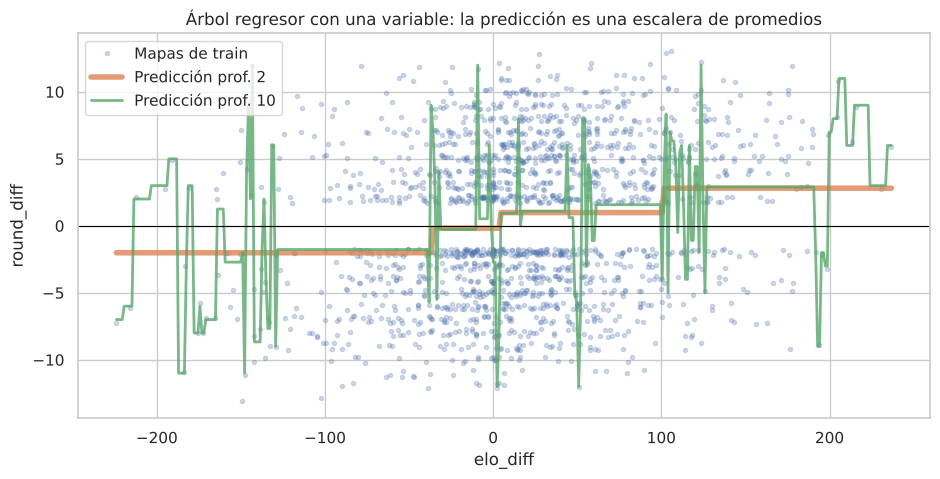

MSE árbol prof. 2  : 33.753 (+/- 2.080)  ->  RMSE ≈ 5.810 rondas
MSE árbol prof. 10 : 39.775 (+/- 2.827)  ->  RMSE ≈ 6.307 rondas


In [ ]:
#@title **CODE:** como en clase — árbol regresor con UNA variable y dos profundidades (2 vs 10)
max_depth_1, max_depth_2 = 2, 10
X1_tr = X_tr[["elo_diff"]]
regressor   = DecisionTreeRegressor(max_depth=max_depth_1, random_state=SEED).fit(X1_tr, r_tr)
regressorSA = DecisionTreeRegressor(max_depth=max_depth_2, random_state=SEED).fit(X1_tr, r_tr)

for elo_ej in [-150, 0, 150]:
    ej = pd.DataFrame({"elo_diff": [elo_ej]})
    print(f"Si A tiene {elo_ej:+d} de Elo frente a B -> margen predicho: árbol prof. {max_depth_1}: {regressor.predict(ej)[0]:+.2f} rondas | "
          f"árbol prof. {max_depth_2}: {regressorSA.predict(ej)[0]:+.2f} rondas")

x_value = pd.DataFrame({"elo_diff": np.linspace(X1_tr.elo_diff.min(), X1_tr.elo_diff.max(), 400)})
plt.figure(figsize=(11, 5))
plt.plot(X1_tr.elo_diff, r_tr + np.random.default_rng(SEED).uniform(-.3, .3, len(r_tr)), "o", ms=3, alpha=.25, label="Mapas de train")
plt.plot(x_value.elo_diff, regressor.predict(x_value), lw=4, alpha=.8, label=f"Predicción prof. {max_depth_1}")
plt.plot(x_value.elo_diff, regressorSA.predict(x_value), lw=2, alpha=.8, label=f"Predicción prof. {max_depth_2}")
plt.axhline(0, color="black", lw=.8); plt.xlabel("elo_diff"); plt.ylabel("round_diff"); plt.legend()
plt.title("Árbol regresor con una variable: la predicción es una escalera de promedios"); plt.show()

# MSE con validación cruzada, exactamente como en el notebook de clase (KFold de 10 pliegues con mezcla).
# OJO: aquí la mezcla es solo para replicar el ejercicio de clase; para ELEGIR hiperparámetros usamos el protocolo temporal.
for nombre, est in [(f"prof. {max_depth_1}", regressor), (f"prof. {max_depth_2}", regressorSA)]:
    s = cross_val_score(est, X1_tr, r_tr, cv=KFold(10, shuffle=True, random_state=SEED), scoring=make_scorer(mean_squared_error))
    print(f"MSE árbol {nombre:9s}: {np.mean(s):.3f} (+/- {np.std(s):.3f})  ->  RMSE ≈ {np.sqrt(np.mean(s)):.3f} rondas")

In [ ]:
#@title **EXPERIMENTOS DT regresor** — cada línea es una prueba registrada
prueba("DT", params=dict(features="nucleo", criterion="squared_error", max_depth=None, min_samples_leaf=1, max_features=None, ccp_alpha=0.0, espejo=False),
       hipotesis="Línea base: árbol regresor sin ningún límite (memorizará el entrenamiento).")

ensayos_dt = [
    (dict(max_depth=3),                 "Limitar la profundidad a 3 para frenar la memorización."),
    (dict(max_depth=2),                 "Aún más simple: solo 2 niveles (4 hojas)."),
    (dict(max_depth=5),                 "Probar el otro lado: ¿un poco más de profundidad ayuda?"),
    (dict(min_samples_leaf=40),         "Exigir al menos 40 mapas por hoja: cada promedio es más estable."),
    (dict(min_samples_leaf=100),        "Hojas aún más grandes (100 mapas)."),
    (dict(criterion="absolute_error"),  "Cortar minimizando el MAE (predice medianas, menos sensible a palizas 13-0)."),
    (dict(criterion="friedman_mse"),    "Criterio de Friedman (variante del MSE que premia cortes que separan bien los promedios)."),
    (dict(max_features="sqrt"),         "Considerar solo √p variables por corte."),
    (dict(ccp_alpha=0.3),               "Poda por costo-complejidad: cortar ramas que reducen poco el MSE."),
    (dict(features="basica"),           "Dar menos variables al árbol (4)."),
    (dict(features="completa"),         "Dar todas las variables (29), incluyendo mapa, región y fase."),
    (dict(espejo=True),                 "Árbol simétrico: entrenar con el mapa y su versión A↔B (margen con signo invertido)."),
]
for cambios, hip in ensayos_dt:
    prueba("DT", cambios, hip)

[DT-01] (configuración inicial)                              | RMSE train 0.499  val 8.167  cv 8.276±0.232  R² val -0.867 | base
[DT-02] max_depth: None → 3                                  | RMSE train 5.688  val 5.880  cv 6.012±0.172  R² val +0.032 | ▲ mejora
[DT-03] max_depth: 3 → 2                                     | RMSE train 5.730  val 5.826  cv 5.909±0.160  R² val +0.050 | ▲ mejora
[DT-04] max_depth: 2 → 5                                     | RMSE train 5.487  val 6.171  cv 6.441±0.399  R² val -0.066 | ▼ empeora
[DT-05] min_samples_leaf: 1 → 40                             | RMSE train 5.730  val 5.826  cv 5.899±0.143  R² val +0.050 | ≈ igual
[DT-06] min_samples_leaf: 40 → 100                           | RMSE train 5.730  val 5.826  cv 5.893±0.130  R² val +0.050 | ≈ igual
[DT-07] criterion: squared_error → absolute_error            | RMSE train 5.859  val 6.044  cv 6.098±0.278  R² val -0.023 | ▼ empeora
[DT-08] criterion: squared_error → friedman_mse              | RMSE train

,id,referencia,cambió,train_rmse,val_rmse,val_mae,val_r2,cv_rmse,cv_std,gap,score_sel,veredicto
0,DT-01,—,(configuración inicial),0.4994,8.1672,6.6862,-0.8672,8.2759,0.2321,7.6678,8.2215,base
1,DT-02,DT-01,max_depth: None → 3,5.6883,5.8803,5.1221,0.0321,6.0122,0.1723,0.1920,5.9462,▲ mejora
2,DT-03,DT-02,max_depth: 3 → 2,5.7300,5.8263,5.0276,0.0498,5.9092,0.1602,0.0963,5.8678,▲ mejora
3,DT-04,DT-03,max_depth: 2 → 5,5.4868,6.1713,5.2094,-0.0661,6.4411,0.3995,0.6844,6.3062,▼ empeora
4,DT-05,DT-03,min_samples_leaf: 1 → 40,5.7300,5.8263,5.0276,0.0498,5.8986,0.1433,0.0963,5.8624,≈ igual
5,DT-06,DT-05,min_samples_leaf: 40 → 100,5.7300,5.8263,5.0276,0.0498,5.8930,0.1304,0.0963,5.8597,≈ igual
6,DT-07,DT-06,criterion: squared_error → absolute_error,5.8587,6.0439,4.9983,-0.0225,6.0980,0.2781,0.1852,6.0709,▼ empeora
7,DT-08,DT-06,criterion: squared_error → friedman_mse,5.7300,5.8263,5.0276,0.0498,5.8930,0.1304,0.0963,5.8597,≈ igual
8,DT-09,DT-06,max_features: None → sqrt,5.7551,5.9208,5.0901,0.0187,5.9013,0.1470,0.1657,5.9110,▼ empeora
9,DT-10,DT-06,ccp_alpha: 0.0 → 0.3,5.7300,5.8263,5.0276,0.0498,5.9074,0.1078,0.0963,5.8668,≈ igual


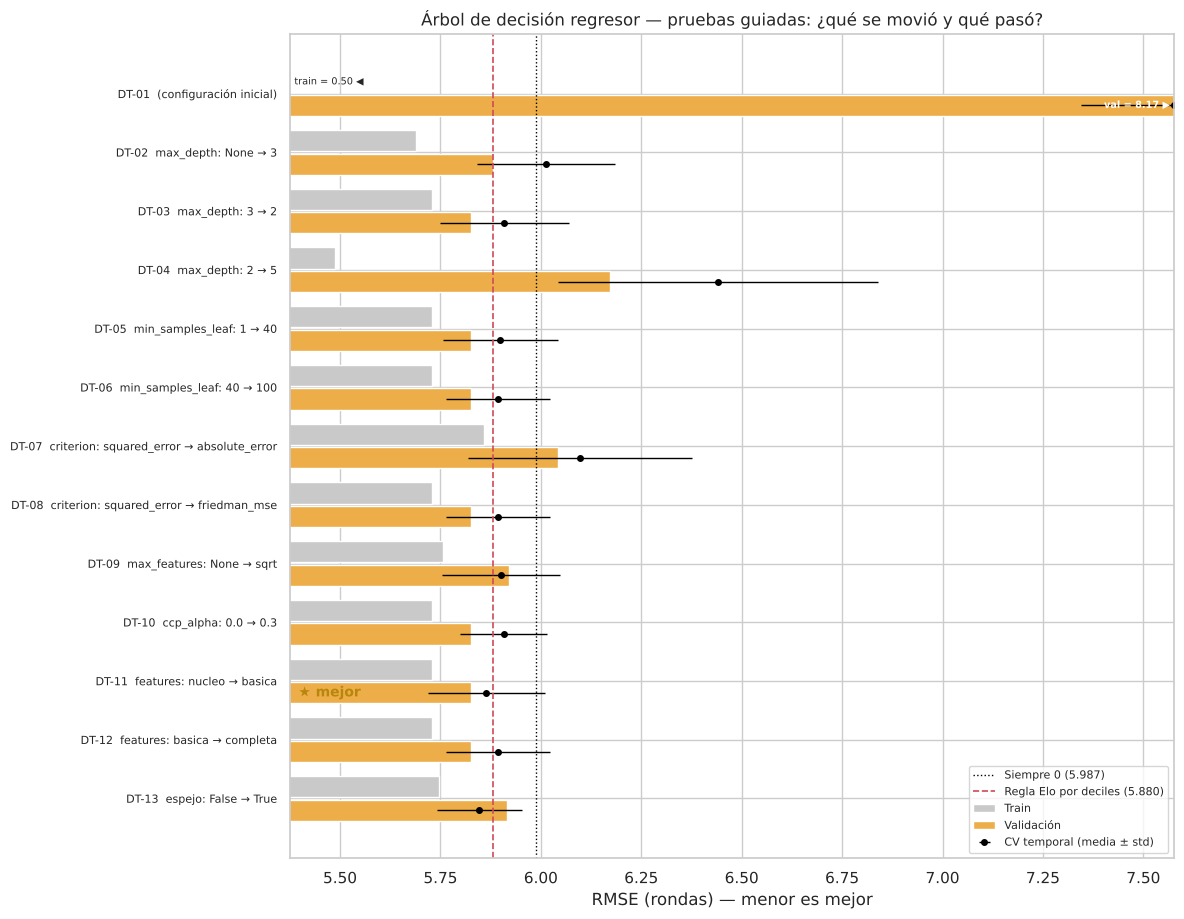

Árbol de decisión: 13 pruebas guiadas.
  Base      DT-01: RMSE val 8.167 | cv 8.276 | score 8.2215 | brecha val-train +7.668
  Mejor     DT-11: RMSE val 5.826 | cv 5.864 | score 5.8453 | brecha val-train +0.096
  Mejora del score vs la base: -2.3762 rondas
  Configuración: {"features": "basica", "criterion": "squared_error", "max_depth": 2, "min_samples_leaf": 100, "max_features": null, "ccp_alpha": 0.0, "espejo": false}


In [ ]:
#@title **TABLA Y GRÁFICA** de las pruebas guiadas del árbol regresor
display(tabla_modelo("DT"))
grafica_pruebas("DT")
resumen_modelo("DT")

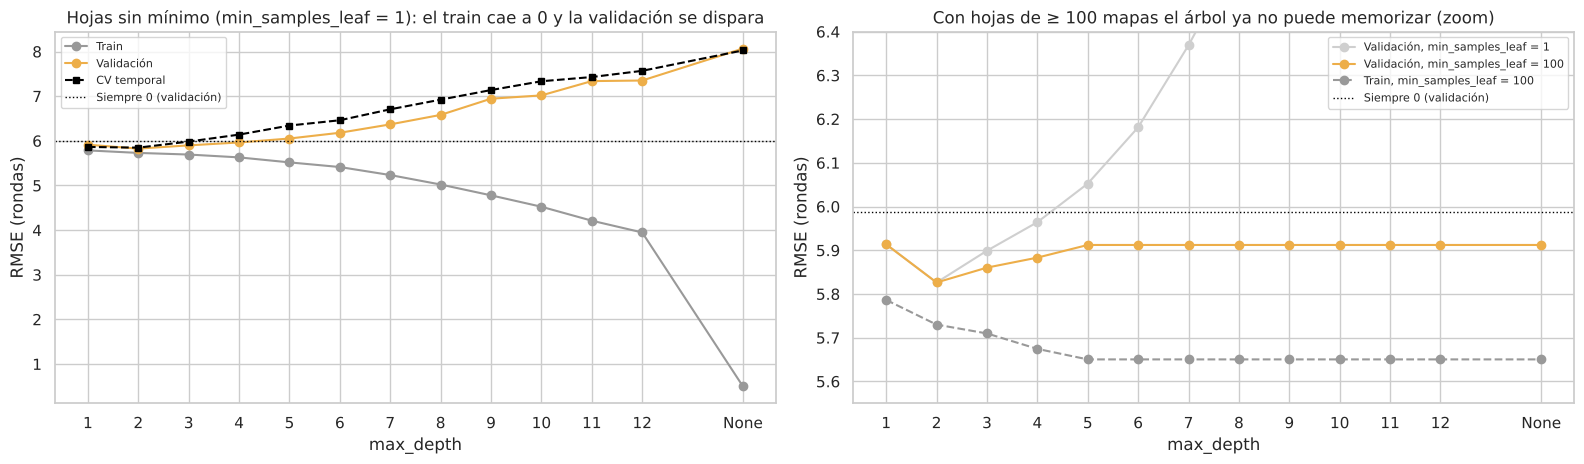

,0,1,2,3,4,5,6,7,8,9,10,11,12
max_depth,1,2,3,4,5,6,7,8,9,10,11,12,None
RMSE val (leaf=1),5.914,5.826,5.899,5.964,6.052,6.181,6.369,6.581,6.944,7.018,7.339,7.352,8.068
R² val (leaf=1),0.021,0.05,0.026,0.004,-0.025,-0.07,-0.135,-0.213,-0.35,-0.379,-0.508,-0.513,-0.822
RMSE val (leaf=100),5.914,5.826,5.86,5.883,5.912,5.912,5.912,5.912,5.912,5.912,5.912,5.912,5.912
R² val (leaf=100),0.021,0.05,0.039,0.031,0.022,0.022,0.022,0.022,0.022,0.022,0.022,0.022,0.022


In [ ]:
#@title **BARRIDO DT:** curva de sobreajuste — RMSE en train / validación / CV según `max_depth`
# Dos barridos: (a) hojas sin mínimo (min_samples_leaf = 1, como en clase) y (b) con el mínimo de la mejor prueba guiada
MSL_MEJOR = mejor_guiada("DT")["params"]["min_samples_leaf"]
profundidades = list(range(1, 13)) + [None]
for msl in [1, MSL_MEJOR]:
    for d in profundidades:
        prueba("DT", dict(max_depth=d, min_samples_leaf=msl), f"Barrido de max_depth = {d} con min_samples_leaf = {msl}", tipo="barrido", verbose=False)

r = registro_df(); b = r[(r.modelo == "DT") & (r.tipo == "barrido")].copy()
b["depth"] = b["params"].apply(lambda s: json.loads(s)["max_depth"]); b["depth_num"] = b["depth"].fillna(14).astype(float)
b["msl"] = b["params"].apply(lambda s: json.loads(s)["min_samples_leaf"])
b1, b2 = b[b.msl == 1], b[b.msl == MSL_MEJOR]
ticks = (list(range(1, 13)) + [14], [str(i) for i in range(1, 13)] + ["None"])
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
ax[0].plot(b1.depth_num, b1.train_rmse, "o-", color="#999999", label="Train"); ax[0].plot(b1.depth_num, b1.val_rmse, "o-", color=COLORES["DT"], label="Validación")
ax[0].plot(b1.depth_num, b1.cv_rmse, "s--", color="black", ms=4, label="CV temporal")
ax[0].axhline(RMSE_CERO_VAL, color="black", ls=":", lw=1, label="Siempre 0 (validación)")
ax[0].set_xticks(*ticks); ax[0].set_xlabel("max_depth"); ax[0].set_ylabel("RMSE (rondas)")
ax[0].set_title("Hojas sin mínimo (min_samples_leaf = 1): el train cae a 0 y la validación se dispara"); ax[0].legend(fontsize=8)
ax[1].plot(b1.depth_num, b1.val_rmse, "o-", color="#cfcfcf", label="Validación, min_samples_leaf = 1")
ax[1].plot(b2.depth_num, b2.val_rmse, "o-", color=COLORES["DT"], label=f"Validación, min_samples_leaf = {MSL_MEJOR}")
ax[1].plot(b2.depth_num, b2.train_rmse, "o--", color="#999999", label=f"Train, min_samples_leaf = {MSL_MEJOR}")
ax[1].axhline(RMSE_CERO_VAL, color="black", ls=":", lw=1, label="Siempre 0 (validación)")
ax[1].set_ylim(5.55, 6.4); ax[1].set_xticks(*ticks); ax[1].set_xlabel("max_depth"); ax[1].set_ylabel("RMSE (rondas)")
ax[1].set_title(f"Con hojas de ≥ {MSL_MEJOR} mapas el árbol ya no puede memorizar (zoom)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
display(pd.DataFrame({"max_depth": [str(d) for d in profundidades], "RMSE val (leaf=1)": b1.val_rmse.values, "R² val (leaf=1)": b1.val_r2.values,
                      f"RMSE val (leaf={MSL_MEJOR})": b2.val_rmse.values, f"R² val (leaf={MSL_MEJOR})": b2.val_r2.values}).round(3).T)

Mejor árbol de todas las pruebas: DT-15 — {"features": "basica", "criterion": "squared_error", "max_depth": 2, "min_samples_leaf": 1, "max_features": null, "ccp_alpha": 0.0, "espejo": false}
Hojas: 4 | profundidad real: 2

|--- elo_diff <= 4.0
|   |--- wr_all_diff <= -0.1
|   |   |--- value: [-2.9]
|   |--- wr_all_diff >  -0.1
|   |   |--- value: [-0.5]
|--- elo_diff >  4.0
|   |--- elo_diff <= 100.7
|   |   |--- value: [1.0]
|   |--- elo_diff >  100.7
|   |   |--- value: [2.8]



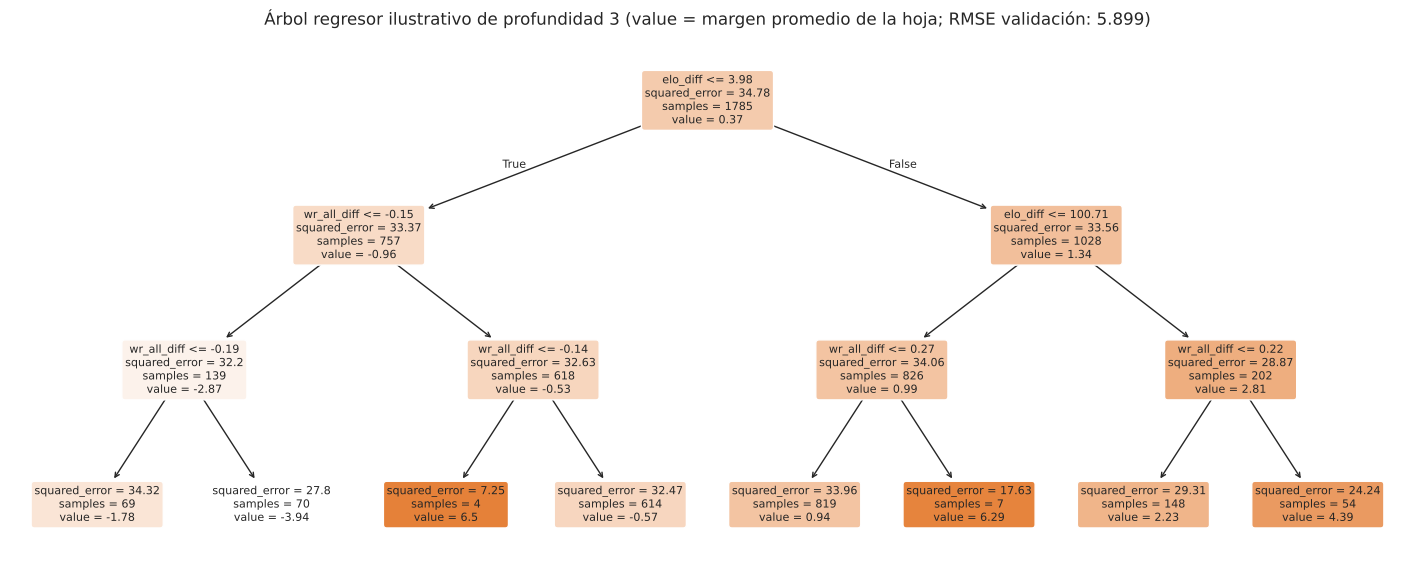

In [ ]:
#@title **GRÁFICA:** el mejor árbol regresor
cfg = mejor_global("DT"); est, cols = construir_modelo("DT", cfg["params"]); est.fit(X_tr[cols], r_tr)
print(f"Mejor árbol de todas las pruebas: {cfg['id']} — {json.dumps(cfg['params'], default=str)}")
print(f"Hojas: {desenvolver(est).get_n_leaves()} | profundidad real: {desenvolver(est).get_depth()}\n")
print(export_text(desenvolver(est), feature_names=cols, decimals=1))

# Árbol ilustrativo de profundidad 3 (sin espejo) para ver cómo "piensa" un árbol regresor: cada hoja muestra el margen promedio (value)
p_ilus = {**cfg["params"], "max_depth": 3, "espejo": False, "ccp_alpha": 0.0, "min_samples_leaf": 1}
est3, cols3 = construir_modelo("DT", p_ilus); est3.fit(X_tr[cols3], r_tr); arbol3 = desenvolver(est3)
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(arbol3, feature_names=cols3, filled=True, rounded=True, fontsize=8, precision=2, ax=ax)
ax.set_title(f"Árbol regresor ilustrativo de profundidad 3 (value = margen promedio de la hoja; RMSE validación: {rmse(r_va, est3.predict(X_va[cols3])):.3f})"); plt.show()

### 📖 Lectura de los resultados del Árbol regresor
- **El ejercicio de clase se repite igual:** con una sola variable, el árbol de profundidad 10 predice cosas absurdas (si A tiene **150 puntos menos** de Elo, ¡predice que **gana por 7 rondas**!) porque memorizó unos pocos mapas de esa zona. El de profundidad 2 predice −2 rondas, algo razonable. En validación cruzada, el MSE del árbol de profundidad 2 (≈ 33.8) es menor que el del de profundidad 10 (≈ 39.8), igual que en el ejemplo de las bicicletas.
- **Sobreajuste extremo en la línea base:** sin límites, el árbol tiene RMSE ≈ **0.5 en train** y ≈ **8.2 en validación** (R² = −0.87). Es **peor que predecir siempre 0** (5.99): memoriza el pasado y no generaliza. En el barrido con hojas sin mínimo se ve la curva clásica: el train cae hacia 0 y la validación se dispara al aumentar la profundidad.
- **Limitar la profundidad fue lo que más ayudó:** con `max_depth = 2` (solo 4 hojas) el RMSE de validación baja a **5.83** (R² ≈ 0.05). Con profundidad 5 vuelve a empeorar (6.17).
- **Varias pruebas dieron exactamente el mismo resultado** (`min_samples_leaf`, `friedman_mse`, `ccp_alpha`, más o menos variables): el árbol de 4 hojas ya usaba siempre los mismos cortes, así que esos cambios no tenían nada que mover. Solo cambió un poco la CV.
- **`absolute_error` empeora el RMSE pero mejora el MAE** (4.998, el mejor de las pruebas guiadas): cada criterio optimiza su propia métrica. Ese criterio predice medianas, así que se equivoca por menos rondas en el mapa típico pero más en las palizas.
- **El mejor árbol es una tabla de 4 casos:** si A no tiene ventaja de Elo y además tiene peor historial, se espera que pierda por ≈ 3 rondas; con ventaja de Elo moderada gana por ≈ 1, y con más de ≈ 100 puntos de ventaja gana por ≈ 3. Es, otra vez, **la regla del Elo** expresada en rondas.

## 7. Modelo 2 — Random Forest regresor (`RandomForestRegressor`)

Promedia muchos árboles regresores entrenados con muestras distintas de los mapas (*bootstrap*) y subconjuntos de variables. Cada árbol se equivoca distinto y el promedio cancela parte del ruido.

**Hiperparámetros que movemos:**
- `n_estimators`: número de árboles.
- `max_depth` y `min_samples_leaf`: complejidad de cada árbol.
- `max_features`: variables por corte (en el regresor de sklearn el valor por defecto es **todas**, 1.0).
- `max_samples`: fracción de mapas que ve cada árbol.
- `features` y `espejo`.

**Hipótesis central:** el bosque por defecto (árboles sin límite) sobreajusta aunque promedie; **hojas grandes y menos variables por corte** deberían acercarlo a la regla del Elo. Como en clasificación, esperamos que *más variables no ayude*.

In [ ]:
#@title **EXPERIMENTOS RF regresor** — cada línea es una prueba registrada
prueba("RF", params=dict(features="nucleo", n_estimators=100, max_depth=None, min_samples_leaf=1, max_features=1.0, espejo=False),
       hipotesis="Línea base: bosque regresor con valores por defecto (100 árboles sin límite, todas las variables en cada corte).")

ensayos_rf = [
    (dict(min_samples_leaf=10),   "Hojas con al menos 10 mapas: cada árbol deja de memorizar."),
    (dict(min_samples_leaf=30),   "Hojas con al menos 30 mapas."),
    (dict(min_samples_leaf=80),   "Hojas con al menos 80 mapas (árboles muy suaves)."),
    (dict(max_depth=6),           "Limitar la profundidad a 6."),
    (dict(max_depth=3),           "Limitar la profundidad a 3."),
    (dict(max_features="sqrt"),   "Cada corte ve solo √p variables: árboles más distintos entre sí."),
    (dict(max_features=0.5),      "Cada corte ve la mitad de las variables."),
    (dict(n_estimators=300),      "Más árboles: menos varianza en el promedio."),
    (dict(max_samples=0.6),       "Cada árbol ve solo el 60 % de los mapas: árboles más diversos."),
    (dict(features="basica"),     "Dar solo 4 variables al bosque."),
    (dict(features="completa"),   "Dar las 29 variables al bosque."),
    (dict(espejo=True),           "Bosque simétrico: entrenar con el mapa y su versión A↔B."),
]
for cambios, hip in ensayos_rf:
    prueba("RF", cambios, hip)

[RF-01] (configuración inicial)                              | RMSE train 2.304  val 5.924  cv 6.086±0.179  R² val +0.018 | base
[RF-02] min_samples_leaf: 1 → 10                             | RMSE train 4.672  val 5.859  cv 5.933±0.142  R² val +0.039 | ▲ mejora
[RF-03] min_samples_leaf: 10 → 30                            | RMSE train 5.343  val 5.845  cv 5.881±0.140  R² val +0.044 | ▲ mejora
[RF-04] min_samples_leaf: 30 → 80                            | RMSE train 5.597  val 5.836  cv 5.830±0.147  R² val +0.047 | ▲ mejora
[RF-05] max_depth: None → 6                                  | RMSE train 5.602  val 5.836  cv 5.830±0.146  R² val +0.047 | ≈ igual
[RF-06] max_depth: 6 → 3                                     | RMSE train 5.659  val 5.838  cv 5.831±0.145  R² val +0.046 | ≈ igual
[RF-07] max_features: 1.0 → sqrt                             | RMSE train 5.659  val 5.837  cv 5.822±0.151  R² val +0.046 | ≈ igual
[RF-08] max_features: sqrt → 0.5                             | RMSE train 5.

,id,referencia,cambió,train_rmse,val_rmse,val_mae,val_r2,cv_rmse,cv_std,gap,score_sel,veredicto
0,RF-01,—,(configuración inicial),2.3036,5.9240,5.0967,0.0176,6.0857,0.1786,3.6204,6.0048,base
1,RF-02,RF-01,min_samples_leaf: 1 → 10,4.6725,5.8589,5.0636,0.0391,5.9330,0.1423,1.1865,5.8959,▲ mejora
2,RF-03,RF-02,min_samples_leaf: 10 → 30,5.3432,5.8454,5.0372,0.0435,5.8811,0.1401,0.5022,5.8632,▲ mejora
3,RF-04,RF-03,min_samples_leaf: 30 → 80,5.5972,5.8362,5.0171,0.0465,5.8297,0.1465,0.2390,5.8330,▲ mejora
4,RF-05,RF-04,max_depth: None → 6,5.6020,5.8359,5.0169,0.0466,5.8298,0.1465,0.2339,5.8328,≈ igual
5,RF-06,RF-05,max_depth: 6 → 3,5.6594,5.8381,5.0286,0.0459,5.8310,0.1446,0.1787,5.8346,≈ igual
6,RF-07,RF-05,max_features: 1.0 → sqrt,5.6593,5.8367,5.0505,0.0463,5.8218,0.1514,0.1775,5.8293,≈ igual
7,RF-08,RF-07,max_features: sqrt → 0.5,5.6262,5.8435,5.0296,0.0441,5.8182,0.1501,0.2173,5.8308,≈ igual
8,RF-09,RF-07,n_estimators: 100 → 300,5.6552,5.8343,5.0530,0.0471,5.8210,0.1507,0.1791,5.8277,≈ igual
9,RF-10,RF-09,max_samples: — → 0.6,5.6940,5.8480,5.0639,0.0427,5.8335,0.1591,0.1540,5.8408,▼ empeora


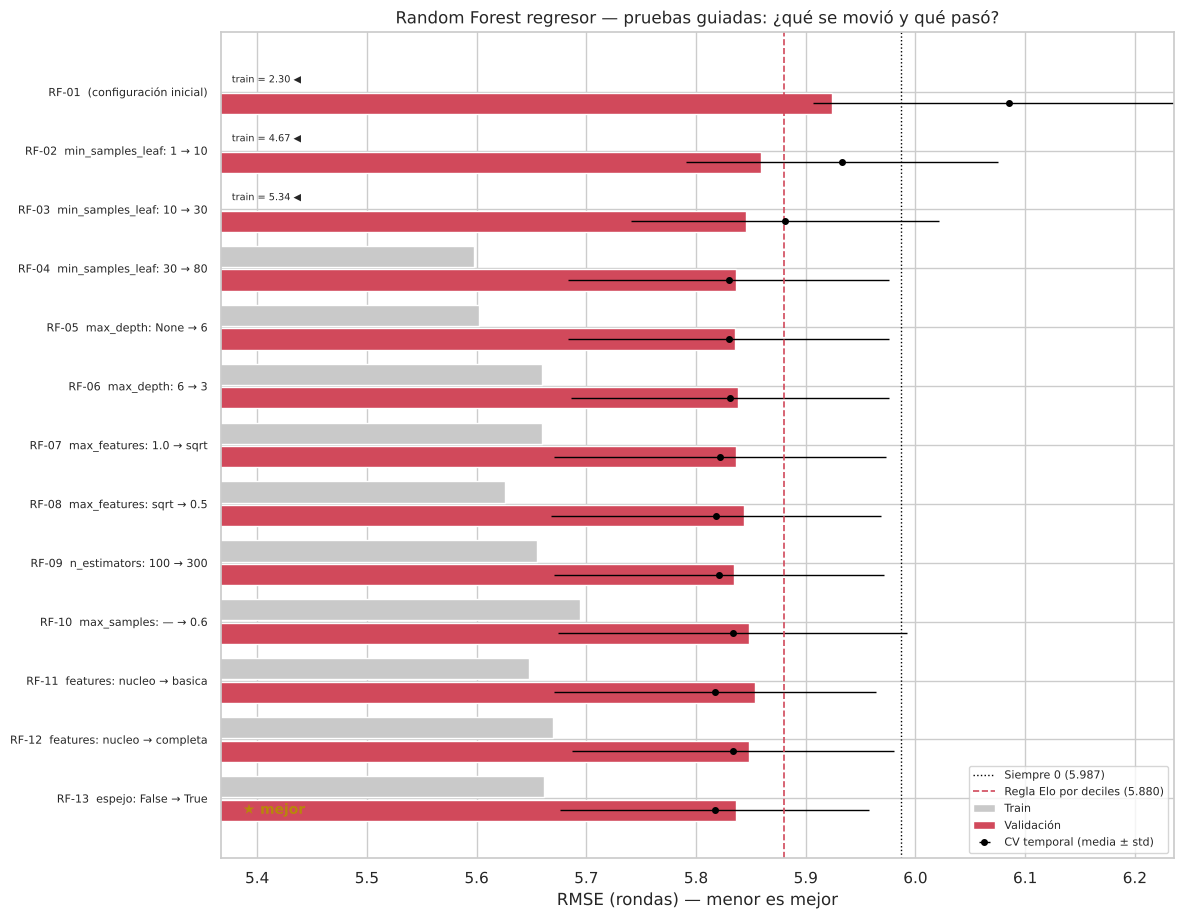

Random Forest: 13 pruebas guiadas.
  Base      RF-01: RMSE val 5.924 | cv 6.086 | score 6.0048 | brecha val-train +3.620
  Mejor     RF-13: RMSE val 5.837 | cv 5.817 | score 5.8268 | brecha val-train +0.175
  Mejora del score vs la base: -0.1780 rondas
  Configuración: {"features": "nucleo", "n_estimators": 300, "max_depth": 6, "min_samples_leaf": 80, "max_features": "sqrt", "espejo": true}


In [ ]:
#@title **TABLA Y GRÁFICA** de las pruebas guiadas del Random Forest regresor
display(tabla_modelo("RF"))
grafica_pruebas("RF")
resumen_modelo("RF")

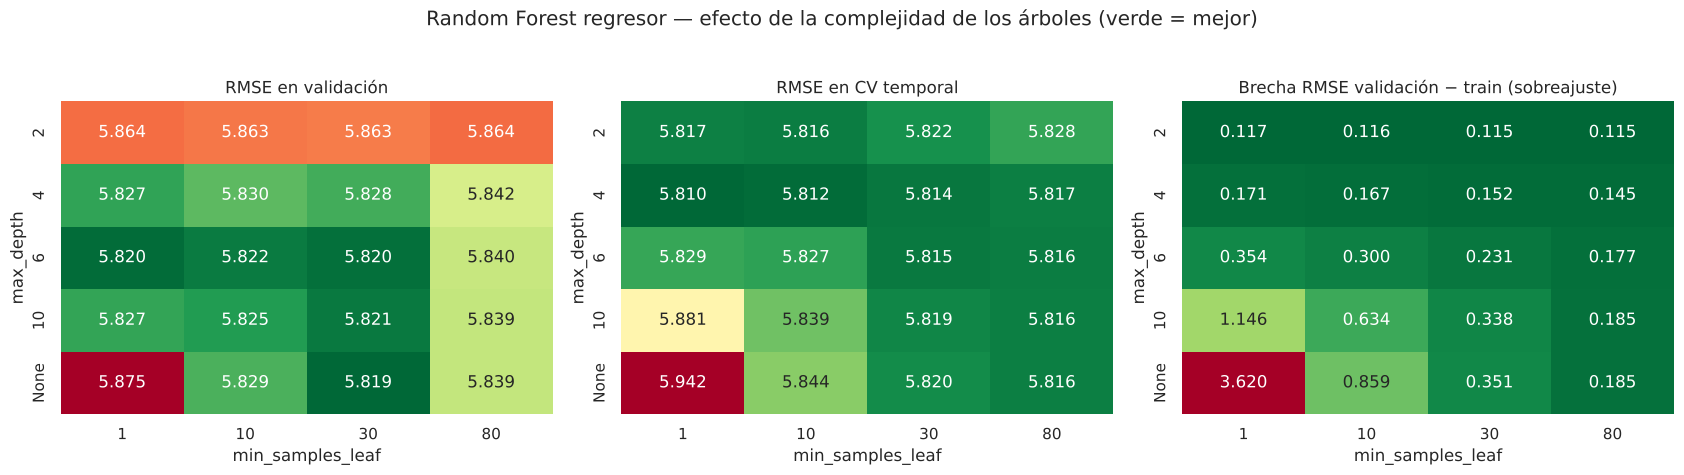

In [ ]:
#@title **BARRIDO RF:** cuadrícula `max_depth` × `min_samples_leaf` (200 árboles, 20 combinaciones registradas)
for md_ in [2, 4, 6, 10, None]:
    for msl in [1, 10, 30, 80]:
        prueba("RF", dict(max_depth=md_, min_samples_leaf=msl, n_estimators=200),
               f"Barrido: max_depth={md_}, min_samples_leaf={msl}, n_estimators=200", tipo="barrido", verbose=False)

r = registro_df(); b = r[(r.modelo == "RF") & (r.tipo == "barrido")].copy()
b["max_depth"] = b["params"].apply(lambda s: str(json.loads(s)["max_depth"])); b["min_samples_leaf"] = b["params"].apply(lambda s: json.loads(s)["min_samples_leaf"])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, col, tit in zip(axes, ["val_rmse", "cv_rmse", "gap"], ["RMSE en validación", "RMSE en CV temporal", "Brecha RMSE validación − train (sobreajuste)"]):
    pv = b.pivot(index="max_depth", columns="min_samples_leaf", values=col).reindex(["2", "4", "6", "10", "None"])
    sns.heatmap(pv, annot=True, fmt=".3f", cmap="RdYlGn_r", ax=ax, cbar=False)
    ax.set_title(tit); ax.set_xlabel("min_samples_leaf"); ax.set_ylabel("max_depth")
plt.suptitle("Random Forest regresor — efecto de la complejidad de los árboles (verde = mejor)", y=1.03); plt.tight_layout(); plt.show()

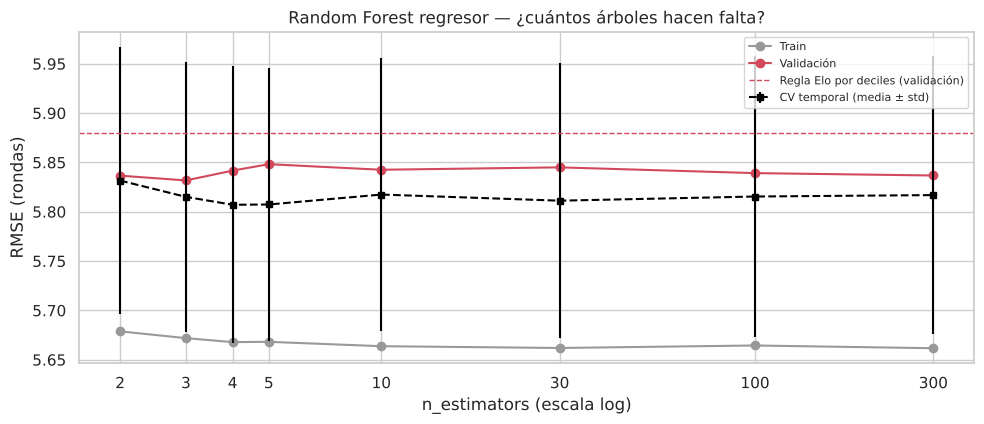

,n_arboles,train_rmse,val_rmse,cv_rmse,score_sel
0,2,5.6787,5.8366,5.8316,5.8341
1,3,5.6719,5.8317,5.8151,5.8234
2,4,5.6678,5.8417,5.8071,5.8244
3,5,5.6681,5.8482,5.8073,5.8278
4,10,5.6637,5.8425,5.8174,5.8300
5,30,5.6619,5.8450,5.8112,5.8281
6,100,5.6644,5.8391,5.8154,5.8273
7,300,5.6616,5.8367,5.8169,5.8268


In [ ]:
#@title **CURVA (ejercicio de clase):** RMSE según el número de árboles del bosque
n_est = [2, 3, 4, 5, 10, 30, 100, 300]
for ne in n_est:
    prueba("RF", dict(n_estimators=ne), f"Curva de n_estimators = {ne} (resto igual a la mejor prueba guiada)", tipo="barrido", verbose=False)
r = registro_df(); b = r[(r.modelo == "RF") & (r.cambió.str.startswith("n_estimators")) & (r.tipo == "barrido")].copy()
b["n_arboles"] = b["params"].apply(lambda s: json.loads(s)["n_estimators"]); b = b.sort_values("n_arboles").drop_duplicates("n_arboles", keep="last")
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(b["n_arboles"], b.train_rmse, "o-", color="#999999", label="Train"); ax.plot(b["n_arboles"], b.val_rmse, "o-", color=COLORES["RF"], label="Validación")
ax.errorbar(b["n_arboles"], b.cv_rmse, yerr=b.cv_std, fmt="s--", color="black", ms=4, label="CV temporal (media ± std)")
ax.axhline(RMSE_ELO_VAL, color="#d1495b", ls="--", lw=1, label="Regla Elo por deciles (validación)")
ax.set_xscale("log"); ax.set_xticks(n_est); ax.set_xticklabels(n_est); ax.set_xlabel("n_estimators (escala log)"); ax.set_ylabel("RMSE (rondas)")
ax.set_title("Random Forest regresor — ¿cuántos árboles hacen falta?"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
display(b[["n_arboles", "train_rmse", "val_rmse", "cv_rmse", "score_sel"]].round(4).reset_index(drop=True))

Mejor RF de todas las pruebas: RF-24 — {"features": "nucleo", "n_estimators": 200, "max_depth": 6, "min_samples_leaf": 30, "max_features": "sqrt", "espejo": true}


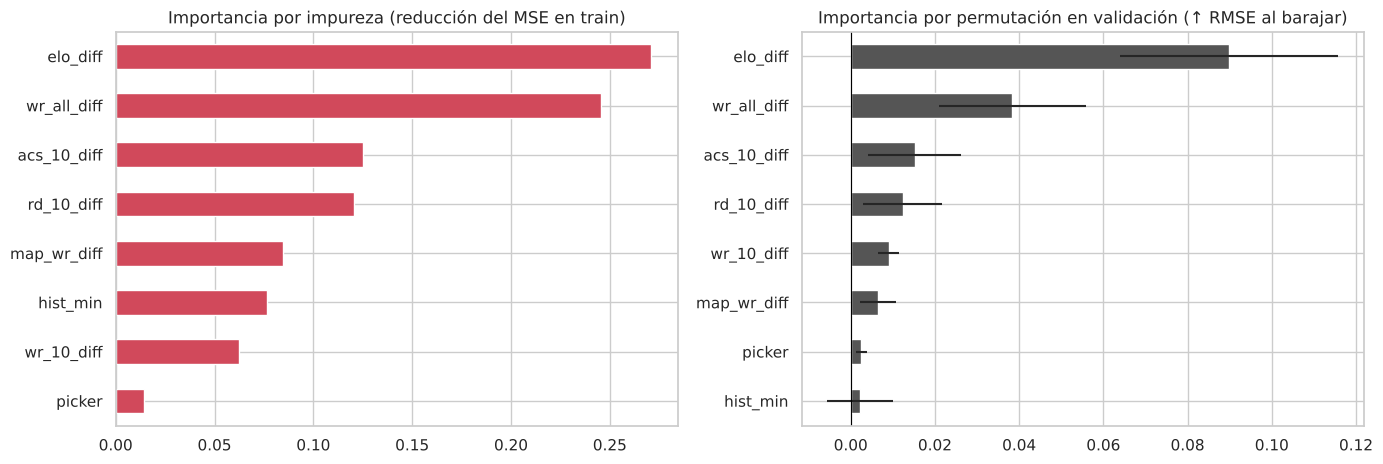

elo_diff       0.0899
wr_all_diff    0.0384
acs_10_diff    0.0152
rd_10_diff     0.0123
wr_10_diff     0.0091
map_wr_diff    0.0064
picker         0.0025
hist_min       0.0022


In [ ]:
#@title **GRÁFICA:** importancia de variables del mejor RF regresor (impureza y permutación en validación)
cfg = mejor_global("RF"); est, cols = construir_modelo("RF", cfg["params"]); est.fit(X_tr[cols], r_tr)
print(f"Mejor RF de todas las pruebas: {cfg['id']} — {json.dumps(cfg['params'], default=str)}")
bosque = desenvolver(est)
imp_imp = pd.Series(bosque.feature_importances_, index=cols).sort_values()
perm = permutation_importance(est, X_va[cols], r_va, scoring="neg_root_mean_squared_error", n_repeats=20, random_state=SEED)
imp_perm = pd.Series(perm.importances_mean, index=cols)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
imp_imp.tail(12).plot.barh(ax=ax[0], color=COLORES["RF"]); ax[0].set_title("Importancia por impureza (reducción del MSE en train)")
orden_p = imp_perm.sort_values().tail(12).index
imp_perm[orden_p].plot.barh(ax=ax[1], color="#555555", xerr=pd.Series(perm.importances_std, index=cols)[orden_p])
ax[1].axvline(0, color="black", lw=.8); ax[1].set_title("Importancia por permutación en validación (↑ RMSE al barajar)")
plt.tight_layout(); plt.show()
print(imp_perm.sort_values(ascending=False).round(4).to_string())

### 📖 Lectura de los resultados del Random Forest regresor
- **Línea base:** RMSE ≈ **2.3 en train** y ≈ **5.92 en validación** (brecha de 3.6 rondas). Sobreajusta, pero mucho menos que el árbol solo (8.2), porque promedia muchos árboles. Aun así es apenas mejor que predecir 0.
- **Lo que más ayudó fueron las hojas grandes:** `min_samples_leaf` 1 → 10 → 30 → 80 bajó el puntaje de forma constante (CV 6.09 → 5.83) y redujo la brecha de 3.6 a 0.24. En regresión cada hoja es un **promedio**, y promediar más mapas reduce el ruido.
- **Casi todo lo demás quedó "≈ igual"** (profundidad, `max_features`, 300 árboles, quitar variables, espejo): cambios de milésimas, dentro del ruido. `max_samples = 0.6` y las 29 variables (`completa`) empeoraron un poco.
- **La cuadrícula `max_depth × min_samples_leaf` muestra una meseta:** casi todas las casillas quedan entre 5.82 y 5.84 en validación. Solo empeoran las esquinas sin regularizar (sin límite y hojas de 1 mapa: brecha de 3.6) y los árboles de profundidad 2 (demasiado simples). La mejor casilla (profundidad 6, hojas de 30, con espejo) es la mejor configuración de todo el bosque.
- **La curva de número de árboles es plana** (de 2 a 300 árboles el RMSE de validación se mueve entre 5.83 y 5.85). Con hojas tan grandes cada árbol ya es muy suave, así que promediar más árboles casi no reduce la varianza. Es lo contrario de lo que pasa con árboles profundos.
- **Importancia por permutación:** barajar `elo_diff` sube el RMSE ≈ 0.09 rondas; `wr_all_diff` ≈ 0.04; `acs_10_diff` y `rd_10_diff` ≈ 0.01. El resto aporta prácticamente nada. **El Elo vuelve a ser casi toda la señal.**

## 8. Modelo 3 — SVR (*Support Vector Regression*)

El SVR busca una función lo más "plana" posible que deje a la mayoría de los mapas dentro de un **tubo de ancho ε** alrededor de la predicción; solo los mapas que quedan **fuera** del tubo (los vectores de soporte) se penalizan. Las variables se estandarizan con `Pipeline(StandardScaler → SVR)`, que reajusta el escalado solo con los datos de entrenamiento de cada pliegue (sin fuga).

**Hiperparámetros que movemos:**
- `C`: cuánto se penaliza a los mapas fuera del tubo (alto = ajusta más el entrenamiento).
- `epsilon` (ε): ancho del tubo, **en rondas**. Errores menores a ε no cuentan.
- `gamma` (kernel RBF): alcance de cada observación (alto = función muy "nerviosa").
- `kernel`: `rbf`, `linear` o `poly` (con `degree`).
- `features` y `espejo`.

**Hipótesis central:** como en la SVM de clasificación, la mejor función será **casi lineal** (kernel lineal o RBF con `gamma` y `C` bajos). Además, como el margen tiene mucho ruido (una paliza 13-2 no se puede anticipar), un **ε más ancho** podría ayudar a no perseguir ese ruido.

In [ ]:
#@title **EXPERIMENTOS SVR** — cada línea es una prueba registrada
prueba("SVR", params=dict(features="nucleo", kernel="rbf", C=1.0, gamma="scale", epsilon=0.1),
       hipotesis="Línea base: SVR RBF con los valores por defecto de sklearn (C=1, gamma='scale', ε=0.1), variables estandarizadas.")

ensayos_svr = [
    (dict(C=0.1),                    "Bajar C: tolerar más errores, función más suave."),
    (dict(C=10.0),                   "Subir C: ajustar más el entrenamiento."),
    (dict(gamma=0.01),               "gamma bajo: cada mapa influye lejos → función casi lineal."),
    (dict(gamma=0.1),                "gamma intermedio."),
    (dict(epsilon=1.0),              "Tubo de ±1 ronda: ignorar errores pequeños."),
    (dict(epsilon=3.0),              "Tubo de ±3 rondas: solo importan los errores grandes."),
    (dict(kernel="linear"),          "Kernel lineal: ¿la curvatura del RBF aporta algo?"),
    (dict(kernel="poly", degree=3),  "Kernel polinómico de grado 3."),
    (dict(features="basica"),        "Dar solo 4 variables al SVR."),
    (dict(features="elo"),           "Dar solo el Elo."),
    (dict(features="completa"),      "Dar las 29 variables al SVR."),
    (dict(espejo=True),              "SVR simétrico: entrenar con el mapa y su versión A↔B."),
]
for cambios, hip in ensayos_svr:
    prueba("SVR", cambios, hip)

[SVR-01] (configuración inicial)                              | RMSE train 5.693  val 5.917  cv 5.954±0.179  R² val +0.020 | base
[SVR-02] C: 1.0 → 0.1                                         | RMSE train 5.764  val 5.869  cv 5.951±0.164  R² val +0.036 | ▲ mejora
[SVR-03] C: 0.1 → 10.0                                        | RMSE train 5.445  val 6.300  cv 6.406±0.200  R² val -0.111 | ▼ empeora
[SVR-04] gamma: scale → 0.01                                  | RMSE train 5.771  val 5.828  cv 5.968±0.139  R² val +0.049 | ▲ mejora
[SVR-05] gamma: 0.01 → 0.1                                    | RMSE train 5.765  val 5.864  cv 5.931±0.178  R² val +0.037 | ≈ igual
[SVR-06] epsilon: 0.1 → 1.0                                   | RMSE train 5.750  val 5.859  cv 5.865±0.139  R² val +0.039 | ▲ mejora
[SVR-07] epsilon: 1.0 → 3.0                                   | RMSE train 5.764  val 5.874  cv 5.874±0.122  R² val +0.034 | ▼ empeora
[SVR-08] kernel: rbf → linear                                 | R

,id,referencia,cambió,train_rmse,val_rmse,val_mae,val_r2,cv_rmse,cv_std,gap,score_sel,veredicto
0,SVR-01,—,(configuración inicial),5.6929,5.9169,5.0355,0.0200,5.9541,0.1794,0.2240,5.9355,base
1,SVR-02,SVR-01,C: 1.0 → 0.1,5.7636,5.8690,5.0806,0.0358,5.9513,0.1643,0.1054,5.9101,▲ mejora
2,SVR-03,SVR-02,C: 0.1 → 10.0,5.4446,6.2999,5.3265,-0.1110,6.4061,0.1998,0.8552,6.3530,▼ empeora
3,SVR-04,SVR-02,gamma: scale → 0.01,5.7708,5.8278,5.0435,0.0493,5.9679,0.1389,0.0569,5.8978,▲ mejora
4,SVR-05,SVR-04,gamma: 0.01 → 0.1,5.7654,5.8640,5.0655,0.0374,5.9314,0.1776,0.0985,5.8977,≈ igual
5,SVR-06,SVR-05,epsilon: 0.1 → 1.0,5.7503,5.8587,5.0794,0.0391,5.8653,0.1390,0.1085,5.8620,▲ mejora
6,SVR-07,SVR-06,epsilon: 1.0 → 3.0,5.7636,5.8740,5.1440,0.0341,5.8735,0.1224,0.1104,5.8738,▼ empeora
7,SVR-08,SVR-06,kernel: rbf → linear,5.7821,5.9716,4.9702,0.0018,5.9153,0.1548,0.1895,5.9435,▼ empeora
8,SVR-09,SVR-06,kernel: rbf → poly | degree: — → 3,5.7662,5.9471,5.0952,0.0099,5.9489,0.2371,0.1809,5.9480,▼ empeora
9,SVR-10,SVR-06,features: nucleo → basica,5.7629,5.9001,5.0325,0.0255,5.8470,0.1395,0.1372,5.8736,▼ empeora


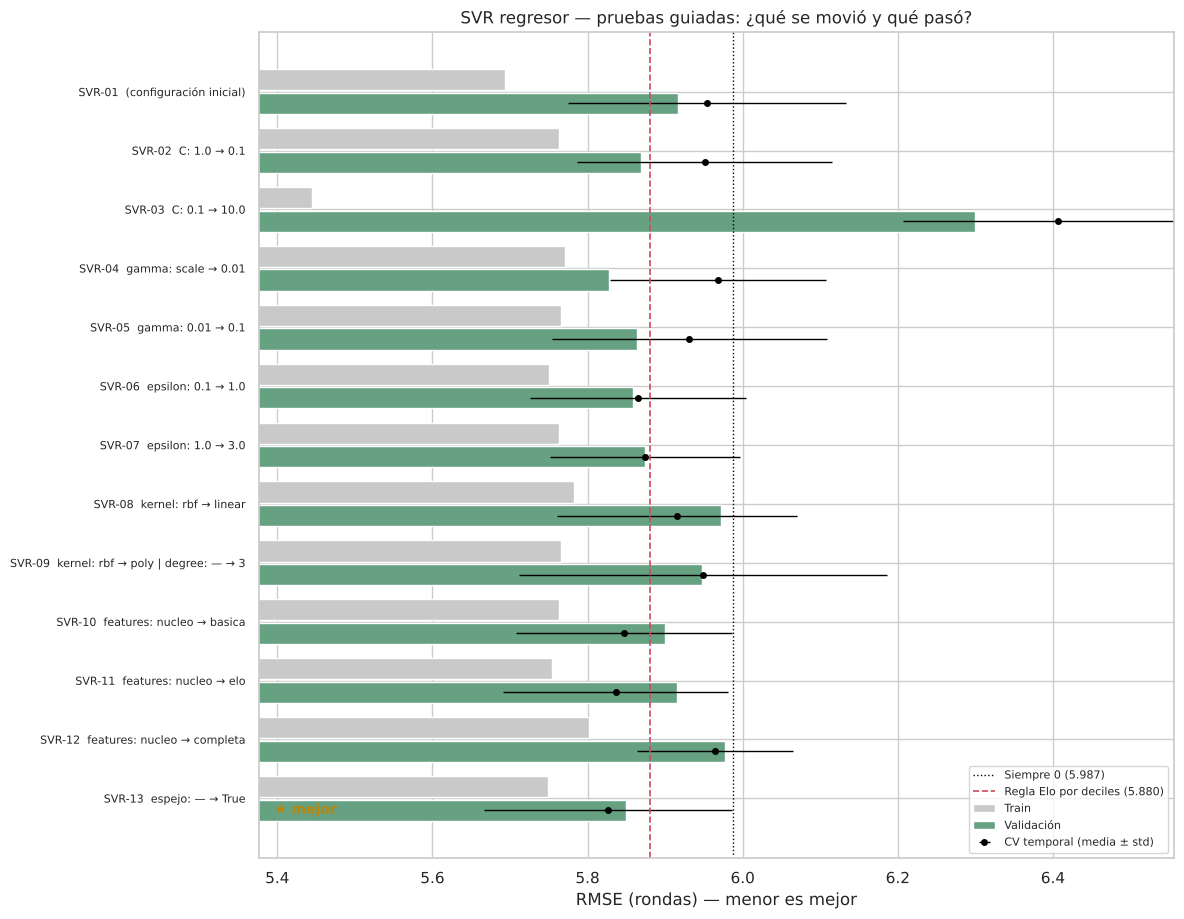

SVR: 13 pruebas guiadas.
  Base      SVR-01: RMSE val 5.917 | cv 5.954 | score 5.9355 | brecha val-train +0.224
  Mejor     SVR-13: RMSE val 5.850 | cv 5.826 | score 5.8378 | brecha val-train +0.100
  Mejora del score vs la base: -0.0977 rondas
  Configuración: {"features": "nucleo", "kernel": "rbf", "C": 0.1, "gamma": 0.1, "epsilon": 1.0, "espejo": true}


In [ ]:
#@title **TABLA Y GRÁFICA** de las pruebas guiadas del SVR
display(tabla_modelo("SVR"))
grafica_pruebas("SVR")
resumen_modelo("SVR")

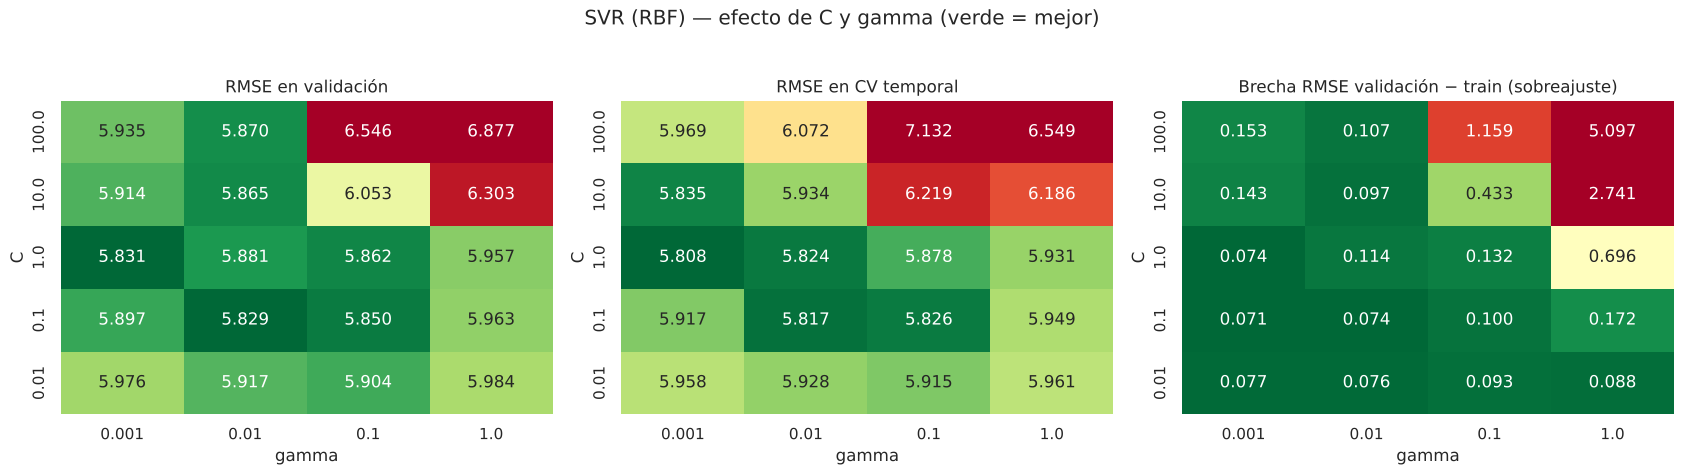

In [ ]:
#@title **BARRIDO SVR:** cuadrícula `C` × `gamma` con kernel RBF (20 combinaciones registradas)
for C in [0.01, 0.1, 1, 10, 100]:
    for g in [0.001, 0.01, 0.1, 1]:
        prueba("SVR", dict(kernel="rbf", C=C, gamma=g), f"Barrido RBF: C={C}, gamma={g}", tipo="barrido", verbose=False)

r = registro_df(); b = r[(r.modelo == "SVR") & (r["hipótesis"].str.startswith("Barrido RBF"))].copy()
b["C"] = b["params"].apply(lambda s: json.loads(s)["C"]); b["gamma"] = b["params"].apply(lambda s: json.loads(s)["gamma"])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, col, tit in zip(axes, ["val_rmse", "cv_rmse", "gap"], ["RMSE en validación", "RMSE en CV temporal", "Brecha RMSE validación − train (sobreajuste)"]):
    pv = b.pivot(index="C", columns="gamma", values=col).sort_index(ascending=False)
    sns.heatmap(pv, annot=True, fmt=".3f", cmap="RdYlGn_r", ax=ax, cbar=False, vmax=np.nanpercentile(pv.values, 90))
    ax.set_title(tit); ax.set_xlabel("gamma"); ax.set_ylabel("C")
plt.suptitle("SVR (RBF) — efecto de C y gamma (verde = mejor)", y=1.03); plt.tight_layout(); plt.show()

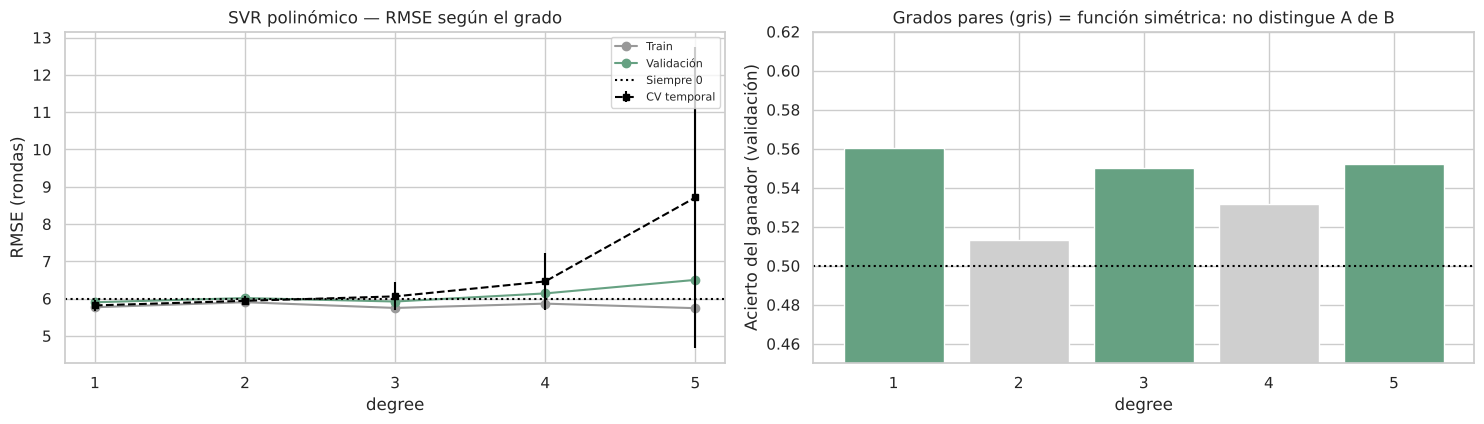

,degree,train_rmse,val_rmse,cv_rmse,val_acc_signo,score_sel
0,1,5.7683,5.9013,5.8165,0.5604,5.8589
1,2,5.9027,6.0137,5.9402,0.5134,5.9769
2,3,5.7490,5.9215,6.0592,0.5503,5.9903
3,4,5.8648,6.1390,6.4603,0.5319,6.2997
4,5,5.7428,6.5016,8.7118,0.5520,7.6067


In [ ]:
#@title **CURVA (ejercicio de clase):** SVR con kernel polinómico de distintos grados
for deg in [1, 2, 3, 4, 5]:
    prueba("SVR", dict(kernel="poly", degree=deg, gamma="scale"), f"Curva kernel poly, degree = {deg} (resto igual a la mejor prueba guiada)", tipo="barrido", verbose=False)
r = registro_df(); b = r[(r.modelo == "SVR") & (r["hipótesis"].str.startswith("Curva kernel poly"))].copy()
b["degree"] = b["params"].apply(lambda s: json.loads(s)["degree"])
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
ax[0].plot(b.degree, b.train_rmse, "o-", color="#999999", label="Train"); ax[0].plot(b.degree, b.val_rmse, "o-", color=COLORES["SVR"], label="Validación")
ax[0].errorbar(b.degree, b.cv_rmse, yerr=b.cv_std, fmt="s--", color="black", ms=4, label="CV temporal")
ax[0].axhline(RMSE_CERO_VAL, color="black", ls=":", label="Siempre 0"); ax[0].set_xticks([1, 2, 3, 4, 5])
ax[0].set_xlabel("degree"); ax[0].set_ylabel("RMSE (rondas)"); ax[0].set_title("SVR polinómico — RMSE según el grado"); ax[0].legend(fontsize=8)
ax[1].bar(b.degree, b.val_acc_signo, color=[COLORES["SVR"] if d % 2 else "#cfcfcf" for d in b.degree]); ax[1].axhline(0.5, color="black", ls=":")
ax[1].set_ylim(0.45, 0.62); ax[1].set_xlabel("degree"); ax[1].set_ylabel("Acierto del ganador (validación)")
ax[1].set_title("Grados pares (gris) = función simétrica: no distingue A de B"); plt.tight_layout(); plt.show()
display(b[["degree", "train_rmse", "val_rmse", "cv_rmse", "val_acc_signo", "score_sel"]].round(4).reset_index(drop=True))

### 📖 Lectura de los resultados del SVR
- **Arranque:** RBF con valores por defecto, RMSE ≈ **5.92** en validación, apenas mejor que predecir 0.
- **`C` es el hiperparámetro más delicado:** con `C = 10` el SVR persigue el ruido y se dispara (RMSE 6.30, R² = −0.11); con `C = 0.1` mejora. En la cuadrícula se ve claro: con `C` y `gamma` grandes (esquina superior derecha) la brecha validación–train llega a **5 rondas**. Con `C` o `gamma` pequeños la función es suave y no hay sobreajuste.
- **`gamma` bajo y `epsilon` = 1 ronda ayudaron:** un tubo de ±1 ronda evita que el modelo se esfuerce por errores pequeños, que en este problema son puro ruido. Con ε = 3 ya se pierde información.
- **Kernel lineal con `C = 0.1` empeoró** (R² ≈ 0): con tan poca libertad la recta queda casi plana. En la cuadrícula, la mejor zona es **RBF con `gamma = 0.001` y `C = 1`**, que en la práctica es una función casi lineal pero con la pendiente adecuada. Se confirma la hipótesis: **la relación útil es prácticamente una recta.**
- **El espejo A↔B sí ayudó en el SVR** (mejor CV). Al obligar a que la predicción para B sea exactamente la opuesta de la de A, se elimina el sesgo del orden de los equipos.
- **Curva del ejercicio de clase (grado polinómico):** los **grados pares (2 y 4)** casi no distinguen al ganador (acierto ≈ 51–53 %), porque un polinomio de grado par sin término independiente es **simétrico**: le da casi el mismo valor a "A con ventaja" que a "B con la misma ventaja". Los grados impares sí distinguen, y el **grado 5 sobreajusta** (RMSE en CV de 8.7 con desviación enorme). Esto también explica por qué el kernel polinómico de grado 2 se desplomó en la SVM de clasificación.

## 9. Registro completo de pruebas de regresión

Aquí está **todo lo que se probó**: cada fila es un experimento con lo que se movió, la hipótesis, los hiperparámetros completos y las métricas. Se guarda en `registro_pruebas_regresion_VCT.csv` (en Colab: panel de archivos de la izquierda, y se descarga automáticamente al final de la celda).

In [ ]:
#@title **CODE:** guardar y mostrar el registro completo
registro = registro_df()
registro.to_csv("registro_pruebas_regresion_VCT.csv", index=False, encoding="utf-8-sig")
print(f"✔ {len(registro)} pruebas guardadas en registro_pruebas_regresion_VCT.csv")
display(registro.groupby(["modelo", "tipo"]).size().unstack(fill_value=0).rename(columns={"guiada": "pruebas guiadas", "barrido": "pruebas de barrido"}))

print("\nPRUEBAS GUIADAS (en el orden en que se hicieron) — qué se movió y qué pasó:")
display(registro[registro.tipo == "guiada"][["id", "cambió", "val_rmse", "val_mae", "val_r2", "cv_rmse", "gap", "score_sel", "veredicto"]].round(4).reset_index(drop=True))

print("\nTOP 10 de todas las pruebas por puntaje de selección (menor es mejor):")
display(registro.sort_values(["score_sel", "val_mae"]).head(10)[["id", "tipo", "cambió", "val_rmse", "val_mae", "val_r2", "cv_rmse", "gap", "score_sel"]].round(4).reset_index(drop=True))

try:
    from google.colab import files; files.download("registro_pruebas_regresion_VCT.csv")
except Exception:
    pass

✔ 118 pruebas guardadas en registro_pruebas_regresion_VCT.csv


tipo,pruebas de barrido,pruebas guiadas
modelo,,
DT,26,13
RF,28,13
SVR,25,13



PRUEBAS GUIADAS (en el orden en que se hicieron) — qué se movió y qué pasó:


,id,cambió,val_rmse,val_mae,val_r2,cv_rmse,gap,score_sel,veredicto
0,DT-01,(configuración inicial),8.1672,6.6862,-0.8672,8.2759,7.6678,8.2215,base
1,DT-02,max_depth: None → 3,5.8803,5.1221,0.0321,6.0122,0.1920,5.9462,▲ mejora
2,DT-03,max_depth: 3 → 2,5.8263,5.0276,0.0498,5.9092,0.0963,5.8678,▲ mejora
3,DT-04,max_depth: 2 → 5,6.1713,5.2094,-0.0661,6.4411,0.6844,6.3062,▼ empeora
4,DT-05,min_samples_leaf: 1 → 40,5.8263,5.0276,0.0498,5.8986,0.0963,5.8624,≈ igual
5,DT-06,min_samples_leaf: 40 → 100,5.8263,5.0276,0.0498,5.8930,0.0963,5.8597,≈ igual
6,DT-07,criterion: squared_error → absolute_error,6.0439,4.9983,-0.0225,6.0980,0.1852,6.0709,▼ empeora
7,DT-08,criterion: squared_error → friedman_mse,5.8263,5.0276,0.0498,5.8930,0.0963,5.8597,≈ igual
8,DT-09,max_features: None → sqrt,5.9208,5.0901,0.0187,5.9013,0.1657,5.9110,▼ empeora
9,DT-10,ccp_alpha: 0.0 → 0.3,5.8263,5.0276,0.0498,5.9074,0.0963,5.8668,≈ igual



TOP 10 de todas las pruebas por puntaje de selección (menor es mejor):


,id,tipo,cambió,val_rmse,val_mae,val_r2,cv_rmse,gap,score_sel
0,RF-24,barrido,max_depth: 6 → 6 | min_samples_leaf: 80 → 30 | n_estimators: 300 →...,5.8202,5.0405,0.0518,5.8152,0.2314,5.8177
1,RF-18,barrido,max_depth: 6 → 4 | min_samples_leaf: 80 → 1 | n_estimators: 300 → 200,5.8265,5.0604,0.0497,5.8101,0.1705,5.8183
2,SVR-22,barrido,kernel: rbf → rbf | C: 0.1 → 1 | gamma: 0.1 → 0.001,5.8311,4.9950,0.0482,5.8079,0.0745,5.8195
3,RF-32,barrido,max_depth: 6 → None | min_samples_leaf: 80 → 30 | n_estimators: 30...,5.8193,5.0334,0.0521,5.8203,0.3505,5.8198
4,RF-28,barrido,max_depth: 6 → 10 | min_samples_leaf: 80 → 30 | n_estimators: 300 ...,5.8214,5.0355,0.0513,5.8186,0.3378,5.8200
5,RF-19,barrido,max_depth: 6 → 4 | min_samples_leaf: 80 → 10 | n_estimators: 300 →...,5.8299,5.0625,0.0486,5.8116,0.1673,5.8207
6,RF-20,barrido,max_depth: 6 → 4 | min_samples_leaf: 80 → 30 | n_estimators: 300 →...,5.8279,5.0584,0.0492,5.8145,0.1516,5.8212
7,SVR-19,barrido,kernel: rbf → rbf | C: 0.1 → 0.1 | gamma: 0.1 → 0.01,5.8294,5.0115,0.0487,5.8174,0.0739,5.8234
8,RF-35,barrido,n_estimators: 300 → 3,5.8317,5.0381,0.0480,5.8151,0.1598,5.8234
9,RF-23,barrido,max_depth: 6 → 6 | min_samples_leaf: 80 → 10 | n_estimators: 300 →...,5.8216,5.0393,0.0513,5.8267,0.2999,5.8241


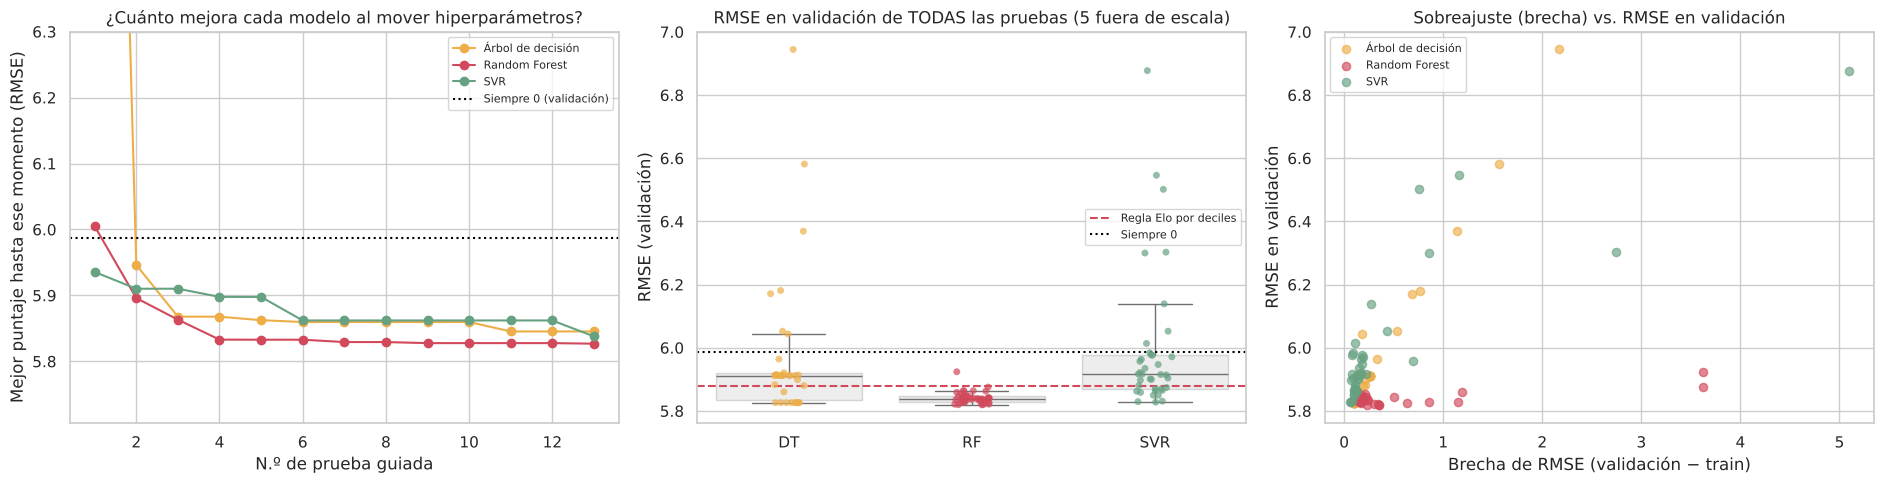

veredicto,base,≈ igual,▲ mejora,▼ empeora
modelo,,,,
DT,1,4,3,5
RF,1,7,3,2
SVR,1,1,4,7


In [ ]:
#@title **GRÁFICAS:** panorama de todas las pruebas de regresión
registro = registro_df()
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for m in NOMBRES:      # (1) evolución del mejor puntaje a lo largo de las pruebas guiadas
    g = registro[(registro.modelo == m) & (registro.tipo == "guiada")].reset_index(drop=True)
    axes[0].plot(range(1, len(g) + 1), g.score_sel.cummin(), "o-", color=COLORES[m], label=NOMBRES[m])
axes[0].axhline(RMSE_CERO_VAL, color="black", ls=":", label="Siempre 0 (validación)")
axes[0].set_ylim(None, 6.3)
axes[0].set_xlabel("N.º de prueba guiada"); axes[0].set_ylabel("Mejor puntaje hasta ese momento (RMSE)")
axes[0].set_title("¿Cuánto mejora cada modelo al mover hiperparámetros?"); axes[0].legend(fontsize=8)

reg_v = registro[registro.val_rmse < 7]       # (2) todas las pruebas (sin los árboles sin límite, fuera de escala)
sns.stripplot(data=reg_v, x="modelo", y="val_rmse", hue="modelo", palette=COLORES, order=list(NOMBRES), size=5, alpha=.7, ax=axes[1], legend=False)
sns.boxplot(data=reg_v, x="modelo", y="val_rmse", order=list(NOMBRES), showfliers=False, boxprops=dict(alpha=.25), ax=axes[1], color="#bbbbbb")
axes[1].axhline(RMSE_ELO_VAL, color="#d1495b", ls="--", label="Regla Elo por deciles"); axes[1].axhline(RMSE_CERO_VAL, color="black", ls=":", label="Siempre 0")
axes[1].set_title(f"RMSE en validación de TODAS las pruebas ({len(registro) - len(reg_v)} fuera de escala)"); axes[1].set_xlabel(""); axes[1].set_ylabel("RMSE (validación)"); axes[1].legend(fontsize=8)

for m in NOMBRES:      # (3) mapa de sobreajuste
    g = reg_v[reg_v.modelo == m]; axes[2].scatter(g.gap, g.val_rmse, color=COLORES[m], alpha=.65, label=NOMBRES[m], s=35)
axes[2].set_xlabel("Brecha de RMSE (validación − train)"); axes[2].set_ylabel("RMSE en validación")
axes[2].set_title("Sobreajuste (brecha) vs. RMSE en validación"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

display(registro[registro.tipo == "guiada"].groupby(["modelo", "veredicto"]).size().unstack(fill_value=0))

## 10. Curvas de aprendizaje

Como en la última parte del notebook de clase (*Learning curves*), medimos cómo cambia el error de cada **mejor configuración** según el **número de pliegues** de la validación cruzada (`KFold` de 2 a 9 pliegues, MSE). Con pocos pliegues cada modelo entrena con menos datos; con muchos pliegues, con casi todos. Si la curva baja al aumentar los pliegues, **más datos ayudarían**; si es plana, el modelo ya aprendió lo que las variables permiten.

Se hace sobre 2024–2025 (el test sigue sin tocarse).

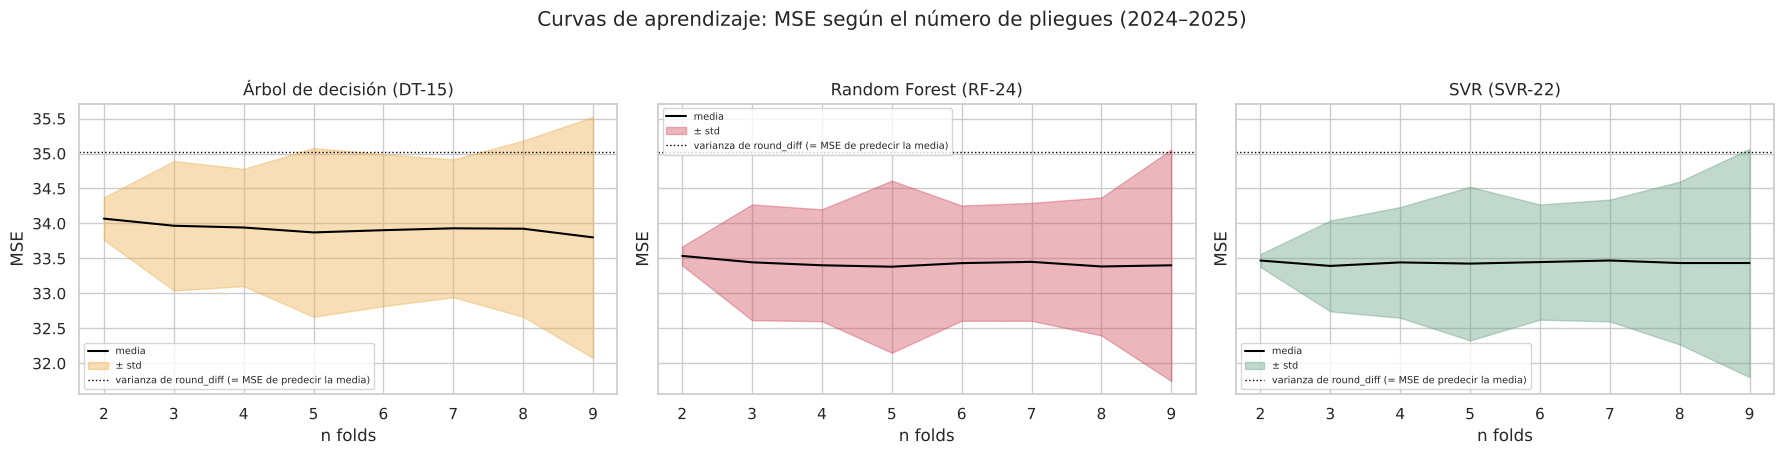

Árbol de decisión : MSE con 2 pliegues 34.07 -> con 9 pliegues 33.80  (varianza de round_diff: 35.01)
Random Forest     : MSE con 2 pliegues 33.54 -> con 9 pliegues 33.40  (varianza de round_diff: 35.01)
SVR               : MSE con 2 pliegues 33.47 -> con 9 pliegues 33.43  (varianza de round_diff: 35.01)


In [ ]:
#@title **CODE:** curva de aprendizaje (como en clase) para la mejor configuración de cada modelo
def show_curve(est, Xm, ym, ax, color, nombre):
    means, stds = [], []
    nfolds_range = range(2, 10)                     # vector [2, 3, 4, ..., 9]
    for nfolds in nfolds_range:
        s = cross_val_score(est, Xm, ym, cv=KFold(nfolds, shuffle=True, random_state=SEED), scoring=make_scorer(mean_squared_error))
        means.append(np.mean(s)); stds.append(np.std(s))
    means, stds = np.r_[means], np.r_[stds]
    ax.plot(nfolds_range, means, label="media", color="black")
    ax.fill_between(nfolds_range, means - stds, means + stds, color=color, alpha=.4, label="± std")
    ax.axhline(np.var(ym), color="black", ls=":", lw=1, label="varianza de round_diff (= MSE de predecir la media)")
    ax.set_xlabel("n folds"); ax.set_ylabel("MSE"); ax.set_title(nombre); ax.legend(fontsize=7)
    return means

fig, axes = plt.subplots(1, 3, figsize=(18, 4.4), sharey=True)
curvas = {}
for ax, m in zip(axes, NOMBRES):
    cfg = mejor_global(m); est, cols = construir_modelo(m, cfg["params"])
    curvas[m] = show_curve(est, X_dev[cols], r_dev, ax, COLORES[m], f"{NOMBRES[m]} ({cfg['id']})")
plt.suptitle("Curvas de aprendizaje: MSE según el número de pliegues (2024–2025)", y=1.03); plt.tight_layout(); plt.show()
for m in NOMBRES:
    print(f"{NOMBRES[m]:18s}: MSE con 2 pliegues {curvas[m][0]:.2f} -> con 9 pliegues {curvas[m][-1]:.2f}  (varianza de round_diff: {np.var(r_dev):.2f})")

### 📖 Lectura de las curvas de aprendizaje
- **Las tres curvas son planas:** el MSE apenas cambia entre 2 y 9 pliegues (≈ 33.4–34.1), y la banda de ± desviación es estrecha. Entrenar con la mitad de los datos o con casi todos da el mismo error.
- **Comparado con la varianza de `round_diff` (≈ 35.0)**, los modelos explican solo ≈ 4–5 % de la variabilidad del margen.
- **Conclusión:** el modelo **no está limitado por la cantidad de datos** sino por la **información** que tienen las variables pre-match. Más mapas del mismo tipo no subirían el R²; harían falta variables nuevas (cambios de *roster*, parches, jugadores…). Es la misma conclusión de la curva de aprendizaje del notebook de clasificación.

## 11. Comparación final y elección de los dos mejores modelos de regresión

**Procedimiento** (el mismo del notebook de clasificación):

1. De cada modelo tomamos **su mejor configuración** según el puntaje de selección (validación + CV temporal). *Todavía no hemos visto el test.*
2. **Los dos mejores modelos se deciden con ese puntaje**, antes de mirar 2026.
3. Recién entonces reentrenamos las tres configuraciones con **train + validación** (todo 2024–2025) y las evaluamos **una sola vez** en 2026. El test sirve para **confirmar**, no para elegir.
4. Para ver si el ajuste sirvió, mostramos también cada modelo **con sus valores por defecto** (la primera prueba de cada uno).

In [ ]:
#@title **CODE:** mejor configuración de cada modelo y elección de los DOS mejores (solo con validación + CV)
mejores = {m: mejor_global(m) for m in NOMBRES}
sel = pd.DataFrame([{"Modelo": NOMBRES[m], "Prueba": c["id"], "Tipo": c["tipo"], "val MSE": c["val_mse"], "val RMSE": c["val_rmse"],
                     "CV RMSE": c["cv_rmse"], "CV std": c["cv_std"], "val MAE": c["val_mae"], "val R²": c["val_r2"],
                     "acierto ganador (val)": c["val_acc_signo"], "brecha val-train": c["gap"], "puntaje": c["score_sel"]}
                    for m, c in mejores.items()]).set_index("Modelo")
display(sel.round(4))
TOP2 = sorted(mejores, key=lambda m: (round(mejores[m]["score_sel"], 6), mejores[m]["val_mae"]))[:2]
GANADOR = TOP2[0]
print(f"\n🏆 Los dos mejores modelos de regresión (ANTES de ver el test): 1.º {NOMBRES[TOP2[0]]} [{mejores[TOP2[0]]['id']}]  ·  2.º {NOMBRES[TOP2[1]]} [{mejores[TOP2[1]]['id']}]")
for m, c in mejores.items():
    print(f"   {NOMBRES[m]:18s} -> {json.dumps(c['params'], default=str)}")

,Prueba,Tipo,val MSE,val RMSE,CV RMSE,CV std,val MAE,val R²,acierto ganador (val),brecha val-train,puntaje
Modelo,,,,,,,,,,,
Árbol de decisión,DT-15,barrido,33.9457,5.8263,5.8478,0.1373,5.0276,0.0498,0.5587,0.0963,5.8370
Random Forest,RF-24,barrido,33.8745,5.8202,5.8152,0.1333,5.0405,0.0518,0.5604,0.2314,5.8177
SVR,SVR-22,barrido,34.0014,5.8311,5.8079,0.1468,4.9950,0.0482,0.5537,0.0745,5.8195



🏆 Los dos mejores modelos de regresión (ANTES de ver el test): 1.º Random Forest [RF-24]  ·  2.º SVR [SVR-22]
   Árbol de decisión  -> {"features": "basica", "criterion": "squared_error", "max_depth": 2, "min_samples_leaf": 1, "max_features": null, "ccp_alpha": 0.0, "espejo": false}
   Random Forest      -> {"features": "nucleo", "n_estimators": 200, "max_depth": 6, "min_samples_leaf": 30, "max_features": "sqrt", "espejo": true}
   SVR                -> {"features": "nucleo", "kernel": "rbf", "C": 1, "gamma": 0.001, "epsilon": 1.0, "espejo": true}


In [ ]:
#@title **CODE:** reentrenar con 2024-2025 y evaluar UNA vez en 2026 (afinados vs. valores por defecto vs. líneas base)
def ajustar_dev_y_predecir(modelo, params):
    est, cols = construir_modelo(modelo, params); est.fit(X_dev[cols], r_dev)
    return est, est.predict(X_te[cols]), est.predict(X_dev[cols])

def ic_bootstrap_rmse(y_true, pred, B=2000, alpha=0.05):
    rng = np.random.default_rng(SEED); e2 = (np.asarray(y_true) - np.asarray(pred)) ** 2; n = len(e2)
    vals = np.sqrt(e2[rng.integers(0, n, size=(B, n))].mean(axis=1))
    return np.quantile(vals, [alpha / 2, 1 - alpha / 2])

modelos_dev, P_TEST, P_DEV, P_DEF = {}, {}, {}, {}
for m, c in mejores.items():
    modelos_dev[m], P_TEST[m], P_DEV[m] = ajustar_dev_y_predecir(m, c["params"])
    base0 = [r for r in REGISTRO if r["modelo"] == m][0]
    _, P_DEF[m], _ = ajustar_dev_y_predecir(m, base0["params"])

filas = []
for m in NOMBRES:
    for etiqueta, P in [("afinado", P_TEST[m]), ("por defecto", P_DEF[m])]:
        mt = metricas_reg(r_te, P); lo, hi = ic_bootstrap_rmse(r_te, P)
        filas.append({"Modelo": NOMBRES[m], "Versión": etiqueta, "MSE": mt["mse"], "RMSE": mt["rmse"], "IC95% RMSE inf": lo, "IC95% RMSE sup": hi,
                      "MAE": mt["mae"], "R²": mt["r2"], "acierto ganador": mt["acc_signo"]})
for _, fila_b in bases_reg[bases_reg.Conjunto == "Test 2026"].iterrows():
    lo, hi = (np.nan, np.nan)
    filas.append({"Modelo": "Línea base", "Versión": fila_b["Línea base"], "MSE": fila_b.MSE, "RMSE": fila_b.RMSE, "IC95% RMSE inf": lo, "IC95% RMSE sup": hi,
                  "MAE": fila_b.MAE, "R²": fila_b.R2, "acierto ganador": fila_b["acierto ganador"]})
test_tab = pd.DataFrame(filas)
display(test_tab.round(4))

,Modelo,Versión,MSE,RMSE,IC95% RMSE inf,IC95% RMSE sup,MAE,R²,acierto ganador
0,Árbol de decisión,afinado,34.8540,5.9037,5.7068,6.1069,5.0672,0.0152,0.5700
1,Árbol de decisión,por defecto,72.1637,8.4949,8.1619,8.8256,6.9063,-1.0390,0.5068
2,Random Forest,afinado,34.5013,5.8738,5.6772,6.0727,5.0889,0.0252,0.5824
3,Random Forest,por defecto,36.8615,6.0714,5.8591,6.2869,5.1889,-0.0415,0.5451
4,SVR,afinado,34.4882,5.8727,5.6671,6.0795,5.0086,0.0255,0.5813
5,SVR,por defecto,34.8761,5.9056,5.6858,6.1203,4.9949,0.0146,0.5959
6,Línea base,Siempre 0 (no sé quién gana),35.4639,5.9552,NaN,NaN,5.2652,-0.0020,NaN
7,Línea base,Siempre la media de round_diff,35.7892,5.9824,NaN,NaN,5.2857,-0.0112,0.4718
8,Línea base,Regla Elo: margen promedio de su decil de Elo,34.3201,5.8583,NaN,NaN,4.9971,0.0303,0.5847


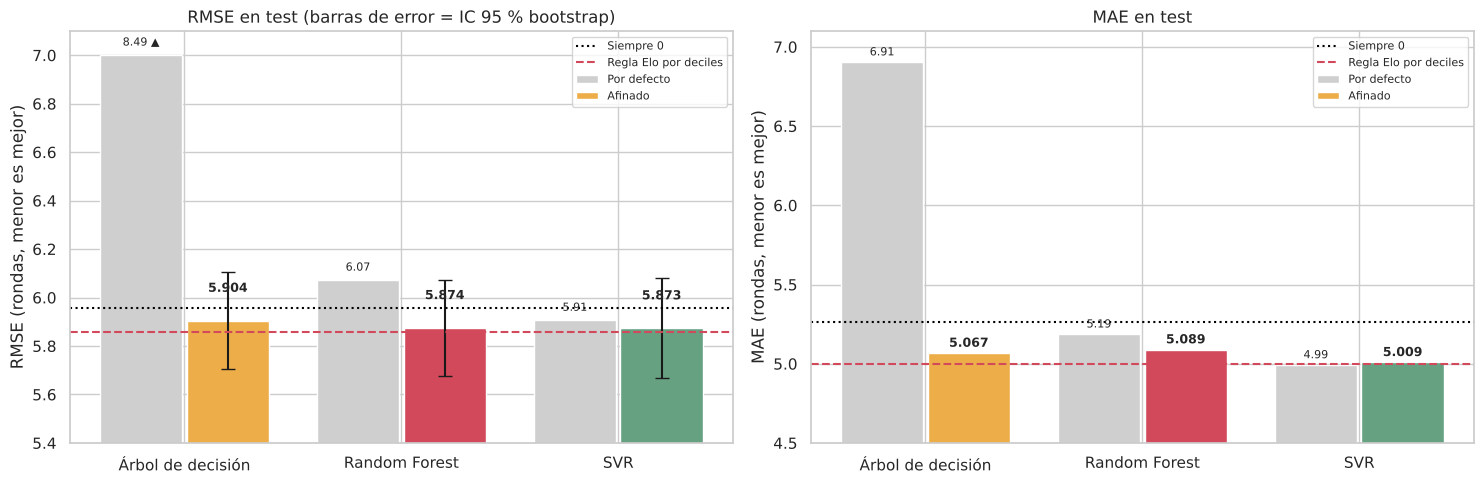

In [ ]:
#@title **GRÁFICA 1:** RMSE (con intervalo de confianza) y MAE en test 2026
afi = test_tab[test_tab["Versión"] == "afinado"].set_index("Modelo"); dfl = test_tab[test_tab["Versión"] == "por defecto"].set_index("Modelo")
orden = [NOMBRES[m] for m in NOMBRES]; x = np.arange(len(orden)); inv = {v: k for k, v in NOMBRES.items()}
b0 = bases_reg[(bases_reg.Conjunto == "Test 2026")].set_index("Línea base")
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for k, (col, tit) in enumerate([("RMSE", "RMSE en test (barras de error = IC 95 % bootstrap)"), ("MAE", "MAE en test")]):
    ax[k].bar(x - 0.2, dfl.loc[orden, col].clip(upper=7), 0.38, color="#cfcfcf", label="Por defecto")
    yerr = [afi.loc[orden, col] - afi.loc[orden, "IC95% RMSE inf"], afi.loc[orden, "IC95% RMSE sup"] - afi.loc[orden, col]] if col == "RMSE" else None
    ax[k].bar(x + 0.2, afi.loc[orden, col], 0.38, color=[COLORES[inv[o]] for o in orden], label="Afinado", yerr=yerr, capsize=5)
    for i, o in enumerate(orden):
        ax[k].text(i + 0.2, afi.loc[o, col] + (0.12 if col == "RMSE" else 0.04), f"{afi.loc[o, col]:.3f}", ha="center", fontsize=9, fontweight="bold")
        ax[k].text(i - 0.2, min(dfl.loc[o, col], 7) + 0.04, f"{dfl.loc[o, col]:.2f}" + (" ▲" if dfl.loc[o, col] > 7 else ""), ha="center", fontsize=8)
    ax[k].axhline(b0.iloc[0][col], color="black", ls=":", label="Siempre 0"); ax[k].axhline(b0.iloc[2][col], color="#d1495b", ls="--", label="Regla Elo por deciles")
    ax[k].set_xticks(x); ax[k].set_xticklabels(orden); ax[k].set_ylim(4.5 if col == "MAE" else 5.4, 7.1); ax[k].set_ylabel(col + " (rondas, menor es mejor)")
    ax[k].set_title(tit); ax[k].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

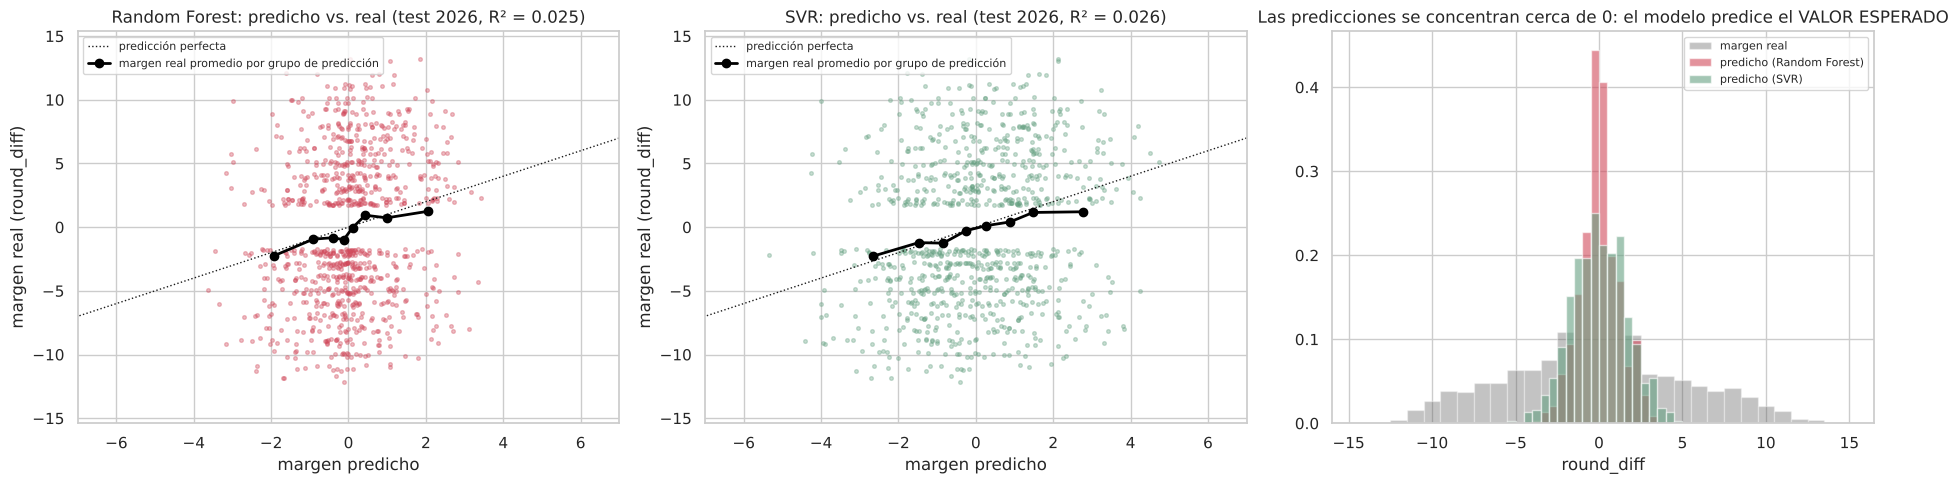

Random Forest     : desviación estándar del margen predicho = 1.16 rondas  vs.  margen real = 5.95 rondas
SVR               : desviación estándar del margen predicho = 1.65 rondas  vs.  margen real = 5.95 rondas


In [ ]:
#@title **GRÁFICA 2:** margen predicho vs. margen real y distribución de las predicciones (los dos mejores)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
jit = np.random.default_rng(SEED).uniform(-.3, .3, len(r_te))
for ax, m in zip(axes[:2], TOP2):
    ax.scatter(P_TEST[m], r_te + jit, s=7, alpha=.35, color=COLORES[m])
    ax.plot([-14, 14], [-14, 14], "k:", lw=1, label="predicción perfecta")
    medias_pred = pd.DataFrame({"p": P_TEST[m], "r": r_te.values}).groupby(pd.qcut(P_TEST[m], 8, duplicates="drop"), observed=True).mean()
    ax.plot(medias_pred.p, medias_pred.r, "o-", color="black", lw=2, label="margen real promedio por grupo de predicción")
    ax.set_xlim(-7, 7); ax.set_xlabel("margen predicho"); ax.set_ylabel("margen real (round_diff)")
    ax.set_title(f"{NOMBRES[m]}: predicho vs. real (test 2026, R² = {r2_score(r_te, P_TEST[m]):.3f})"); ax.legend(fontsize=8, loc="upper left")
bins = np.arange(-14.5, 15.5, 1)
axes[2].hist(r_te, bins=bins, alpha=.35, color="#555555", label="margen real", density=True)
for m in TOP2:
    axes[2].hist(P_TEST[m], bins=np.arange(-14.5, 15.5, 0.5), alpha=.6, color=COLORES[m], label=f"predicho ({NOMBRES[m]})", density=True)
axes[2].set_xlabel("round_diff"); axes[2].set_title("Las predicciones se concentran cerca de 0: el modelo predice el VALOR ESPERADO"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
for m in TOP2:
    print(f"{NOMBRES[m]:18s}: desviación estándar del margen predicho = {np.std(P_TEST[m]):.2f} rondas  vs.  margen real = {np.std(r_te):.2f} rondas")

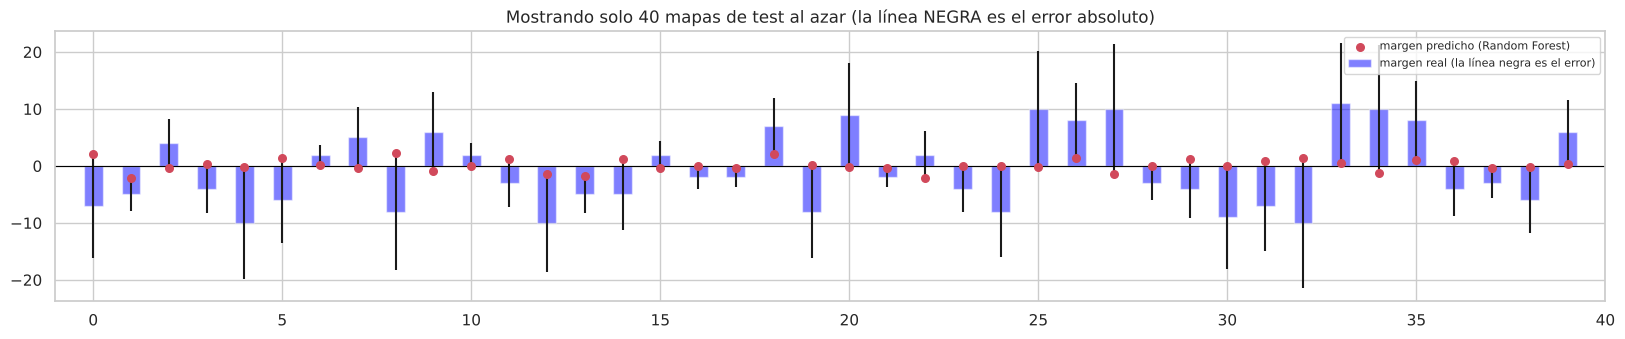

In [ ]:
#@title **GRÁFICA 3 (como en clase):** 40 mapas de test al azar — margen real y error del mejor modelo
plt.figure(figsize=(20, 3.5))
preds = P_TEST[GANADOR]
errs = np.abs(r_te.values - preds)                                      # cálculo del error
perm = np.random.default_rng(SEED).permutation(range(len(r_te)))[:40]   # selección aleatoria de mapas de test
plt.bar(x=range(len(perm)), height=r_te.values[perm], width=0.5, yerr=errs[perm], color="blue", alpha=.5, label="margen real (la línea negra es el error)")
plt.scatter(range(len(perm)), preds[perm], color=COLORES[GANADOR], zorder=3, s=30, label=f"margen predicho ({NOMBRES[GANADOR]})")
plt.axhline(0, color="black", lw=.8); plt.xlim(-1, len(perm)); plt.legend(fontsize=8)
plt.title(f"Mostrando solo {len(perm)} mapas de test al azar (la línea NEGRA es el error absoluto)"); plt.show()

In [ ]:
#@title **CODE:** ¿la diferencia entre el 1.º y el 2.º es real? (bootstrap pareado + prueba de Wilcoxon)
e1, e2_ = np.abs(r_te.values - P_TEST[TOP2[0]]), np.abs(r_te.values - P_TEST[TOP2[1]])
rng = np.random.default_rng(SEED); idx = rng.integers(0, len(e1), size=(2000, len(e1)))
dif = np.sqrt((e1[idx] ** 2).mean(1)) - np.sqrt((e2_[idx] ** 2).mean(1))
lo, hi = np.quantile(dif, [0.025, 0.975])
print(f"RMSE test: {NOMBRES[TOP2[0]]} {rmse(r_te, P_TEST[TOP2[0]]):.3f}  vs  {NOMBRES[TOP2[1]]} {rmse(r_te, P_TEST[TOP2[1]]):.3f}")
print(f"Diferencia de RMSE (1.º − 2.º): {dif.mean():+.3f} rondas, IC 95 % [{lo:+.3f}, {hi:+.3f}]")
p_w = stats.wilcoxon(e1, e2_).pvalue
print("→ En RMSE:", "diferencia estadísticamente significativa." if (hi < 0 or lo > 0) else "NO hay evidencia de que uno sea mejor que el otro (el intervalo incluye el 0).")
mejor_mae = TOP2[0] if e1.mean() < e2_.mean() else TOP2[1]
print(f"MAE test: {NOMBRES[TOP2[0]]} {e1.mean():.3f}  vs  {NOMBRES[TOP2[1]]} {e2_.mean():.3f}  ·  prueba de Wilcoxon sobre los errores absolutos de cada mapa: p-valor = {p_w:.3f}")
print("→ En error absoluto:", f"el {NOMBRES[mejor_mae]} se equivoca por menos rondas en el mapa típico (p < 0.05), aunque en RMSE (que castiga las palizas) empatan." if p_w < 0.05 else "tampoco hay diferencia significativa.")
print("\nComparación del 1.º contra las líneas base (bootstrap pareado de la diferencia de RMSE; negativo = el modelo es mejor):")
for nb, pred in [("Siempre 0", np.zeros(len(r_te))), ("Regla Elo por deciles", regla_elo_deciles(X_dev, r_dev, X_te))]:
    d_ = np.sqrt((e1[idx] ** 2).mean(1)) - np.sqrt(((r_te.values - pred)[idx] ** 2).mean(1))
    print(f"   {NOMBRES[TOP2[0]]} vs. {nb:22s}: diferencia de RMSE {d_.mean():+.3f}, IC 95 % [{np.quantile(d_, .025):+.3f}, {np.quantile(d_, .975):+.3f}]")

RMSE test: Random Forest 5.874  vs  SVR 5.873
Diferencia de RMSE (1.º − 2.º): +0.001 rondas, IC 95 % [-0.040, +0.044]
→ En RMSE: NO hay evidencia de que uno sea mejor que el otro (el intervalo incluye el 0).
MAE test: Random Forest 5.089  vs  SVR 5.009  ·  prueba de Wilcoxon sobre los errores absolutos de cada mapa: p-valor = 0.000
→ En error absoluto: el SVR se equivoca por menos rondas en el mapa típico (p < 0.05), aunque en RMSE (que castiga las palizas) empatan.

Comparación del 1.º contra las líneas base (bootstrap pareado de la diferencia de RMSE; negativo = el modelo es mejor):
   Random Forest vs. Siempre 0             : diferencia de RMSE -0.081, IC 95 % [-0.153, -0.008]
   Random Forest vs. Regla Elo por deciles : diferencia de RMSE +0.015, IC 95 % [-0.034, +0.063]


### 📖 Lectura de la comparación final de regresión
- **Los dos mejores (elegidos antes de ver 2026) son el Random Forest (RF-24) y el SVR (SVR-22).** El árbol queda tercero. La diferencia de puntaje entre los tres es de ≈ 0.02 rondas, mucho menor que el error estándar (±0.13): en la práctica están empatados, y el orden lo decide el protocolo.
- **En 2026 se confirma lo mismo:** RF RMSE **5.874**, SVR **5.873**, árbol 5.904, todos con R² ≈ 0.015–0.026 e intervalos de confianza que se superponen por completo. El bootstrap pareado entre el RF y el SVR da una diferencia de RMSE de +0.001 rondas (IC que incluye el 0). En **MAE** el SVR sí es mejor (5.01 contra 5.09, Wilcoxon p < 0.05): se equivoca por menos rondas en el mapa típico, aunque en RMSE (que castiga las palizas) empatan.
- **Afinar fue indispensable:** con los valores por defecto, el árbol tiene RMSE **8.49 (R² = −1.04)** y el Random Forest **6.07 (R² = −0.04)**. Los dos son **peores que predecir siempre 0**. Afinar sirvió sobre todo para **evitar el sobreajuste**, exactamente como en clasificación. El SVR por defecto ya era razonable (5.91).
- **Frente a las líneas base:** los modelos **sí superan** a "siempre 0" (diferencia de RMSE ≈ −0.08 rondas, IC 95 % completamente negativo), pero **no superan** a la regla Elo por deciles (5.86). Es la misma historia de la clasificación: **los modelos terminan reproduciendo la regla del Elo**, ahora en rondas.
- **Las predicciones se concentran cerca de 0** (desviación estándar de ≈ 1.2–1.7 rondas contra ≈ 6 del margen real). No es un error: el modelo predice el **valor esperado** del margen dado lo que se sabe antes del mapa. Como nadie puede anticipar un 13-2, lo óptimo (para el MSE) es predecir márgenes moderados. Por eso el R² es bajo aunque el modelo esté bien entrenado. En la gráfica de predicho contra real, la línea negra (promedio real por grupo de predicción) **sube con la predicción**: los mapas a los que el modelo les da ventaja a A terminan, en promedio, con ventaja de A (≈ +1.2 a +1.3 rondas cuando predice +2 o más), y los de ventaja de B con ventaja de B (≈ −2 rondas). Es algo más plana que la diagonal: en los extremos los modelos son un poco optimistas.
- **Acierto del ganador:** ≈ 58 % con el signo del margen predicho, algo por debajo del GNB binario (59.1 %) y de la regla Elo (59.4 %). La regresión optimiza el tamaño del margen, no el signo.

## 12. Del margen predicho a la probabilidad y a la cuota

El modelo de regresión predice el **margen esperado** $\hat{y}$. Para un casino eso se convierte en probabilidades con una idea sencilla: el margen real es el predicho **más un error**, y ese error tiene una desviación típica $\sigma$ que medimos con los residuos de entrenamiento (2024–2025). Si aproximamos el error con una normal:

$$P(\text{gana A}) = P(\text{round\_diff} > 0) \approx \Phi\!\left(\frac{\hat{y}}{\sigma}\right) \qquad\qquad P(\text{A gana por 5 o más}) \approx 1-\Phi\!\left(\frac{4.5-\hat{y}}{\sigma}\right)$$

donde $\Phi$ es la función de distribución de la normal estándar. Con esas probabilidades salen la **cuota de ganador** ($1/P$) y la **cuota del hándicap −4.5** (el mismo corte que usaremos en la parte multiclase). Así comparamos la regresión con los clasificadores del notebook anterior **con sus mismas métricas** (accuracy, AUC, log-loss, Brier).

> Es una aproximación: el margen real no es normal (no existen márgenes de −1, 0 ni +1), pero sirve para traducir el margen a probabilidad.

In [ ]:
#@title **CODE:** probabilidad de victoria a partir del margen y comparación con los clasificadores
def prob_desde_margen(pred, sigma, umbral=0.0):
    """P(round_diff > umbral) suponiendo error normal con desviación sigma."""
    return 1 - stats.norm.cdf((umbral - np.asarray(pred)) / sigma)

SIGMA = {m: np.std(r_dev.values - P_DEV[m]) for m in NOMBRES}       # desviación de los residuos en 2024-2025
P_WIN = {m: prob_desde_margen(P_TEST[m], SIGMA[m]) for m in NOMBRES}

def metricas_prob(y_true, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return {"accuracy": accuracy_score(y_true, p >= .5), "AUC": roc_auc_score(y_true, p), "log-loss": log_loss(y_true, p), "Brier": brier_score_loss(y_true, p)}

filas = [{"Modelo": f"{NOMBRES[m]} regresor → Φ(ŷ/σ)", "σ (rondas)": SIGMA[m], **metricas_prob(y_te, P_WIN[m])} for m in NOMBRES]
# Resultados en test 2026 del notebook de clasificación (mismas variables, misma partición) para comparar:
CLASIF_NB2 = {"Gaussian NB (ganador en clasificación)": (0.5914, 0.6098, 0.6782, 0.2422), "SVM clasificador": (0.5880, 0.6089, 0.6779, 0.2422),
              "Árbol clasificador": (0.5835, 0.5980, 0.6764, 0.2417), "Random Forest clasificador": (0.5711, 0.6094, 0.6766, 0.2418)}
for k, (a, auc, ll, br) in CLASIF_NB2.items():
    filas.append({"Modelo": k, "σ (rondas)": np.nan, "accuracy": a, "AUC": auc, "log-loss": ll, "Brier": br})
p_elo_te = 1 / (1 + 10 ** (-X_te["elo_diff"].values / 400))
filas.append({"Modelo": "Regla 'mayor Elo' (probabilidad del Elo)", "σ (rondas)": np.nan, **metricas_prob(y_te, p_elo_te)})
comp_prob = pd.DataFrame(filas).set_index("Modelo")
display(comp_prob.round(4))
print(f"Azar puro: accuracy 0.5, log-loss {np.log(2):.4f}, Brier 0.25")

,σ (rondas),accuracy,AUC,log-loss,Brier
Modelo,,,,,
Árbol de decisión regresor → Φ(ŷ/σ),5.7562,0.5700,0.5901,0.6832,0.2446
Random Forest regresor → Φ(ŷ/σ),5.6261,0.5824,0.6027,0.6789,0.2429
SVR regresor → Φ(ŷ/σ),5.7746,0.5813,0.6110,0.6744,0.2408
Gaussian NB (ganador en clasificación),NaN,0.5914,0.6098,0.6782,0.2422
SVM clasificador,NaN,0.5880,0.6089,0.6779,0.2422
Árbol clasificador,NaN,0.5835,0.5980,0.6764,0.2417
Random Forest clasificador,NaN,0.5711,0.6094,0.6766,0.2418
Regla 'mayor Elo' (probabilidad del Elo),NaN,0.5937,0.6098,0.6795,0.2428


Azar puro: accuracy 0.5, log-loss 0.6931, Brier 0.25


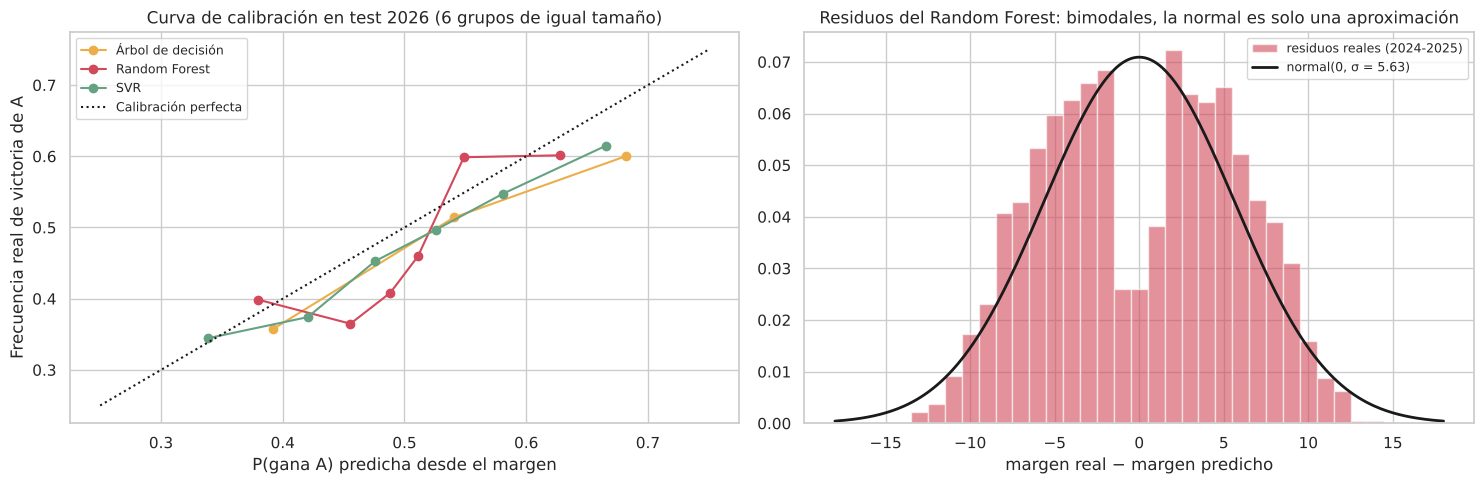

In [ ]:
#@title **GRÁFICA:** ¿son creíbles esas probabilidades? (calibración) y forma real de los residuos
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for m in NOMBRES:
    fo, mp = calibration_curve(y_te, P_WIN[m], n_bins=6, strategy="quantile"); ax[0].plot(mp, fo, "o-", color=COLORES[m], label=NOMBRES[m])
ax[0].plot([0.25, 0.75], [0.25, 0.75], "k:", label="Calibración perfecta"); ax[0].set_xlabel("P(gana A) predicha desde el margen"); ax[0].set_ylabel("Frecuencia real de victoria de A")
ax[0].set_title("Curva de calibración en test 2026 (6 grupos de igual tamaño)"); ax[0].legend(fontsize=9)
res = r_dev.values - P_DEV[GANADOR]
ax[1].hist(res, bins=np.arange(-17.5, 18.5, 1), density=True, color=COLORES[GANADOR], alpha=.6, label="residuos reales (2024-2025)")
xs = np.linspace(-18, 18, 300); ax[1].plot(xs, stats.norm.pdf(xs, 0, SIGMA[GANADOR]), "k-", lw=2, label=f"normal(0, σ = {SIGMA[GANADOR]:.2f})")
ax[1].set_xlabel("margen real − margen predicho"); ax[1].set_title(f"Residuos del {NOMBRES[GANADOR]}: bimodales, la normal es solo una aproximación"); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
#@title **CODE:** ejemplo de uso — cuotas de ganador y de hándicap para los primeros mapas de 2026
import joblib
cols_g = construir_modelo(GANADOR, mejores[GANADOR]["params"])[1]
joblib.dump({"modelo": modelos_dev[GANADOR], "columnas": cols_g, "params": mejores[GANADOR]["params"], "sigma": SIGMA[GANADOR],
             "nombre": NOMBRES[GANADOR] + " regresor (objetivo: round_diff)"}, "modelo_regresion_VCT.joblib")
print(f"✔ Modelo guardado: modelo_regresion_VCT.joblib  ({NOMBRES[GANADOR]} regresor, variables: {cols_g}, σ = {SIGMA[GANADOR]:.2f})")

ej = df.iloc[idx_test][["tournament", "team_a", "team_b", "map", "score_a", "score_b"]].head(10).reset_index(drop=True)
pred = P_TEST[GANADOR][:10]; s = SIGMA[GANADOR]
ej["margen predicho"] = pred.round(2); ej["margen real"] = (ej.score_a - ej.score_b)
ej["P(gana A)"] = prob_desde_margen(pred, s).round(3); ej["cuota A"] = (1 / ej["P(gana A)"]).round(2); ej["cuota B"] = (1 / (1 - ej["P(gana A)"])).round(2)
ej["P(A −4.5)"] = prob_desde_margen(pred, s, 4.5).round(3); ej["cuota A −4.5"] = (1 / ej["P(A −4.5)"]).round(2)
ej["P(B −4.5)"] = (1 - prob_desde_margen(pred, s, -4.5)).round(3); ej["cuota B −4.5"] = (1 / ej["P(B −4.5)"]).round(2)
display(ej.drop(columns=["score_a", "score_b"]))
try:
    from google.colab import files; files.download("modelo_regresion_VCT.joblib")
except Exception:
    pass

✔ Modelo guardado: modelo_regresion_VCT.joblib  (Random Forest regresor, variables: ['elo_diff', 'wr_all_diff', 'wr_10_diff', 'rd_10_diff', 'acs_10_diff', 'map_wr_diff', 'picker', 'hist_min'], σ = 5.63)


,tournament,team_a,team_b,map,margen predicho,margen real,P(gana A),cuota A,cuota B,P(A −4.5),cuota A −4.5,P(B −4.5),cuota B −4.5
0,VCT 2026: EMEA Kickoff,Natus Vincere,Karmine Corp,Split,0.02,2,0.502,1.99,2.01,0.213,4.69,0.211,4.74
1,VCT 2026: EMEA Kickoff,Natus Vincere,Karmine Corp,Haven,0.04,6,0.503,1.99,2.01,0.214,4.67,0.210,4.76
2,VCT 2026: EMEA Kickoff,FUT Esports,Gentle Mates,Abyss,1.40,-5,0.598,1.67,2.49,0.291,3.44,0.147,6.80
3,VCT 2026: EMEA Kickoff,FUT Esports,Gentle Mates,Split,0.89,-7,0.563,1.78,2.29,0.261,3.83,0.169,5.92
4,VCT 2026: EMEA Kickoff,PCIFIC Esports,BBL Esports,Breeze,-0.32,-3,0.477,2.10,1.91,0.196,5.10,0.229,4.37
5,VCT 2026: EMEA Kickoff,PCIFIC Esports,BBL Esports,Abyss,-0.47,6,0.467,2.14,1.88,0.188,5.32,0.237,4.22
6,VCT 2026: EMEA Kickoff,PCIFIC Esports,BBL Esports,Pearl,-0.03,-9,0.498,2.01,1.99,0.210,4.76,0.214,4.67
7,VCT 2026: EMEA Kickoff,ULF Esports,Team Vitality,Breeze,0.06,-10,0.504,1.98,2.02,0.215,4.65,0.209,4.78
8,VCT 2026: EMEA Kickoff,ULF Esports,Team Vitality,Corrode,-0.32,-12,0.478,2.09,1.92,0.196,5.10,0.229,4.37
9,VCT 2026: EMEA Kickoff,Team Heretics,Natus Vincere,Bind,-0.39,-3,0.472,2.12,1.89,0.192,5.21,0.233,4.29


### 📖 Lectura: del margen a la cuota
- Con σ ≈ 5.6–5.8 rondas, el **SVR regresor convertido a probabilidad** obtiene en 2026 accuracy **0.581**, AUC **0.611**, **log-loss 0.674 y Brier 0.241**: las **mejores probabilidades de toda la tabla**, por encima del GNB ganador de clasificación (log-loss 0.678, Brier 0.242) y del Elo (0.680). Las diferencias son muy pequeñas, pero muestran que **predecir el margen no pierde nada frente a predecir el ganador** y además permite cotizar otros mercados.
- **Calibración:** las probabilidades del SVR siguen bien la diagonal. Las del Random Forest zigzaguean más (con predicciones tan concentradas, pocos mapas llegan a los extremos).
- **Los residuos son bimodales** (hay un hueco cerca de 0 porque no existen márgenes de −1, 0 ni +1), así que la normal es solo una aproximación. Aun así basta para traducir el margen a probabilidad de ganar.
- **En el ejemplo de 2026**, casi todas las cuotas quedan cerca de 2.0 / 2.0 y las del hándicap −4.5 cerca de 4.5–5.0 por lado (≈ 21 % de probabilidad). El modelo ve la mayoría de los enfrentamientos como muy parejos. El tercer mapa muestra el ruido del problema: el modelo daba +1.4 rondas a FUT y Gentle Mates ganó por 5.

## 13. Clasificación multiclase: ¿quién gana y por cuánto?

### 13.1 ¿Cómo se subdividió la variable objetivo?

La clasificación binaria responde "¿quién gana?". La multiclase agrega **"¿por cuánto?"**, partiendo el margen real `round_diff` en **4 clases**:

| Clase | Nombre | Condición | Ejemplo de marcador |
|---|---|---|---|
| 0 | **B gana cómodo** | `round_diff ≤ −5` | 8-13, 3-13 |
| 1 | **B gana ajustado** | `−4 ≤ round_diff ≤ −2` | 11-13, 9-13, 12-14 (OT) |
| 2 | **A gana ajustado** | `2 ≤ round_diff ≤ 4` | 13-11, 13-9, 14-12 (OT) |
| 3 | **A gana cómodo** | `round_diff ≥ 5` | 13-8, 13-3 |

**¿Por qué así?**
- **Umbral de 5 rondas:** la **mediana** de |round_diff| es 5, así que las cuatro clases quedan **casi balanceadas** (~25 % cada una; lo comprobamos abajo con otros umbrales). Además coincide con el mercado de **hándicap −4.5** de las casas de apuestas.
- **No hay una clase "empate" ni "parejo" sin ganador:** en VALORANT siempre hay ganador (con overtime), y una clase "parejo" perdería la información de quién ganó.
- **Cuatro clases y no más:** con más cortes (p. ej. 13-0 a 13-2) habría clases con muy pocos mapas y el modelo no podría aprenderlas.
- **Es coherente con la binaria:** juntando las clases 2 y 3 se recupera exactamente `team_a_wins`. Así podemos medir si la multiclase pierde o gana algo frente al modelo binario.

,umbral 'cómodo',B cómodo,B ajustado,A ajustado,A cómodo,clase más chica (%),clase más grande (%)
0,≥ 3 rondas,35.8,12.8,10.0,41.5,10.0,41.5
1,≥ 4 rondas,30.3,18.2,16.4,35.1,16.4,35.1
2,≥ 5 rondas,24.7,23.9,21.7,29.8,21.7,29.8
3,≥ 6 rondas,19.8,28.7,28.3,23.1,19.8,28.7
4,≥ 7 rondas,14.4,34.1,33.3,18.1,14.4,34.1


✔ Juntando 'A ajustado' + 'A cómodo' se recupera exactamente team_a_wins.



,Train,Validación,Test 2026
% de mapas,,,
B cómodo (≥5),24.9,24.2,28.1
B ajustado (2-4),23.7,24.3,24.7
A ajustado (2-4),21.3,22.8,22.0
A cómodo (≥5),30.1,28.7,25.2


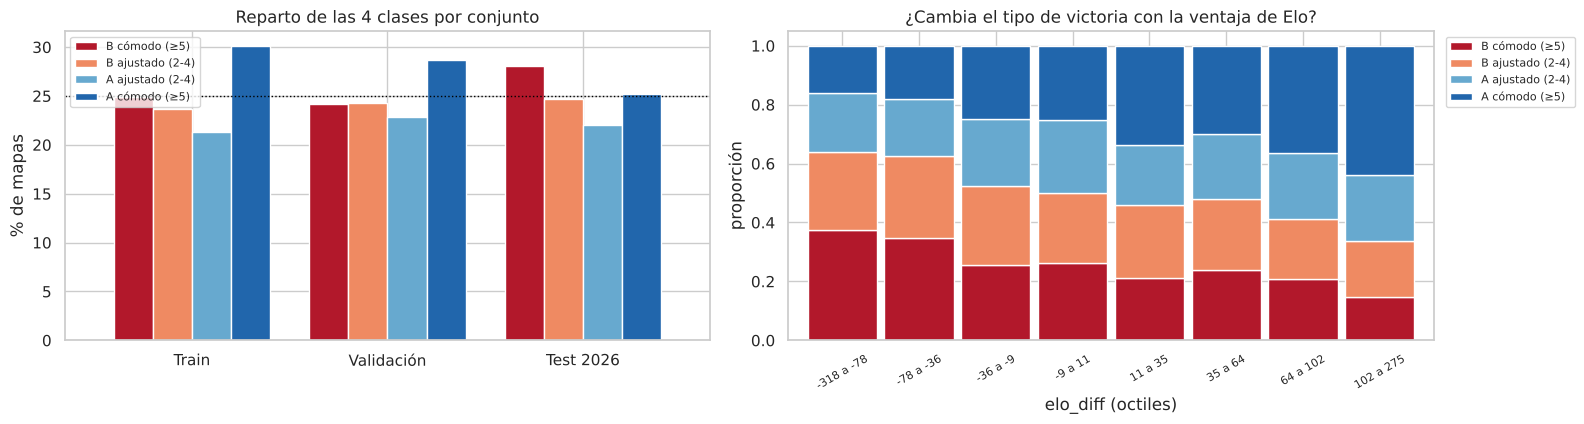

In [ ]:
#@title **CODE:** construcción de las 4 clases y elección del umbral
CLASES = ["B cómodo (≥5)", "B ajustado (2-4)", "A ajustado (2-4)", "A cómodo (≥5)"]
COLORES_CLASE = ["#b2182b", "#ef8a62", "#67a9cf", "#2166ac"]
UMBRAL_COMODO = 5

def a_clase(rd, umbral=UMBRAL_COMODO):
    rd = np.asarray(rd)
    return np.select([rd <= -umbral, rd < 0, rd < umbral], [0, 1, 2], 3)

# ¿Por qué 5? -> reparto de clases en 2024-2025 con distintos umbrales
filas = []
for u in [3, 4, 5, 6, 7]:
    rep = np.bincount(a_clase(y_reg.iloc[idx_dev], u), minlength=4) / len(idx_dev) * 100
    filas.append({"umbral 'cómodo'": f"≥ {u} rondas", **{CLASES[k].split(" (")[0]: rep[k] for k in range(4)}, "clase más chica (%)": rep.min(), "clase más grande (%)": rep.max()})
display(pd.DataFrame(filas).round(1))

y_mc = pd.Series(a_clase(y_reg), index=df.index)
assert ((y_mc >= 2).astype(int) == y).all(), "juntando las clases 2 y 3 debe salir exactamente team_a_wins"
c_tr, c_va, c_te, c_dev = y_mc.iloc[idx_tr], y_mc.iloc[idx_va], y_mc.iloc[idx_test], y_mc.iloc[idx_dev]
print("✔ Juntando 'A ajustado' + 'A cómodo' se recupera exactamente team_a_wins.\n")

reparto = pd.DataFrame({nombre: pd.Series(c).value_counts(normalize=True).sort_index().values * 100
                        for nombre, c in [("Train", c_tr), ("Validación", c_va), ("Test 2026", c_te)]}, index=CLASES)
display(reparto.round(1).rename_axis("% de mapas"))

fig, ax = plt.subplots(1, 2, figsize=(16, 4.4))
reparto.T.plot.bar(ax=ax[0], color=COLORES_CLASE, width=.8); ax[0].axhline(25, color="black", ls=":", lw=1)
ax[0].set_ylabel("% de mapas"); ax[0].set_title("Reparto de las 4 clases por conjunto"); ax[0].tick_params(axis="x", rotation=0); ax[0].legend(fontsize=8)
dec = pd.qcut(X["elo_diff"], 8)
pd.crosstab(dec, y_mc, normalize="index").set_axis(CLASES, axis=1).plot.bar(stacked=True, ax=ax[1], color=COLORES_CLASE, width=.9)
ax[1].set_xticklabels([f"{i.left:.0f} a {i.right:.0f}" for i in dec.cat.categories], rotation=30, fontsize=8)
ax[1].set_xlabel("elo_diff (octiles)"); ax[1].set_ylabel("proporción"); ax[1].set_title("¿Cambia el tipo de victoria con la ventaja de Elo?"); ax[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout(); plt.show()

### 13.2 Protocolo, métricas y líneas base de la multiclase

- **Misma partición** temporal (train / validación / test 2026) y misma validación cruzada temporal.
- **Mismos cuatro clasificadores** del notebook de clasificación: **GNB, Árbol de decisión, Random Forest y SVM** (sklearn los extiende a varias clases directamente; la SVM lo hace con el esquema *uno-contra-uno*).
- **Métrica de selección: F1-macro** (el promedio del F1 de las 4 clases). No usamos la accuracy para elegir porque un modelo que **nunca** predice las clases "ajustadas" puede tener una accuracy decente y aun así no servir para el hándicap; el F1-macro castiga eso.
  $$\text{score}_{MC} = \tfrac{1}{2}\big(\text{F1-macro en validación} + \text{F1-macro medio en CV temporal}\big)$$
- **Condición para competir:** el casino usa las **probabilidades** para fijar la cuota del hándicap. Una configuración cuyas probabilidades son **peores que no mirar el mapa** (log-loss de validación ≥ ln 4 ≈ 1.386) no sirve aunque acierte algunas clases, así que **solo compiten las configuraciones con log-loss de validación < ln 4**. Las que no cumplen quedan registradas, marcadas con ✗.
- También reportamos **accuracy** (azar = 25 %), **log-loss multiclase** (azar = ln 4 ≈ 1.386) y la **accuracy binaria derivada** (si P(clase 2) + P(clase 3) ≥ 0.5 → gana A), para comparar con la clasificación binaria.
- La perilla **`espejo`** también funciona aquí: al invertir A↔B, la clase *k* pasa a ser la clase *3 − k* ("A cómodo" ↔ "B cómodo").

In [ ]:
#@title **CODE:** líneas base de la multiclase
def metricas_mc(y_true, P):
    """Accuracy, F1-macro, log-loss y accuracy binaria derivada a partir de la matriz de probabilidades (n x 4)."""
    y_true = np.asarray(y_true); pred = P.argmax(1)
    return {"acc": accuracy_score(y_true, pred), "f1m": f1_score(y_true, pred, average="macro", labels=[0, 1, 2, 3], zero_division=0),
            "ll": log_loss(y_true, np.clip(P, 1e-6, 1), labels=[0, 1, 2, 3]), "acc_bin": accuracy_score(y_true >= 2, P[:, 2] + P[:, 3] >= 0.5)}

def onehot(pred):
    P = np.full((len(pred), 4), 0.02); P[np.arange(len(pred)), pred] = 0.94; return P      # reglas sin probabilidad: 94 % a la clase elegida

def regla_elo_cuartiles(X_ajuste, X_pred):
    """Regla simple: ordenar los mapas por ventaja de Elo y asignar cada cuartil a una clase (mucha desventaja -> 'B cómodo')."""
    cortes = np.quantile(X_ajuste["elo_diff"], [.25, .5, .75])
    return np.digitize(X_pred["elo_diff"], cortes)

filas = []
for nombre, (X_aj, c_aj, X_ev, c_ev) in {"Validación": (X_tr, c_tr, X_va, c_va), "Test 2026": (X_dev, c_dev, X_te, c_te)}.items():
    mayor = np.bincount(c_aj).argmax(); frec = np.bincount(c_aj, minlength=4) / len(c_aj)
    reglas = [("Clase mayoritaria del entrenamiento", onehot(np.full(len(c_ev), mayor))),
              ("Frecuencias del entrenamiento (sin mirar el mapa)", np.tile(frec, (len(c_ev), 1))),
              ("Regla Elo por cuartiles", onehot(regla_elo_cuartiles(X_aj, X_ev)))]
    for base, P in reglas:
        mt = metricas_mc(c_ev, P)
        if base.startswith("Frecuencias"): mt["acc_bin"] = np.nan
        else: mt["ll"] = np.nan          # una regla que solo elige clase no da probabilidades: su log-loss no tiene sentido
        filas.append({"Conjunto": nombre, "Línea base": base, "accuracy": mt["acc"], "F1-macro": mt["f1m"], "log-loss": mt["ll"], "accuracy binaria derivada": mt["acc_bin"]})
bases_mc = pd.DataFrame(filas)
display(bases_mc.round(4))
F1_ELO_VAL = bases_mc.query("Conjunto == 'Validación'").iloc[2]["F1-macro"]
print(f"Referencias de azar: accuracy 0.25 · log-loss ln(4) = {np.log(4):.4f}")

,Conjunto,Línea base,accuracy,F1-macro,log-loss,accuracy binaria derivada
0,Validación,Clase mayoritaria del entrenamiento,0.2869,0.1115,NaN,0.5151
1,Validación,Frecuencias del entrenamiento (sin mirar el mapa),0.2869,0.1115,1.3836,NaN
2,Validación,Regla Elo por cuartiles,0.3154,0.2932,NaN,0.5537
3,Test 2026,Clase mayoritaria del entrenamiento,0.2517,0.1005,NaN,0.4718
4,Test 2026,Frecuencias del entrenamiento (sin mirar el mapa),0.2517,0.1005,1.3888,NaN
5,Test 2026,Regla Elo por cuartiles,0.3262,0.3090,NaN,0.5971


Referencias de azar: accuracy 0.25 · log-loss ln(4) = 1.3863


In [ ]:
#@title **CODE:** infraestructura de la multiclase (misma idea de `prueba()`: cada experimento queda registrado)
REGISTRO_MC = []
UMBRAL_RUIDO_MC = 0.003

class EspejoMC(ClassifierMixin, BaseEstimator):
    """Clasificador simétrico A/B para 4 clases: al invertir el mapa, la clase k pasa a ser 3 - k."""
    def __init__(self, estimador=None, cols_antisim=None):
        self.estimador = estimador; self.cols_antisim = cols_antisim
    def _invertir(self, Xm):
        Xi = Xm.copy(); Xi[self.cols_antisim] = -Xi[self.cols_antisim]; return Xi
    def fit(self, Xm, ym):
        ym = np.asarray(ym)
        self.estimador_ = clone(self.estimador).fit(pd.concat([Xm, self._invertir(Xm)], ignore_index=True), np.concatenate([ym, 3 - ym]))
        self.classes_ = np.arange(4); return self
    def predict_proba(self, Xm):
        return (self.estimador_.predict_proba(Xm) + self.estimador_.predict_proba(self._invertir(Xm))[:, ::-1]) / 2
    def predict(self, Xm):
        return self.predict_proba(Xm).argmax(1)

def construir_mc(modelo, params):
    p = dict(params); fs = p.pop("features"); espejo = p.pop("espejo", False); cols = CONJUNTOS[fs]
    if   modelo == "GNB": est = GaussianNB(**p)
    elif modelo == "DT":  est = DecisionTreeClassifier(random_state=SEED, **p)
    elif modelo == "RF":  est = RandomForestClassifier(random_state=SEED, n_jobs=-1, **p)
    elif modelo == "SVM": est = make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED, **p))
    if espejo:
        est = EspejoMC(est, [c for c in cols if c.endswith("_diff") or c == "picker"])
    return est, cols

def evaluar_mc(est, cols):
    t0 = time.time(); est.fit(X_tr[cols], c_tr)
    m_tr, m_va = metricas_mc(c_tr, est.predict_proba(X_tr[cols])), metricas_mc(c_va, est.predict_proba(X_va[cols]))
    dur = time.time() - t0; f1s, accs = [], []
    for a, b in TimeSeriesSplit(n_splits=5).split(X_tr):
        m = clone(est).fit(X_tr.iloc[a][cols], c_tr.iloc[a]); P = m.predict_proba(X_tr.iloc[b][cols])
        f1s.append(f1_score(c_tr.iloc[b], P.argmax(1), average="macro", labels=[0, 1, 2, 3], zero_division=0)); accs.append(accuracy_score(c_tr.iloc[b], P.argmax(1)))
    return m_tr, m_va, np.mean(f1s), np.std(f1s), np.mean(accs), dur

LL_AZAR = np.log(4)                      # log-loss de no mirar el mapa (4 clases equiprobables)
def clave_mc(r):
    """Primero las configuraciones 'aptas' (log-loss de validación mejor que el azar) y, entre ellas, el mayor puntaje."""
    return (r["val_ll"] < LL_AZAR, r["score_sel"])

def mejor_guiada_mc(modelo):
    cand = [r for r in REGISTRO_MC if r["modelo"] == modelo]
    return max(cand, key=clave_mc) if cand else None     # en empate conserva la más antigua

def prueba_mc(modelo, cambios=None, hipotesis="", params=None):
    ref = mejor_guiada_mc(modelo)
    if params is None:
        params = {**ref["params"], **cambios}; que_cambio = " | ".join(f"{k}: {ref['params'].get(k, '—')} → {v}" for k, v in cambios.items())
    else:
        que_cambio = "(configuración inicial)"
    est, cols = construir_mc(modelo, params)
    m_tr, m_va, cv_f1, cv_std, cv_acc, dur = evaluar_mc(est, cols)
    score = (m_va["f1m"] + cv_f1) / 2; delta = score - ref["score_sel"] if ref else np.nan
    apto, apto_ref = m_va["ll"] < LL_AZAR, (ref["val_ll"] < LL_AZAR if ref else None)
    if ref is None:            veredicto = "base"
    elif apto and not apto_ref: veredicto = "▲ mejora (ya no es peor que el azar)"
    elif apto_ref and not apto: veredicto = "▼ empeora (log-loss peor que el azar)"
    else: veredicto = "▲ mejora" if delta >= UMBRAL_RUIDO_MC else ("▼ empeora" if delta <= -UMBRAL_RUIDO_MC else "≈ igual")
    n = sum(f["modelo"] == modelo for f in REGISTRO_MC) + 1
    fila = {"id": f"MC-{modelo}-{n:02d}", "modelo": modelo, "referencia": ref["id"] if ref else "—", "cambió": que_cambio, "hipótesis": hipotesis,
            "params": params, "train_f1m": m_tr["f1m"], "val_acc": m_va["acc"], "val_f1m": m_va["f1m"], "val_ll": m_va["ll"], "val_acc_bin": m_va["acc_bin"],
            "cv_f1m": cv_f1, "cv_std": cv_std, "cv_acc": cv_acc, "apto": bool(m_va["ll"] < LL_AZAR), "gap": m_tr["f1m"] - m_va["f1m"], "score_sel": score, "delta_vs_ref": delta,
            "veredicto": veredicto, "t_seg": dur}
    REGISTRO_MC.append(fila)
    print(f"[{fila['id']}] {que_cambio:<44s} | F1m train {fila['train_f1m']:.3f}  val {fila['val_f1m']:.3f}  cv {cv_f1:.3f}±{cv_std:.3f}  "
          f"acc val {fila['val_acc']:.3f}  ll {fila['val_ll']:.3f} | {veredicto}")
    return fila
print("Infraestructura multiclase lista.")

Infraestructura multiclase lista.


In [ ]:
#@title **EXPERIMENTOS MULTICLASE** — los mismos cuatro clasificadores, cada línea es una prueba registrada
print("— Gaussian NB —")
prueba_mc("GNB", params=dict(features="completa", var_smoothing=1e-9, espejo=False), hipotesis="Línea base: GNB con todas las variables (como en binaria).")
for cambios, hip in [(dict(var_smoothing=1e-2), "Suavizar las varianzas: con 29 variables el GNB es demasiado seguro de sí mismo."),
                     (dict(var_smoothing=1e-1), "Suavizado fuerte."), (dict(features="nucleo"), "Quitar indicadores 0/1 no gaussianos."),
                     (dict(features="basica"), "Solo Elo, win rates y quién eligió."), (dict(features="elo"), "Solo el Elo (fue lo mejor en binaria)."),
                     (dict(priors=[0.25] * 4), "Priors iguales para las 4 clases."), (dict(espejo=True), "Entrenar con el mapa y su versión A↔B.")]:
    prueba_mc("GNB", cambios, hip)

print("\n— Árbol de decisión —")
prueba_mc("DT", params=dict(features="nucleo", criterion="gini", max_depth=None, min_samples_leaf=1, ccp_alpha=0.0, espejo=False), hipotesis="Línea base: árbol sin límite.")
for cambios, hip in [(dict(max_depth=3), "Limitar profundidad a 3."), (dict(max_depth=2), "Solo 2 niveles."), (dict(max_depth=5), "Profundidad 5."),
                     (dict(min_samples_leaf=30), "Hojas de al menos 30 mapas."), (dict(min_samples_leaf=80), "Hojas de al menos 80 mapas."),
                     (dict(criterion="entropy"), "Criterio de entropía."),
                     (dict(features="basica"), "Solo 4 variables."), (dict(espejo=True), "Árbol simétrico A↔B.")]:
    prueba_mc("DT", cambios, hip)

print("\n— Random Forest —")
prueba_mc("RF", params=dict(features="nucleo", n_estimators=100, max_depth=None, min_samples_leaf=1, max_features="sqrt", espejo=False), hipotesis="Línea base: bosque por defecto.")
for cambios, hip in [(dict(min_samples_leaf=10), "Hojas de al menos 10 mapas."), (dict(min_samples_leaf=30), "Hojas de al menos 30 mapas."),
                     (dict(max_depth=6), "Profundidad máxima 6."), (dict(n_estimators=300), "Más árboles."), (dict(max_samples=0.6), "Cada árbol ve el 60 % de los mapas."),
                     (dict(features="completa"), "Las 29 variables."), (dict(espejo=True), "Bosque simétrico A↔B.")]:
    prueba_mc("RF", cambios, hip)

print("\n— SVM —")
prueba_mc("SVM", params=dict(features="nucleo", kernel="rbf", C=1.0, gamma="scale"), hipotesis="Línea base: SVM RBF por defecto.")
for cambios, hip in [(dict(C=0.1), "Bajar C: frontera más suave."), (dict(gamma=0.01), "gamma bajo: frontera casi lineal."), (dict(kernel="linear"), "Kernel lineal."),
                     (dict(class_weight="balanced"), "Pesos balanceados por clase."), (dict(features="elo"), "Solo el Elo."), (dict(espejo=True), "SVM simétrica A↔B.")]:
    prueba_mc("SVM", cambios, hip)

— Gaussian NB —
[MC-GNB-01] (configuración inicial)                      | F1m train 0.321  val 0.292  cv 0.278±0.013  acc val 0.319  ll 1.971 | base
[MC-GNB-02] var_smoothing: 1e-09 → 0.01                  | F1m train 0.244  val 0.276  cv 0.245±0.013  acc val 0.329  ll 1.386 | ▲ mejora (ya no es peor que el azar)
[MC-GNB-03] var_smoothing: 0.01 → 0.1                    | F1m train 0.226  val 0.271  cv 0.222±0.015  acc val 0.334  ll 1.352 | ▼ empeora
[MC-GNB-04] features: completa → nucleo                  | F1m train 0.243  val 0.276  cv 0.244±0.012  acc val 0.329  ll 1.386 | ≈ igual
[MC-GNB-05] features: completa → basica                  | F1m train 0.217  val 0.206  cv 0.221±0.014  acc val 0.319  ll 1.359 | ▼ empeora
[MC-GNB-06] features: completa → elo                     | F1m train 0.217  val 0.206  cv 0.222±0.016  acc val 0.319  ll 1.359 | ▼ empeora
[MC-GNB-07] priors: — → [0.25, 0.25, 0.25, 0.25]         | F1m train 0.296  val 0.284  cv 0.272±0.030  acc val 0.320  ll 1.404 | ▼

✔ 32 pruebas multiclase guardadas en registro_pruebas_multiclase_VCT.csv


,id,referencia,cambió,train_f1m,val_f1m,cv_f1m,val_acc,val_ll,apto,val_acc_bin,gap,score_sel,veredicto
0,MC-GNB-01,—,(configuración inicial),0.3208,0.2917,0.2779,0.3188,1.9713,False,0.5587,0.0291,0.2848,base
1,MC-GNB-02,MC-GNB-01,var_smoothing: 1e-09 → 0.01,0.2439,0.2762,0.2450,0.3289,1.3862,True,0.5621,-0.0323,0.2606,▲ mejora (ya no es peor que el azar)
2,MC-GNB-03,MC-GNB-02,var_smoothing: 0.01 → 0.1,0.2262,0.2707,0.2216,0.3339,1.3523,True,0.5587,-0.0445,0.2462,▼ empeora
3,MC-GNB-04,MC-GNB-02,features: completa → nucleo,0.2429,0.2762,0.2443,0.3289,1.3862,True,0.5621,-0.0333,0.2603,≈ igual
4,MC-GNB-05,MC-GNB-02,features: completa → basica,0.2172,0.2062,0.2211,0.3188,1.3594,True,0.5554,0.0109,0.2137,▼ empeora
5,MC-GNB-06,MC-GNB-02,features: completa → elo,0.2172,0.2062,0.2224,0.3188,1.3595,True,0.5537,0.0109,0.2143,▼ empeora
6,MC-GNB-07,MC-GNB-02,"priors: — → [0.25, 0.25, 0.25, 0.25]",0.2956,0.2843,0.2723,0.3205,1.4041,False,0.5554,0.0113,0.2783,▼ empeora (log-loss peor que el azar)
7,MC-GNB-08,MC-GNB-02,espejo: False → True,0.2457,0.3112,0.2441,0.3356,1.3751,True,0.5671,-0.0655,0.2777,▲ mejora
8,MC-DT-01,—,(configuración inicial),0.9918,0.2819,0.2396,0.2886,9.8285,False,0.5185,0.7099,0.2608,base
9,MC-DT-02,MC-DT-01,max_depth: None → 3,0.3004,0.2493,0.2214,0.3138,1.3781,True,0.5570,0.0511,0.2353,▲ mejora (ya no es peor que el azar)


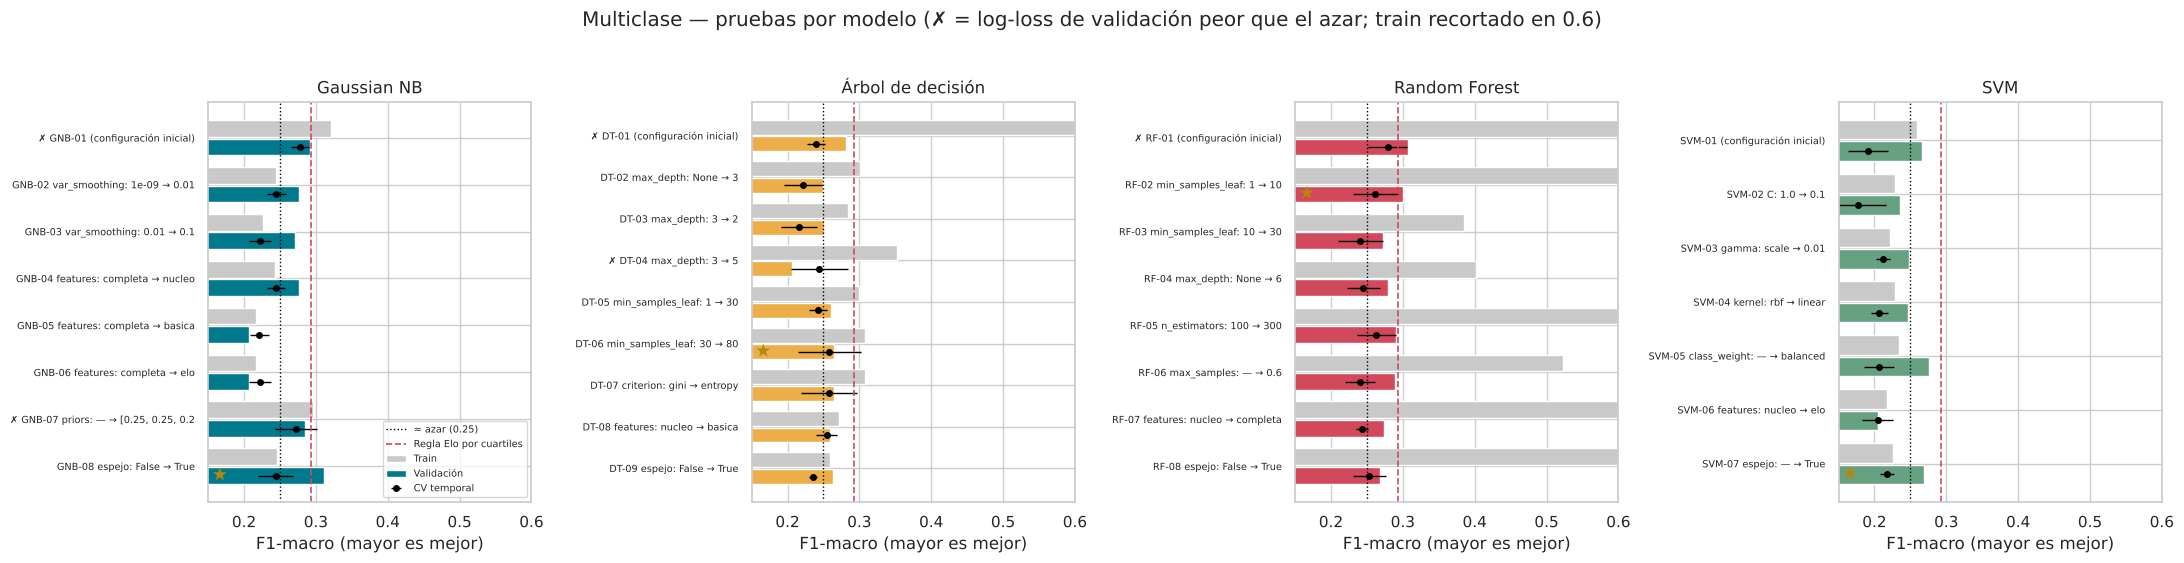

In [ ]:
#@title **TABLA Y GRÁFICA** de todas las pruebas multiclase
reg_mc = registro_df(REGISTRO_MC)
reg_mc.to_csv("registro_pruebas_multiclase_VCT.csv", index=False, encoding="utf-8-sig")
print(f"✔ {len(reg_mc)} pruebas multiclase guardadas en registro_pruebas_multiclase_VCT.csv")
display(reg_mc[["id", "referencia", "cambió", "train_f1m", "val_f1m", "cv_f1m", "val_acc", "val_ll", "apto", "val_acc_bin", "gap", "score_sel", "veredicto"]].round(4))

fig, axes = plt.subplots(1, 4, figsize=(22, 5.5), sharex=True)
for ax, m in zip(axes, NOMBRES_MC):
    g = reg_mc[reg_mc.modelo == m].reset_index(drop=True); pos = np.arange(len(g))[::-1]; mejor = max(range(len(g)), key=lambda k: (g.apto[k], g.score_sel[k]))
    ax.barh(pos + 0.2, g.train_f1m.clip(upper=0.6), height=0.36, color="#c9c9c9", label="Train")
    ax.barh(pos - 0.2, g.val_f1m, height=0.36, color=COLORES_MC[m], label="Validación")
    ax.errorbar(g.cv_f1m, pos - 0.2, xerr=g.cv_std, fmt="o", color="black", ms=4, lw=1, label="CV temporal")
    ax.axvline(0.25, color="black", ls=":", lw=1, label="≈ azar (0.25)"); ax.axvline(F1_ELO_VAL, color="#d1495b", ls="--", lw=1.2, label="Regla Elo por cuartiles")
    ax.set_yticks(pos); ax.set_yticklabels([("" if a else "✗ ") + f"{i[3:]} {c[:28]}" for i, c, a in zip(g.id, g["cambió"], g.apto)], fontsize=7)
    ax.text(0.155, pos[mejor] - 0.2, "★", va="center", fontsize=13, color="#b8860b"); ax.set_xlim(0.15, 0.6)
    ax.set_title(NOMBRES_MC[m]); ax.set_xlabel("F1-macro (mayor es mejor)")
axes[0].legend(fontsize=7, loc="lower right"); plt.suptitle("Multiclase — pruebas por modelo (✗ = log-loss de validación peor que el azar; train recortado en 0.6)", y=1.02); plt.tight_layout(); plt.show()

### 📖 Lectura de las pruebas multiclase
- **La condición "mejor que el azar" fue decisiva.** Varias configuraciones tenían buen F1-macro pero probabilidades **peores que no mirar el mapa**: el GNB con 29 variables (log-loss 1.97), el árbol sin límite (9.83), el árbol de profundidad 5 (1.66) y el Random Forest por defecto (1.42, con F1 de **0.99 en train**: memorizó). Sin esa regla habríamos elegido modelos demasiado seguros de sí mismos, que un casino no podría usar para cotizar el hándicap.
- **Gaussian NB:** suavizar las varianzas (`var_smoothing = 0.01`) bajó el log-loss de 1.97 a 1.386 (justo el azar). Con menos variables (`basica`, `elo`) el F1-macro cae a ≈ 0.21 porque el modelo solo predice las clases "cómodas" y **nunca** las "ajustadas". El espejo A↔B dio el mejor F1 de validación (0.311), pero su CV es más baja (0.244): parte de esa mejora puede ser suerte.
- **Árbol:** igual que en binaria y en regresión, lo que sirvió fue **regularizar** (profundidad 3 y hojas de 80 mapas). Queda con F1 ≈ 0.26.
- **Random Forest:** la mejor configuración apta usa hojas de ≥ 10 mapas (F1 val 0.300, CV 0.262), aunque todavía sobreajusta (F1 de train 0.64). Al regularizar más (hojas de 30, profundidad 6) el F1 **baja**, porque el bosque empieza a predecir solo las clases extremas.
- **SVM:** tiene las probabilidades más prudentes (log-loss ≈ 1.35, el mejor), pero el F1 más bajo en CV (≈ 0.19–0.22), porque casi nunca predice las clases ajustadas. `class_weight = "balanced"` lo ayudó un poco.
- **Panorama:** casi todas las configuraciones aptas quedan entre **0.25 y 0.31 de F1-macro en validación** (azar ≈ 0.25; las que solo usan el Elo bajan a ≈ 0.21), y la regla Elo por cuartiles da 0.293. Con 596 mapas, el error típico del F1 es de ≈ ±0.02, así que **las diferencias entre modelos son del tamaño del ruido**.

### 13.3 Elección de los dos mejores modelos multiclase y prueba en 2026

Mismo procedimiento que siempre: la elección se hace con el puntaje de validación + CV; después se reentrena con 2024–2025 y se evalúa **una vez** en 2026.

Además, como puente con la regresión, agregamos una **"ruta por regresión"**: con el mejor regresor y su σ (sección 12) se calcula la probabilidad de cada clase, $P(\text{B cómodo}) = \Phi\big(\frac{-4.5-\hat{y}}{\sigma}\big)$, $P(\text{B ajustado}) = \Phi\big(\frac{0-\hat{y}}{\sigma}\big) - \Phi\big(\frac{-4.5-\hat{y}}{\sigma}\big)$, etc., y se elige la clase más probable. No es un modelo nuevo: es el mismo regresor leído como clasificador.

In [ ]:
#@title **CODE:** los dos mejores modelos multiclase (decididos ANTES del test) y evaluación única en 2026
mejores_mc = {m: mejor_guiada_mc(m) for m in NOMBRES_MC}
display(pd.DataFrame([{"Modelo": NOMBRES_MC[m], "Prueba": c["id"], "val F1-macro": c["val_f1m"], "CV F1-macro": c["cv_f1m"], "val accuracy": c["val_acc"],
                       "val log-loss": c["val_ll"], "¿mejor que el azar?": "sí" if c["apto"] else "no", "val acc binaria": c["val_acc_bin"], "brecha train-val": c["gap"], "puntaje": c["score_sel"]}
                      for m, c in mejores_mc.items()]).set_index("Modelo").round(4))
TOP2_MC = sorted(mejores_mc, key=lambda m: (not mejores_mc[m]["apto"], -round(mejores_mc[m]["score_sel"], 6), mejores_mc[m]["val_ll"]))[:2]
print(f"🏆 Los dos mejores multiclase (ANTES de ver el test): 1.º {NOMBRES_MC[TOP2_MC[0]]} [{mejores_mc[TOP2_MC[0]]['id']}]  ·  2.º {NOMBRES_MC[TOP2_MC[1]]} [{mejores_mc[TOP2_MC[1]]['id']}]")
for m in NOMBRES_MC: print(f"   {NOMBRES_MC[m]:18s} -> {json.dumps(mejores_mc[m]['params'], default=str)}")

PMC_TEST = {}
for m, c in mejores_mc.items():
    est, cols = construir_mc(m, c["params"]); est.fit(X_dev[cols], c_dev); PMC_TEST[m] = est.predict_proba(X_te[cols])

def probs_clase_desde_margen(pred, sigma, u=UMBRAL_COMODO - 0.5):
    F = lambda t: stats.norm.cdf((t - np.asarray(pred)) / sigma)
    return np.column_stack([F(-u), F(0) - F(-u), F(u) - F(0), 1 - F(u)])
P_RUTA = probs_clase_desde_margen(P_TEST[GANADOR], SIGMA[GANADOR])

filas = []
for m in NOMBRES_MC:
    mt = metricas_mc(c_te, PMC_TEST[m])
    filas.append({"Modelo": NOMBRES_MC[m] + (" ★" if m in TOP2_MC else ""), "accuracy": mt["acc"], "F1-macro": mt["f1m"], "log-loss": mt["ll"], "accuracy binaria derivada": mt["acc_bin"]})
mt = metricas_mc(c_te, P_RUTA)
filas.append({"Modelo": f"Ruta por regresión ({NOMBRES[GANADOR]} regresor)", "accuracy": mt["acc"], "F1-macro": mt["f1m"], "log-loss": mt["ll"], "accuracy binaria derivada": mt["acc_bin"]})
for _, fb in bases_mc[bases_mc.Conjunto == "Test 2026"].iterrows():
    filas.append({"Modelo": "Línea base: " + fb["Línea base"], "accuracy": fb.accuracy, "F1-macro": fb["F1-macro"], "log-loss": fb["log-loss"], "accuracy binaria derivada": fb["accuracy binaria derivada"]})
test_mc = pd.DataFrame(filas).set_index("Modelo")
display(test_mc.round(4))
print(f"Referencias: azar accuracy 0.25, log-loss {np.log(4):.4f} · clasificación BINARIA en 2026 (notebook anterior): GNB 0.591")

,Prueba,val F1-macro,CV F1-macro,val accuracy,val log-loss,¿mejor que el azar?,val acc binaria,brecha train-val,puntaje
Modelo,,,,,,,,,
Gaussian NB,MC-GNB-08,0.3112,0.2441,0.3356,1.3751,sí,0.5671,-0.0655,0.2777
Árbol de decisión,MC-DT-06,0.2648,0.2577,0.3188,1.3743,sí,0.5570,0.0430,0.2613
Random Forest,MC-RF-02,0.3000,0.2618,0.3305,1.3663,sí,0.5705,0.3377,0.2809
SVM,MC-SVM-07,0.2692,0.2172,0.3305,1.3510,sí,0.5671,-0.0438,0.2432


🏆 Los dos mejores multiclase (ANTES de ver el test): 1.º Random Forest [MC-RF-02]  ·  2.º Gaussian NB [MC-GNB-08]
   Gaussian NB        -> {"features": "completa", "var_smoothing": 0.01, "espejo": true}
   Árbol de decisión  -> {"features": "nucleo", "criterion": "gini", "max_depth": 3, "min_samples_leaf": 80, "ccp_alpha": 0.0, "espejo": false}
   Random Forest      -> {"features": "nucleo", "n_estimators": 100, "max_depth": null, "min_samples_leaf": 10, "max_features": "sqrt", "espejo": false}
   SVM                -> {"features": "nucleo", "kernel": "rbf", "C": 1.0, "gamma": 0.01, "class_weight": "balanced", "espejo": true}


,accuracy,F1-macro,log-loss,accuracy binaria derivada
Modelo,,,,
Gaussian NB ★,0.3059,0.2986,1.4313,0.5835
Árbol de decisión,0.3194,0.2612,1.3854,0.5632
Random Forest ★,0.3093,0.2897,1.3936,0.5745
SVM,0.3093,0.2896,1.3738,0.5903
Ruta por regresión (Random Forest regresor),0.2777,0.2507,1.3925,0.5824
Línea base: Clase mayoritaria del entrenamiento,0.2517,0.1005,NaN,0.4718
Línea base: Frecuencias del entrenamiento (sin mirar el mapa),0.2517,0.1005,1.3888,NaN
Línea base: Regla Elo por cuartiles,0.3262,0.3090,NaN,0.5971


Referencias: azar accuracy 0.25, log-loss 1.3863 · clasificación BINARIA en 2026 (notebook anterior): GNB 0.591


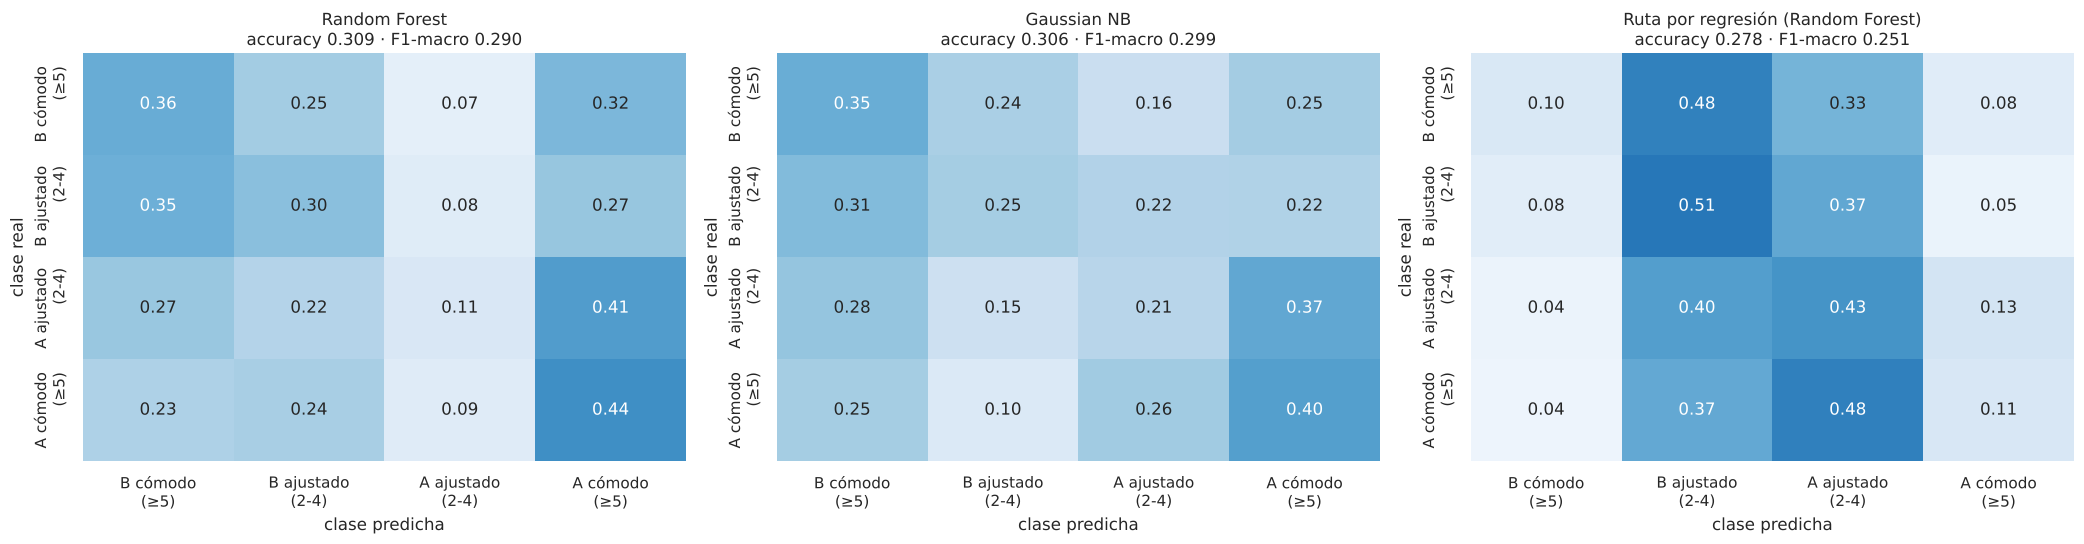

=== Random Forest — test 2026 ===
                  precision    recall  f1-score   support

   B cómodo (≥5)      0.331     0.357     0.344       249
B ajustado (2-4)      0.290     0.297     0.293       219
A ajustado (2-4)      0.280     0.108     0.156       195
   A cómodo (≥5)      0.311     0.444     0.366       223

        accuracy                          0.309       886
       macro avg      0.303     0.301     0.290       886
    weighted avg      0.305     0.309     0.295       886

=== Gaussian NB — test 2026 ===
                  precision    recall  f1-score   support

   B cómodo (≥5)      0.332     0.353     0.342       249
B ajustado (2-4)      0.329     0.247     0.282       219
A ajustado (2-4)      0.216     0.205     0.211       195
   A cómodo (≥5)      0.327     0.399     0.360       223

        accuracy                          0.306       886
       macro avg      0.301     0.301     0.299       886
    weighted avg      0.305     0.306     0.303       886



In [ ]:
#@title **GRÁFICA:** matrices de confusión en test 2026 (normalizadas por fila: de cada clase real, ¿qué predijo el modelo?)
paneles = [(NOMBRES_MC[m], PMC_TEST[m]) for m in TOP2_MC] + [(f"Ruta por regresión ({NOMBRES[GANADOR]})", P_RUTA)]
fig, axes = plt.subplots(1, 3, figsize=(21, 5.6))
etiquetas = [c.replace(" (", "\n(") for c in CLASES]
for ax, (nombre, P) in zip(axes, paneles):
    cm = confusion_matrix(c_te, P.argmax(1), labels=[0, 1, 2, 3], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=.7, cbar=False, ax=ax, xticklabels=etiquetas, yticklabels=etiquetas)
    ax.set_xlabel("clase predicha"); ax.set_ylabel("clase real")
    ax.set_title(f"{nombre}\naccuracy {accuracy_score(c_te, P.argmax(1)):.3f} · F1-macro {f1_score(c_te, P.argmax(1), average='macro', labels=[0,1,2,3], zero_division=0):.3f}")
plt.tight_layout(); plt.show()
for m in TOP2_MC:
    print(f"=== {NOMBRES_MC[m]} — test 2026 ===")
    print(classification_report(c_te, PMC_TEST[m].argmax(1), labels=[0, 1, 2, 3], target_names=CLASES, digits=3, zero_division=0))

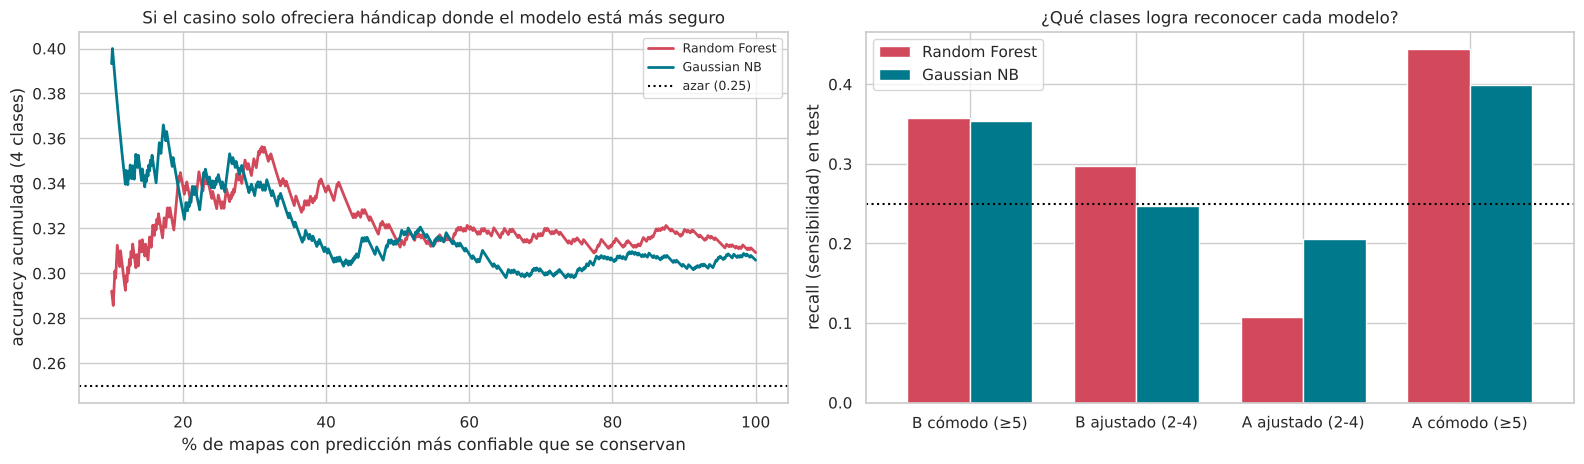

In [ ]:
#@title **GRÁFICA:** ¿a qué se puede llegar? — acierto cuando el modelo está más seguro
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
for m in TOP2_MC:
    P = PMC_TEST[m]; conf = P.max(1); orden_c = np.argsort(-conf); acierto = (P.argmax(1) == c_te.values)[orden_c]
    cubre = np.arange(1, len(acierto) + 1) / len(acierto); acc_acum = np.cumsum(acierto) / np.arange(1, len(acierto) + 1); s_ = cubre >= 0.1
    ax[0].plot(cubre[s_] * 100, acc_acum[s_], color=COLORES_MC[m], lw=2, label=NOMBRES_MC[m])
ax[0].axhline(0.25, color="black", ls=":", label="azar (0.25)"); ax[0].set_xlabel("% de mapas con predicción más confiable que se conservan"); ax[0].set_ylabel("accuracy acumulada (4 clases)")
ax[0].set_title("Si el casino solo ofreciera hándicap donde el modelo está más seguro"); ax[0].legend(fontsize=9)
rec = pd.DataFrame({NOMBRES_MC[m]: [np.mean(PMC_TEST[m].argmax(1)[c_te.values == k] == k) for k in range(4)] for m in TOP2_MC}, index=CLASES)
rec.plot.bar(ax=ax[1], color=[COLORES_MC[m] for m in TOP2_MC], width=.75); ax[1].axhline(0.25, color="black", ls=":")
ax[1].set_ylabel("recall (sensibilidad) en test"); ax[1].set_title("¿Qué clases logra reconocer cada modelo?"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

### 📖 Lectura: ¿a qué se puede llegar con la multiclase?
- **Los dos mejores multiclase (elegidos antes de ver 2026) son el Random Forest (MC-RF-02) y el Gaussian NB (MC-GNB-08).** En 2026 obtienen accuracy **0.309 y 0.306** y F1-macro **0.290 y 0.299**, frente a 0.25 del azar. Hay señal (≈ 6 puntos por encima del azar), pero poca.
- **No superan a la regla simple:** ordenar los mapas por ventaja de Elo y asignar un cuartil a cada clase da accuracy **0.326** y F1-macro **0.309**. Es la misma conclusión de la clasificación binaria y de la regresión: **los modelos reproducen la regla del Elo**.
- **Las probabilidades no sirven para cotizar 4 resultados:** en 2026 el log-loss de los modelos (1.37–1.43) queda prácticamente igual o peor que el azar (1.386). Ni siquiera la SVM, la más prudente, se aleja de forma útil.
- **Las matrices de confusión muestran dónde está el límite:** los modelos reconocen algo de las clases **"cómodas"** (recall ≈ 0.35–0.44), pero las **"ajustadas"** son casi aleatorias (el RF solo reconoce el 11 % de los "A ajustado"). Además, muchos errores ni siquiera aciertan el ganador: el 32 % de los mapas que B ganó cómodo el RF los predijo como "A cómodo". Que un mapa termine 13-11 o 13-6 depende de lo que pasa dentro del mapa, no de lo que se sabe antes.
- **Juntando clases se recupera la binaria:** la accuracy binaria derivada (0.56–0.59) es la misma del notebook de clasificación. Partir en 4 clases **no mejora** la predicción del ganador.
- **La ruta por regresión** casi siempre elige las clases "ajustadas" (accuracy 0.278). El regresor predice márgenes cercanos a 0 (el valor esperado), así que rara vez le da más probabilidad a una paliza. Confirma que la regresión sirve para el margen **promedio**, no para separar tipos de victoria.
- **Si el casino solo ofreciera hándicap en los mapas donde el modelo está más seguro**, conservando el 20–30 % más confiable el acierto sube apenas a ≈ 33–35 %. No hay una "zona segura".
- **Lo que sí se ve en los datos:** con mucha ventaja de Elo, "A cómodo" pasa de ≈ 18 % a ≈ 44 % de los mapas (gráfica de octiles). El Elo cambia las probabilidades del tipo de victoria, pero **las cuatro clases siguen siendo posibles en cualquier enfrentamiento**.
- **Conclusión:** la multiclase **se puede hacer y está justificada** por el mercado de hándicap. Con información pre-match llega a ≈ 31 % (contra 25 % del azar), pero **no aporta más que la clasificación binaria más el Elo**, y sus probabilidades no son confiables. La dejamos como análisis exploratorio, no como modelo para producción.

## 14. Conclusiones

In [ ]:
#@title **RESUMEN EJECUTIVO** (se genera con los resultados de esta ejecución)
print("=" * 100)
print(f"REGRESIÓN (objetivo: round_diff) — {len(REGISTRO)} pruebas registradas ({sum(r['tipo']=='guiada' for r in REGISTRO)} guiadas + {sum(r['tipo']=='barrido' for r in REGISTRO)} de barrido)")
print(f"{'Modelo':<20s}{'val RMSE':>10s}{'CV RMSE':>10s}{'test RMSE':>11s}{'IC 95 % test':>18s}{'test MAE':>10s}{'test R²':>9s}{'acierto ganador':>17s}")
for m in NOMBRES:
    t = afi.loc[NOMBRES[m]]; c = mejores[m]
    print(f"{NOMBRES[m]:<20s}{c['val_rmse']:>10.3f}{c['cv_rmse']:>10.3f}{t['RMSE']:>11.3f}{'['+format(t['IC95% RMSE inf'],'.3f')+', '+format(t['IC95% RMSE sup'],'.3f')+']':>18s}{t['MAE']:>10.3f}{t['R²']:>9.3f}{t['acierto ganador']:>17.3f}")
b0 = bases_reg[bases_reg.Conjunto == "Test 2026"].set_index("Línea base")
print(f"Líneas base en 2026 -> siempre 0: RMSE {b0.iloc[0].RMSE:.3f} · regla Elo por deciles: RMSE {b0.iloc[2].RMSE:.3f}, acierto ganador {b0.iloc[2]['acierto ganador']:.3f}")
print(f"Dos mejores de regresión (elegidos antes del test): {NOMBRES[TOP2[0]]} y {NOMBRES[TOP2[1]]}")
print("-" * 100)
print(f"MULTICLASE (4 clases por margen, umbral {UMBRAL_COMODO} rondas) — {len(REGISTRO_MC)} pruebas registradas")
print(f"{'Modelo':<44s}{'accuracy':>10s}{'F1-macro':>10s}{'log-loss':>10s}{'acc binaria':>13s}")
for idx_, fila_ in test_mc.iterrows():
    print(f"{idx_[:43]:<44s}{fila_['accuracy']:>10.3f}{fila_['F1-macro']:>10.3f}{fila_['log-loss']:>10.3f}{fila_['accuracy binaria derivada']:>13.3f}")
print(f"Dos mejores multiclase (elegidos antes del test): {NOMBRES_MC[TOP2_MC[0]]} y {NOMBRES_MC[TOP2_MC[1]]}")
print("=" * 100)

REGRESIÓN (objetivo: round_diff) — 118 pruebas registradas (39 guiadas + 79 de barrido)
Modelo                val RMSE   CV RMSE  test RMSE      IC 95 % test  test MAE  test R²  acierto ganador
Árbol de decisión        5.826     5.848      5.904    [5.707, 6.107]     5.067    0.015            0.570
Random Forest            5.820     5.815      5.874    [5.677, 6.073]     5.089    0.025            0.582
SVR                      5.831     5.808      5.873    [5.667, 6.080]     5.009    0.026            0.581
Líneas base en 2026 -> siempre 0: RMSE 5.955 · regla Elo por deciles: RMSE 5.858, acierto ganador 0.585
Dos mejores de regresión (elegidos antes del test): Random Forest y SVR
----------------------------------------------------------------------------------------------------
MULTICLASE (4 clases por margen, umbral 5 rondas) — 32 pruebas registradas
Modelo                                        accuracy  F1-macro  log-loss  acc binaria
Gaussian NB ★                                   

### Qué aprendimos

**1. ¿Cómo hacer regresión con una variable objetivo discreta?** No se cambian las variables de entrada sino la variable objetivo: pasamos de `team_a_wins` (0/1) a **`round_diff`**, un resultado **real** y numérico cuyo signo dice quién ganó y cuyo tamaño dice por cuánto. Las probabilidades del clasificador **no** pueden ser la variable objetivo, porque no son un dato observado.

**2. Regresión — los dos mejores modelos: Random Forest regresor y SVR** (elegidos con validación + CV temporal, antes de ver 2026).
- En 2026: RMSE ≈ **5.87 rondas**, MAE ≈ 5.0–5.1, R² ≈ **0.025**. Superan con significancia a "siempre 0" (5.96), pero **empatan con la regla Elo por deciles** (5.86) y entre sí.
- **Afinar fue indispensable:** por defecto, el árbol (R² = −1.04) y el Random Forest (R² = −0.04) eran peores que predecir 0. Lo que más ayudó fue regularizar: árboles poco profundos, hojas grandes, `C` y `gamma` bajos y un tubo ε de 1 ronda.
- **El R² bajo no es un modelo mal entrenado:** el modelo predice el margen *esperado* y la mayor parte del margen se decide dentro del mapa. Las curvas de aprendizaje son planas: el límite está en la **información**, no en la cantidad de datos.
- **Del margen a la cuota:** con $P = \Phi(\hat{y}/\sigma)$, el SVR da las mejores probabilidades de todo el proyecto (log-loss 0.674, Brier 0.241 en 2026). Además permite cotizar el **hándicap**, que la clasificación binaria no puede.

**3. Multiclase — los dos mejores: Random Forest y Gaussian NB.** Con 4 clases (umbral de 5 rondas, coherente con el hándicap −4.5) llegan a ≈ **31 % de accuracy** (azar 25 %) y F1-macro ≈ 0.29–0.30. **No superan** a la regla Elo por cuartiles, no distinguen las victorias ajustadas y sus probabilidades quedan al nivel del azar. Es posible pero **no es eficiente**: no aporta más que la binaria.

**4. La conclusión de todo el proyecto.** Tres formas de plantear el problema (¿quién gana?, ¿por cuántas rondas?, ¿quién gana y por cuánto?) y siete algoritmos llegan **al mismo techo**, el que marca el Elo: ≈ 59 % para el ganador, R² ≈ 0.03 para el margen y ≈ 31 % para las 4 clases. Con estadísticas del propio mapa los modelos superan el 95 %, pero eso es *data leakage*: un casino no tiene esos datos antes del mapa. **El límite no está en los modelos sino en lo poco que se sabe antes de que empiece un mapa de VALORANT.**

### Limitaciones
- No hay fecha: el orden cronológico se reconstruye con los IDs de vlr.gg. No se modelan cambios de *roster*, parches ni jugadores ausentes.
- La validación tiene solo 596 mapas (error típico del RMSE ≈ ±0.13 rondas; del F1 ≈ ±0.02).
- La conversión margen → probabilidad supone errores normales, y los residuos reales son bimodales.
- El umbral de la multiclase (5 rondas) se eligió por balance de clases y por el mercado de hándicap, no se optimizó.
